# Hourly Electricity Consumption Data Inspection

## Objective

This notebook investigates the main hourly household electricity consumption dataset from the iFlex experiment.

## Inspection Goals

1. Identify the number of columns.
2. Understand the column names and data types.
3. Inspect a sample of records.
4. Estimate the dataset size.
5. Check missing values and data quality.
6. Understand household identifiers and hourly observations.

## Data Handling Strategy

The original dataset is large. Initial inspection will use small samples and memory-efficient reading methods.

The raw dataset will remain unchanged.

In [13]:
import pandas as pd
from pathlib import Path
import os

# Dataset path
file_path = Path("../data/raw/data_hourly.csv")

# Check file size
file_size_gb = os.path.getsize(file_path) / (1024 ** 3)

print(f"File size: {file_size_gb:.2f} GB")

# Read only the first 10 rows
sample = pd.read_csv(file_path, nrows=10)

print("\nCOLUMN NAMES:")
print(sample.columns.tolist())

print("\nFIRST 10 ROWS:")
display(sample)

print("\nDATA TYPES:")
print(sample.dtypes)

File size: 0.98 GB

COLUMN NAMES:
['ID', 'From', 'Date', 'Hour', 'Participation_Phase', 'Demand_kWh', 'Price_signal', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72']

FIRST 10 ROWS:


,ID,From,Date,Hour,Participation_Phase,Demand_kWh,Price_signal,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72
0,Exp_43,2020-02-01T00:00:00Z,2020-02-01,1,Phase_1,0.348,NaN,NaN,7.6,6.1,5.0,4.4
1,Exp_43,2020-02-01T01:00:00Z,2020-02-01,2,Phase_1,0.589,NaN,NaN,8.2,6.2,5.1,4.4
2,Exp_43,2020-02-01T02:00:00Z,2020-02-01,3,Phase_1,0.358,NaN,NaN,8.4,6.3,5.3,4.5
3,Exp_43,2020-02-01T03:00:00Z,2020-02-01,4,Phase_1,0.582,NaN,NaN,8.4,6.4,5.4,4.5
4,Exp_43,2020-02-01T04:00:00Z,2020-02-01,5,Phase_1,0.364,NaN,NaN,8.2,6.5,5.5,4.6
5,Exp_43,2020-02-01T05:00:00Z,2020-02-01,6,Phase_1,0.337,NaN,NaN,8.0,6.6,5.6,4.7
6,Exp_43,2020-02-01T06:00:00Z,2020-02-01,7,Phase_1,0.621,NaN,NaN,8.1,6.7,5.7,4.7
7,Exp_43,2020-02-01T07:00:00Z,2020-02-01,8,Phase_1,2.120,NaN,NaN,8.1,6.8,5.8,4.8
8,Exp_43,2020-02-01T08:00:00Z,2020-02-01,9,Phase_1,3.847,NaN,NaN,7.6,6.9,5.9,4.9
9,Exp_43,2020-02-01T09:00:00Z,2020-02-01,10,Phase_1,3.516,NaN,NaN,7.4,6.9,6.0,5.0



DATA TYPES:
ID                              str
From                            str
Date                            str
Hour                          int64
Participation_Phase             str
Demand_kWh                  float64
Price_signal                float64
Experiment_price_NOK_kWh    float64
Temperature                 float64
Temperature24               float64
Temperature48               float64
Temperature72               float64
dtype: object


In [14]:
print(sample.to_string(index=False))

    ID                 From       Date  Hour Participation_Phase  Demand_kWh  Price_signal  Experiment_price_NOK_kWh  Temperature  Temperature24  Temperature48  Temperature72
Exp_43 2020-02-01T00:00:00Z 2020-02-01     1             Phase_1       0.348           NaN                       NaN          7.6            6.1            5.0            4.4
Exp_43 2020-02-01T01:00:00Z 2020-02-01     2             Phase_1       0.589           NaN                       NaN          8.2            6.2            5.1            4.4
Exp_43 2020-02-01T02:00:00Z 2020-02-01     3             Phase_1       0.358           NaN                       NaN          8.4            6.3            5.3            4.5
Exp_43 2020-02-01T03:00:00Z 2020-02-01     4             Phase_1       0.582           NaN                       NaN          8.4            6.4            5.4            4.5
Exp_43 2020-02-01T04:00:00Z 2020-02-01     5             Phase_1       0.364           NaN                       NaN         

In [15]:
# Read the large CSV in smaller batches
chunk_size = 100_000

total_rows = 0
missing_counts = None
unique_ids = set()
phase_counts = {}
date_min = None
date_max = None

for chunk in pd.read_csv(file_path, chunksize=chunk_size):

    total_rows += len(chunk)

    # Count missing values
    if missing_counts is None:
        missing_counts = chunk.isna().sum()
    else:
        missing_counts += chunk.isna().sum()

    # Count unique household IDs
    unique_ids.update(chunk["ID"].dropna().unique())

    # Count records in each participation phase
    counts = chunk["Participation_Phase"].value_counts()
    for phase, count in counts.items():
        phase_counts[phase] = phase_counts.get(phase, 0) + count

    # Track date range
    chunk_min = chunk["Date"].min()
    chunk_max = chunk["Date"].max()

    date_min = chunk_min if date_min is None else min(date_min, chunk_min)
    date_max = chunk_max if date_max is None else max(date_max, chunk_max)

print("TOTAL ROWS:", total_rows)
print("UNIQUE HOUSEHOLD IDs:", len(unique_ids))
print("DATE RANGE:", date_min, "to", date_max)

print("\nRECORDS BY PARTICIPATION PHASE:")
print(phase_counts)

print("\nMISSING VALUES BY COLUMN:")
print(missing_counts)

TOTAL ROWS: 13515600
UNIQUE HOUSEHOLD IDs: 4429
DATE RANGE: 2020-01-06 to 2021-03-26

RECORDS BY PARTICIPATION PHASE:
{'Phase_1': 1335600, 'Phase_2': 12180000}

MISSING VALUES BY COLUMN:
ID                                 0
From                               0
Date                               0
Hour                               0
Participation_Phase                0
Demand_kWh                         0
Price_signal                11986392
Experiment_price_NOK_kWh    11986392
Temperature                        0
Temperature24                      0
Temperature48                      0
Temperature72                      0
dtype: int64


In [10]:
# Investigate price availability by experiment phase

price_counts = {}
price_signal_values = set()
price_values_min = None
price_values_max = None
households_with_price = set()

for chunk in pd.read_csv(file_path, chunksize=100_000):

    # Count records with and without experimental prices by phase
    for phase, group in chunk.groupby("Participation_Phase"):

        if phase not in price_counts:
            price_counts[phase] = {
                "total": 0,
                "with_price": 0,
                "without_price": 0
            }

        total = len(group)
        with_price = group["Experiment_price_NOK_kWh"].notna().sum()

        price_counts[phase]["total"] += total
        price_counts[phase]["with_price"] += with_price
        price_counts[phase]["without_price"] += total - with_price

    # Collect distinct non-missing signal values
    valid = chunk["Price_signal"].notna()

    price_signal_values.update(
        chunk.loc[valid, "Price_signal"].unique()
    )

    # Track households with experimental price records
    households_with_price.update(
        chunk.loc[valid, "ID"].unique()
    )

    # Track experimental price range
    prices = chunk["Experiment_price_NOK_kWh"].dropna()

    if not prices.empty:
        chunk_min = prices.min()
        chunk_max = prices.max()

        price_values_min = (
            chunk_min if price_values_min is None
            else min(price_values_min, chunk_min)
        )

        price_values_max = (
            chunk_max if price_values_max is None
            else max(price_values_max, chunk_max)
        )

print("PRICE RECORDS BY PHASE:")
for phase, counts in price_counts.items():
    print(f"\n{phase}:")
    print(counts)

print("\nUNIQUE NON-MISSING PRICE_SIGNAL VALUES:")
print(len(price_signal_values))
print(sorted(price_signal_values)[:30])

print("\nHOUSEHOLDS WITH EXPERIMENTAL PRICE RECORDS:")
print(len(households_with_price))

print("\nEXPERIMENTAL PRICE RANGE (NOK/kWh):")
print(price_values_min, "to", price_values_max)

PRICE RECORDS BY PHASE:

Phase_1:
{'total': 1335600, 'with_price': np.int64(68448), 'without_price': np.int64(1267152)}

Phase_2:
{'total': 12180000, 'with_price': np.int64(1460760), 'without_price': np.int64(10719240)}

UNIQUE NON-MISSING PRICE_SIGNAL VALUES:
14
['A_10', 'A_5', 'B_10', 'B_15', 'B_2', 'B_5', 'C', 'P0_10', 'P0_2', 'P0_30', 'P_10', 'P_15', 'P_2', 'P_5']

HOUSEHOLDS WITH EXPERIMENTAL PRICE RECORDS:
3133

EXPERIMENTAL PRICE RANGE (NOK/kWh):
0.0 to 30.15


In [11]:
# Count unique households by phase and price availability

households_by_phase = {}
households_with_price_by_phase = {}

for chunk in pd.read_csv(file_path, chunksize=100_000):

    for phase, group in chunk.groupby("Participation_Phase"):

        if phase not in households_by_phase:
            households_by_phase[phase] = set()
            households_with_price_by_phase[phase] = set()

        households_by_phase[phase].update(
            group["ID"].dropna().unique()
        )

        households_with_price_by_phase[phase].update(
            group.loc[
                group["Price_signal"].notna(), "ID"
            ].dropna().unique()
        )

print("HOUSEHOLD COVERAGE BY PHASE:")

for phase in households_by_phase:
    total = len(households_by_phase[phase])
    with_price = len(households_with_price_by_phase[phase])
    without_price = total - with_price

    print(f"\n{phase}")
    print("Total households:", total)
    print("Households with experimental prices:", with_price)
    print("Households without experimental prices:", without_price)

HOUSEHOLD COVERAGE BY PHASE:

Phase_1
Total households: 742
Households with experimental prices: 439
Households without experimental prices: 303

Phase_2
Total households: 4375
Households with experimental prices: 3103
Households without experimental prices: 1272


In [12]:
# Check whether households appear in both phases

phase_1_ids = set()
phase_2_ids = set()

for chunk in pd.read_csv(file_path, chunksize=100_000):

    phase_1_ids.update(
        chunk.loc[
            chunk["Participation_Phase"] == "Phase_1", "ID"
        ].dropna().unique()
    )

    phase_2_ids.update(
        chunk.loc[
            chunk["Participation_Phase"] == "Phase_2", "ID"
        ].dropna().unique()
    )

common_ids = phase_1_ids.intersection(phase_2_ids)

only_phase_1 = phase_1_ids - phase_2_ids
only_phase_2 = phase_2_ids - phase_1_ids

print("Households in Phase 1:", len(phase_1_ids))
print("Households in Phase 2:", len(phase_2_ids))
print("Households in both phases:", len(common_ids))
print("Only in Phase 1:", len(only_phase_1))
print("Only in Phase 2:", len(only_phase_2))
print("Total unique households:", len(phase_1_ids.union(phase_2_ids)))

Households in Phase 1: 742
Households in Phase 2: 4375
Households in both phases: 688
Only in Phase 1: 54
Only in Phase 2: 3687
Total unique households: 4429


## 6. Full Dataset Inspection Findings

### Dataset Overview

The hourly electricity consumption dataset contains:

- Total hourly records: 13,515,600
- Unique household IDs: 4,429
- Date range: 2020-01-06 to 2021-03-26
- Total columns: 12
- File size: approximately 0.98 GB

### Experiment Phase Distribution

| Phase | Hourly records | Households |
|---|---:|---:|
| Phase 1 | 1,335,600 | 742 |
| Phase 2 | 12,180,000 | 4,375 |

### Missing Value Analysis

The following columns have no missing values:

- ID
- From
- Date
- Hour
- Participation_Phase
- Demand_kWh
- Temperature
- Temperature24
- Temperature48
- Temperature72

The columns `Price_signal` and `Experiment_price_NOK_kWh` each contain 11,986,392 missing values.

These missing values have not been replaced or removed. Their meaning requires further investigation.

### Experimental Price Coverage

- Records with experimental prices: 1,529,208
- Records without experimental prices: 11,986,392
- Number of distinct price signals: 14
- Experimental price range: 0.00–30.15 NOK/kWh

### Household Coverage

| Measure | Phase 1 | Phase 2 |
|---|---:|---:|
| Total households | 742 | 4,375 |
| Households with experimental prices | 439 | 3,103 |
| Households without experimental prices | 303 | 1,272 |

### Household Overlap Between Phases

- Households in both phases: 688
- Only in Phase 1: 54
- Only in Phase 2: 3,687
- Total unique households: 4,429

### Initial Research Implications

1. The dataset contains repeated hourly observations for households.
2. Some households appear in both experiment phases.
3. Experimental price information is available for only a subset of hourly records.
4. Missing experimental prices must not automatically be interpreted as zero prices or control-group membership.
5. Household-level dependence should be considered when selecting the causal estimation method.
6. The experiment assignment mechanism and group information must be examined before finalizing the treatment and control definitions.

### Current Status

The large hourly dataset has been inspected using chunk-based reading. The original raw CSV remains unchanged.

No causal effect has been estimated at this stage.

## 7. Experiment-Day Household Analysis

### Example Experiment Day: 11 February 2020

The experiment-day reference file identifies 11 February 2020 as a B_5 price-signal day associated with group H1.

The hourly consumption dataset contains the following observations for this date:

- Total hourly records: 17,808
- Unique households: 742
- Households with B_5: 219
- Households without a recorded price signal: 523

### Household-Level Comparison

| Category | Number of households |
|---|---:|
| With B_5 | 219 |
| Without B_5 | 523 |
| Present in both categories | 0 |

### Initial Interpretation

On this experiment day, households appear in only one of the two price-signal categories.

This is consistent with household-level separation for this particular date.

However, households without a recorded experimental price signal have not yet been officially classified as control households. Their experiment assignment must be verified using the experiment documentation.

### Research Implication

This example provides an initial indication that the hourly dataset can distinguish households with recorded experimental price signals from households without them on an experiment day.

Further investigation is required across other experiment dates and groups before defining the treatment and control variables.

In [19]:
# Compare B_5 households with the experiment-day group

h1_ids = set(
    day_data.loc[
        day_data["Price_signal"] == "B_5", "ID"
    ].unique()
)

print("Households with B_5:", len(h1_ids))

print("\nSample household IDs:")
print(sorted(h1_ids)[:20])

print("\nExperiment-day reference:")
display(
    experiment_days[
        (experiment_days["Date"] == "2020-02-11") &
        (experiment_days["Price_signal"] == "B_5")
    ]
)

Households with B_5: 219

Sample household IDs:
['Exp_1', 'Exp_10', 'Exp_100', 'Exp_101', 'Exp_102', 'Exp_103', 'Exp_104', 'Exp_105', 'Exp_106', 'Exp_107', 'Exp_108', 'Exp_109', 'Exp_11', 'Exp_110', 'Exp_111', 'Exp_112', 'Exp_113', 'Exp_114', 'Exp_115', 'Exp_116']

Experiment-day reference:


NameError: name 'experiment_days' is not defined

In [ ]:
import pandas as pd
from pathlib import Path

# Restore file path
file_path = Path("../data/raw/data_hourly.csv")

# Select experiment date
experiment_date = "2020-02-11"

# Read only matching records using chunks
day_records = []

for chunk in pd.read_csv(file_path, chunksize=100_000):

    matching_rows = chunk[
        chunk["Date"] == experiment_date
    ]

    if not matching_rows.empty:
        day_records.append(matching_rows)

day_data = pd.concat(day_records, ignore_index=True)

print("Experiment-day data restored!")
print("Total records:", len(day_data))
print("Unique households:", day_data["ID"].nunique())

Experiment-day data restored!
Total records: 17808
Unique households: 742


In [22]:
# Identify households receiving B_5

h1_ids = set(
    day_data.loc[
        day_data["Price_signal"] == "B_5", "ID"
    ].unique()
)

print("Households with B_5:", len(h1_ids))

print("\nSample household IDs:")
print(sorted(h1_ids)[:20])

print("\nExperiment-day reference:")
display(
    experiment_days[
        (experiment_days["Date"] == "2020-02-11") &
        (experiment_days["Price_signal"] == "B_5")
    ]
)

Households with B_5: 219

Sample household IDs:
['Exp_1', 'Exp_10', 'Exp_100', 'Exp_101', 'Exp_102', 'Exp_103', 'Exp_104', 'Exp_105', 'Exp_106', 'Exp_107', 'Exp_108', 'Exp_109', 'Exp_11', 'Exp_110', 'Exp_111', 'Exp_112', 'Exp_113', 'Exp_114', 'Exp_115', 'Exp_116']

Experiment-day reference:


,Participation_Phase,Price_signal,Date,Group
5,Phase_1,B_5,2020-02-11,H1


In [23]:
# Load experiment-day reference data

experiment_days = pd.read_csv(
    "../data/raw/experiment_days.csv"
)

# Convert Date into consistent date format
experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"]
).dt.strftime("%Y-%m-%d")

print("Experiment-day reference loaded!")
print("Total records:", len(experiment_days))

Experiment-day reference loaded!
Total records: 267


In [24]:
# Check hourly observations for households receiving B_5

b5_data = day_data[
    day_data["Price_signal"] == "B_5"
]

hours_per_household = b5_data.groupby("ID")["Hour"].agg(
    ["count", "nunique", "min", "max"]
)

print("Number of households:", len(hours_per_household))

print("\nHourly observation summary:")
print(hours_per_household.describe())

print("\nHouseholds with exactly 24 records:")
print((hours_per_household["count"] == 24).sum())

print("\nHouseholds with fewer or more than 24 records:")
print((hours_per_household["count"] != 24).sum())

Number of households: 219

Hourly observation summary:
       count  nunique    min    max
count  219.0    219.0  219.0  219.0
mean    24.0     24.0    1.0   24.0
std      0.0      0.0    0.0    0.0
min     24.0     24.0    1.0   24.0
25%     24.0     24.0    1.0   24.0
50%     24.0     24.0    1.0   24.0
75%     24.0     24.0    1.0   24.0
max     24.0     24.0    1.0   24.0

Households with exactly 24 records:
219

Households with fewer or more than 24 records:
0


## 8. Hourly Observation Completeness Check

### Experiment Day

- Date: 11 February 2020
- Participation phase: Phase 1
- Price signal: B_5
- Reference group: H1

### Results

A total of 219 households had the B_5 price signal recorded on this date.

The hourly observation completeness check produced the following results:

| Measure | Result |
|---|---:|
| Households checked | 219 |
| Expected observations per household | 24 |
| Households with exactly 24 observations | 219 |
| Households with incomplete observations | 0 |
| Hours covered | 1–24 |

### Interpretation

All 219 households with the B_5 signal had complete hourly observations for the experiment day.

Each household had exactly 24 records, covering all 24 hours.

This indicates complete hourly coverage for the selected household-day observations.

### Limitation

This check covers only one experiment day and one price signal. Similar checks are required for other experiment days before making conclusions about the complete dataset.

No causal effect has been estimated.

In [25]:
# Check hourly observations for households without a price signal

no_signal_data = day_data[
    day_data["Price_signal"].isna()
]

hours_without_signal = no_signal_data.groupby("ID")["Hour"].agg(
    ["count", "nunique", "min", "max"]
)

print("Number of households:", len(hours_without_signal))

print("\nHourly observation summary:")
print(hours_without_signal.describe())

print("\nHouseholds with exactly 24 records:")
print((hours_without_signal["count"] == 24).sum())

print("\nHouseholds with fewer or more than 24 records:")
print((hours_without_signal["count"] != 24).sum())

Number of households: 523

Hourly observation summary:
       count  nunique    min    max
count  523.0    523.0  523.0  523.0
mean    24.0     24.0    1.0   24.0
std      0.0      0.0    0.0    0.0
min     24.0     24.0    1.0   24.0
25%     24.0     24.0    1.0   24.0
50%     24.0     24.0    1.0   24.0
75%     24.0     24.0    1.0   24.0
max     24.0     24.0    1.0   24.0

Households with exactly 24 records:
523

Households with fewer or more than 24 records:
0


## 9. Hourly Completeness Comparison

### Experiment Day: 11 February 2020

The hourly completeness of households with and without a recorded experimental price signal was examined.

### Results

| Measure | With B_5 | Without recorded price |
|---|---:|---:|
| Households | 219 | 523 |
| Hourly records | 5,256 | 12,552 |
| Households with exactly 24 records | 219 | 523 |
| Households with incomplete records | 0 | 0 |

### Interpretation

Both categories have complete hourly observations for the selected experiment day.

All 742 households have exactly 24 observations, covering hours 1 through 24.

This provides a suitable basis for descriptive comparison of hourly electricity consumption on this date.

### Research Limitation

Households without recorded experimental prices have not yet been confirmed as the official control group. Their assignment status must be verified using the experiment documentation.

The findings apply only to the selected experiment day and should not yet be generalized to all experiment days.

No causal effect has been estimated.

AVERAGE HOURLY ELECTRICITY CONSUMPTION:


Category,B_5 signal recorded,No price signal recorded
Hour,,
1,2.315,2.222
2,2.172,2.097
3,2.119,2.091
4,2.156,2.083
5,2.162,2.106
6,2.283,2.183
7,2.623,2.441
8,2.831,2.739
9,2.680,2.638


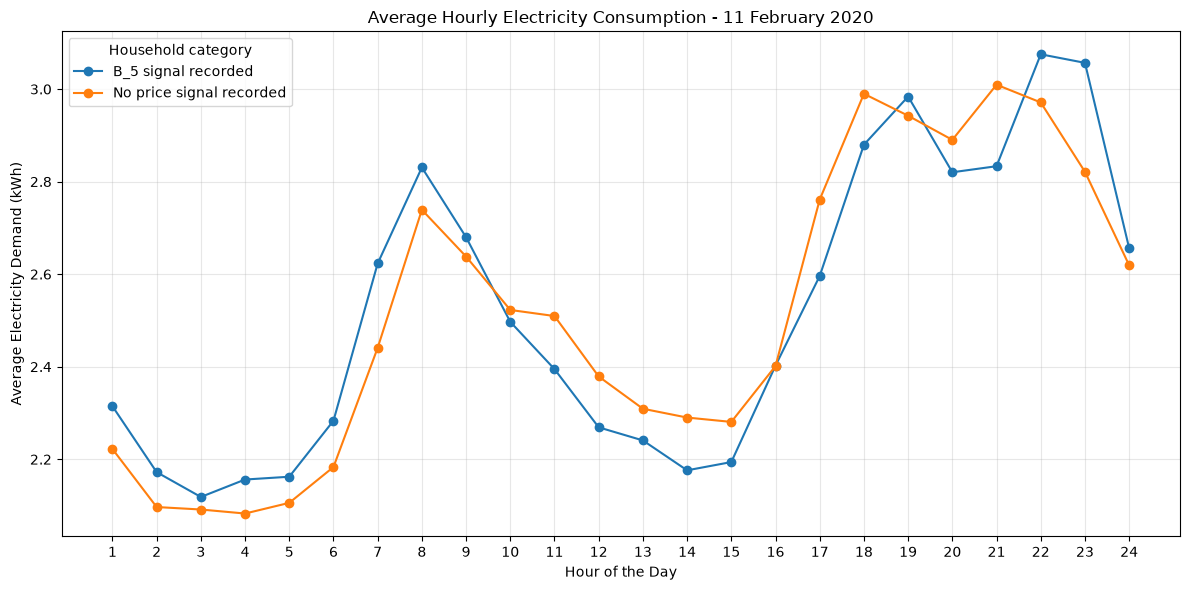

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset location
file_path = Path("../data/raw/data_hourly.csv")

# Load only records for the selected experiment day
experiment_date = "2020-02-11"
day_records = []

for chunk in pd.read_csv(file_path, chunksize=100_000):

    matching_rows = chunk[
        chunk["Date"] == experiment_date
    ]

    if not matching_rows.empty:
        day_records.append(matching_rows)

day_data = pd.concat(day_records, ignore_index=True)

# Create descriptive categories
day_data["Category"] = day_data["Price_signal"].apply(
    lambda x: "B_5 signal recorded"
    if pd.notna(x)
    else "No price signal recorded"
)

# Calculate average consumption for each hour
hourly_comparison = day_data.groupby(
    ["Hour", "Category"]
)["Demand_kWh"].mean().unstack()

print("AVERAGE HOURLY ELECTRICITY CONSUMPTION:")
display(hourly_comparison.round(3))

# Plot the comparison
hourly_comparison.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title(
    "Average Hourly Electricity Consumption - 11 February 2020"
)
plt.xlabel("Hour of the Day")
plt.ylabel("Average Electricity Demand (kWh)")
plt.xticks(range(1, 25))
plt.grid(alpha=0.3)
plt.legend(title="Household category")
plt.tight_layout()
plt.show()

## 10. Average Hourly Electricity Consumption Comparison

### Experiment Day

- Date: 11 February 2020
- Participation phase: Phase 1
- Experimental price signal: B_5

### Household Categories

| Category | Number of households |
|---|---:|
| B_5 signal recorded | 219 |
| No experimental price signal recorded | 523 |
| Total | 742 |

### Analysis Performed

Average hourly electricity consumption was calculated for each category across all 24 hours.

A line chart was created to compare the hourly consumption patterns.

### Purpose

The comparison helps investigate whether households with a recorded experimental price signal exhibit different hourly electricity consumption patterns from households without a recorded experimental price signal.

### Research Limitation

This is a descriptive comparison for one experiment day. Differences in average consumption do not establish a causal effect.

The official treatment and control assignments must still be verified before interpreting the comparison causally.

### Current Status

The first hourly consumption comparison has been completed. Further analysis across experiment days and price signals is required.

In [27]:
# Calculate total daily electricity consumption per household

daily_consumption = day_data.groupby(
    ["ID", "Price_signal"]
)["Demand_kWh"].sum().reset_index()

# Create descriptive categories
daily_consumption["Category"] = daily_consumption[
    "Price_signal"
].apply(
    lambda x: "B_5 signal recorded"
    if pd.notna(x)
    else "No price signal recorded"
)

# Calculate average daily consumption by category
daily_comparison = daily_consumption.groupby(
    "Category"
)["Demand_kWh"].agg(
    ["mean", "median", "std", "count"]
)

print("DAILY ELECTRICITY CONSUMPTION COMPARISON:")
display(daily_comparison.round(3))

DAILY ELECTRICITY CONSUMPTION COMPARISON:


,mean,median,std,count
Category,,,,
B_5 signal recorded,60.417,56.298,38.608,219


In [28]:
print(daily_consumption["Category"].value_counts())

print("\nMissing price-signal values:")
print(daily_consumption["Price_signal"].isna().sum())

Category
B_5 signal recorded    219
Name: count, dtype: int64

Missing price-signal values:
0


In [29]:
print("Total rows:", len(day_data))

print("\nPrice signal values:")
print(day_data["Price_signal"].value_counts(dropna=False))

print("\nHouseholds:")
print(day_data["ID"].nunique())

print("\nMissing price signal values:")
print(day_data["Price_signal"].isna().sum())

Total rows: 17808

Price signal values:
Price_signal
NaN    12552
B_5     5256
Name: count, dtype: int64

Households:
742

Missing price signal values:
12552


In [30]:
# Create household categories from the original data
household_categories = (
    day_data.groupby("ID")["Price_signal"]
    .apply(lambda x: "B_5 signal recorded"
           if x.notna().any()
           else "No price signal recorded")
    .reset_index(name="Category")
)

# Calculate total daily consumption for each household
daily_totals = (
    day_data.groupby("ID")["Demand_kWh"]
    .sum()
    .reset_index(name="Daily_Demand_kWh")
)

# Combine consumption and categories
daily_consumption = daily_totals.merge(
    household_categories,
    on="ID"
)

# Compare both categories
daily_comparison = daily_consumption.groupby(
    "Category"
)["Daily_Demand_kWh"].agg(
    ["mean", "median", "std", "count"]
)

print("Corrected daily consumption comparison:")
display(daily_comparison.round(3))

Corrected daily consumption comparison:


,mean,median,std,count
Category,,,,
B_5 signal recorded,60.417,56.298,38.608,219
No price signal recorded,60.299,58.195,37.617,523


## 11. Daily Electricity Consumption Comparison

### Experiment Day
- Date: 11 February 2020
- Participation phase: Phase 1
- Experimental price signal: B_5

### Household Categories

| Category | Number of households |
|---|---:|
| B_5 signal recorded | 219 |
| No experimental price signal recorded | 523 |
| Total | 742 |

### Daily Consumption Results

| Measure | B_5 signal recorded | No signal recorded |
|---|---:|---:|
| Mean (kWh) | 60.417 | 60.299 |
| Median (kWh) | 56.298 | 58.195 |
| Standard deviation | 38.608 | 37.617 |

### Initial Observations
- Mean daily consumption was similar across the two categories.
- The mean difference was approximately 0.118 kWh.
- Median consumption was slightly lower in the B_5 category.
- Consumption variability was similar across the categories.

### Research Limitation
This is a descriptive comparison for one experiment day. Recorded signal status must not automatically be treated as verified randomized treatment assignment. These results do not establish a causal effect.

### Current Status
Daily household consumption has been calculated and compared for both categories on the selected experiment day. Further analysis across experiment days is required.

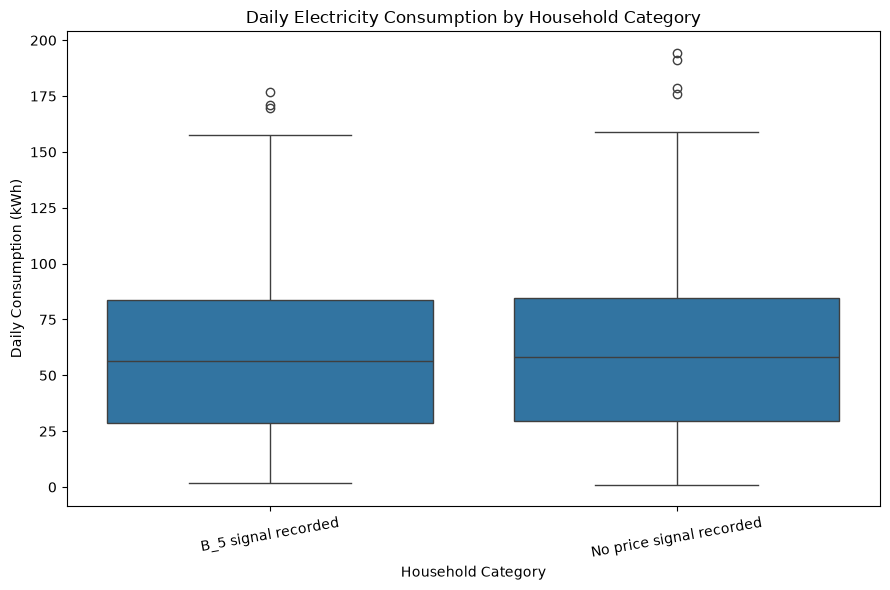

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=daily_consumption,
    x="Category",
    y="Daily_Demand_kWh"
)

plt.title("Daily Electricity Consumption by Household Category")
plt.xlabel("Household Category")
plt.ylabel("Daily Consumption (kWh)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 12. Daily Consumption Distribution Chart

### Chart Created
A box plot was created to compare total daily electricity consumption per household between:
- Households with the B_5 experimental price signal recorded.
- Households without an experimental price signal recorded.

### Purpose
The chart visualizes the distribution, median, spread, and potential outliers in daily household electricity consumption.

### Interpretation
The chart provides a visual comparison of household consumption distributions. It should be interpreted alongside the numerical summary statistics.

### Research Limitation
This comparison covers only one experiment day. It is descriptive and does not establish a causal effect of the B_5 price signal.

### Current Status
The daily consumption comparison chart has been created for the selected experiment day.

In [32]:
print("Total experiment-day records:", len(experiment_days))

print(
    "Unique experiment dates:",
    experiment_days["Date"].nunique()
)

print("\nExperiment dates by participation phase:")

print(
    experiment_days.groupby("Participation_Phase")["Date"]
    .nunique()
)

Total experiment-day records: 267
Unique experiment dates: 55

Experiment dates by participation phase:
Participation_Phase
Phase_1    11
Phase_2    44
Name: Date, dtype: int64


In [33]:
date_distribution = (
    experiment_days.groupby(
        ["Participation_Phase", "Date"]
    )
    .size()
    .reset_index(name="Group_Records")
)

print("Number of group records per experiment date:")
display(date_distribution["Group_Records"].value_counts().sort_index())

print("\nFirst 15 experiment dates:")
display(date_distribution.head(15))

Number of group records per experiment date:


Group_Records
1     18
2      9
3      4
4      1
5      2
6      2
7      1
8      3
9      1
10     5
11     5
12     4
Name: count, dtype: int64


First 15 experiment dates:


,Participation_Phase,Date,Group_Records
0,Phase_1,2020-02-11,1
1,Phase_1,2020-02-12,1
2,Phase_1,2020-02-13,2
3,Phase_1,2020-02-14,1
4,Phase_1,2020-02-19,1
5,Phase_1,2020-02-27,1
6,Phase_1,2020-03-02,1
7,Phase_1,2020-03-03,2
8,Phase_1,2020-03-04,1
9,Phase_1,2020-03-05,1


In [34]:
import pandas as pd

# Get unique experiment dates
experiment_dates = pd.to_datetime(
    experiment_days["Date"]
).dt.date.unique()

# Read only the Date column from the large hourly file
hourly_dates = pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date"]
)

hourly_dates["Date"] = pd.to_datetime(
    hourly_dates["Date"]
).dt.date

available_dates = set(hourly_dates["Date"].unique())

# Compare dates
matched_dates = [
    date for date in experiment_dates
    if date in available_dates
]

missing_dates = [
    date for date in experiment_dates
    if date not in available_dates
]

print("Total experiment dates:", len(experiment_dates))
print("Dates available in hourly data:", len(matched_dates))
print("Dates missing from hourly data:", len(missing_dates))

if missing_dates:
    print("\nMissing dates:", missing_dates)

Total experiment dates: 55
Dates available in hourly data: 55
Dates missing from hourly data: 0


In [35]:
import pandas as pd

date_household_counts = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    daily_counts = (
        chunk[chunk["Date"].isin(experiment_dates)]
        .groupby("Date")["ID"]
        .nunique()
    )

    date_household_counts.append(daily_counts)

# Combine results from all chunks
household_counts = (
    pd.concat(date_household_counts)
    .groupby(level=0)
    .sum()
)

print("Household counts across experiment dates:")
display(household_counts.describe().round(2))

print("\nFirst 15 dates:")
display(household_counts.head(15))

Household counts across experiment dates:


count      55.00
mean     3648.98
std      1466.84
min       742.00
25%      4375.00
50%      4375.00
75%      4376.00
max      4377.00
Name: ID, dtype: float64


First 15 dates:


Date
2020-02-11     742
2020-02-12     742
2020-02-13     742
2020-02-14     742
2020-02-19     742
2020-02-27     742
2020-03-02     742
2020-03-03     742
2020-03-04     743
2020-03-05     742
2020-03-09     742
2020-12-16    4377
2020-12-17    4376
2021-01-05    4376
2021-01-06    4376
Name: ID, dtype: int64

In [36]:
hourly_records = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Hour"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    counts = (
        filtered.groupby(["Date", "ID"])["Hour"]
        .agg(["count", "nunique"])
    )

    hourly_records.append(counts)

# Combine household records
all_household_hours = pd.concat(hourly_records)

# Identify household-date combinations that do not have
# exactly 24 records and 24 unique hours
incomplete = all_household_hours[
    (all_household_hours["count"] != 24) |
    (all_household_hours["nunique"] != 24)
]

print("Total household-date combinations:", len(all_household_hours))
print("Incomplete household-date combinations:", len(incomplete))

print("\nExamples of incomplete records:")
display(incomplete.head(10))

Total household-date combinations: 200694
Incomplete household-date combinations: 64

Examples of incomplete records:


count  nunique
Date       ID                     
2020-03-04 Exp_617      8        8
           Exp_617     16       16
2020-12-16 Exp_531      8        8
           Exp_531     16       16
2021-02-23 Exp_597     16       16
           Exp_597      8        8
2021-01-26 Exp_310     16       16
           Exp_310      8        8
2021-03-18 Exp_362      8        8
           Exp_362     16       16

In [37]:
# Find the household-date combinations with incomplete records
incomplete_details = (
    all_household_hours[
        (all_household_hours["count"] != 24) |
        (all_household_hours["nunique"] != 24)
    ]
    .reset_index()
)

print("Total incomplete combinations:", len(incomplete_details))

display(incomplete_details.head(20))

Total incomplete combinations: 64


,Date,ID,count,nunique
0,2020-03-04,Exp_617,8,8
1,2020-03-04,Exp_617,16,16
2,2020-12-16,Exp_531,8,8
3,2020-12-16,Exp_531,16,16
4,2021-02-23,Exp_597,16,16
5,2021-02-23,Exp_597,8,8
6,2021-01-26,Exp_310,16,16
7,2021-01-26,Exp_310,8,8
8,2021-03-18,Exp_362,8,8
9,2021-03-18,Exp_362,16,16


In [38]:
import numpy as np
import pandas as pd

hourly_records = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Hour"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    # Create a bitmask representing which hours are present
    summary = filtered.groupby(["Date", "ID"]).agg(
        record_count=("Hour", "size"),
        hour_mask=(
            "Hour",
            lambda s: sum(1 << (int(h) - 1) for h in set(s))
        )
    ).reset_index()

    hourly_records.append(summary)

# Combine records that may have been split across chunks
combined = pd.concat(hourly_records)

def combine_masks(values):
    result = 0
    for value in values:
        result |= int(value)
    return result

all_household_hours_corrected = (
    combined.groupby(["Date", "ID"])
    .agg(
        total_records=("record_count", "sum"),
        hour_mask=("hour_mask", combine_masks)
    )
)

# Count distinct hours
all_household_hours_corrected["unique_hours"] = (
    all_household_hours_corrected["hour_mask"]
    .apply(lambda x: int(x).bit_count())
)

# Identify genuinely incomplete household-date combinations
incomplete_corrected = all_household_hours_corrected[
    (all_household_hours_corrected["total_records"] != 24) |
    (all_household_hours_corrected["unique_hours"] != 24)
]

print(
    "Total household-date combinations:",
    len(all_household_hours_corrected)
)

print(
    "Genuinely incomplete combinations:",
    len(incomplete_corrected)
)

display(incomplete_corrected.head(10))

Total household-date combinations: 200662
Genuinely incomplete combinations: 0


,,total_records,hour_mask,unique_hours
Date,ID,,,


## 13. Hourly Data Completeness Validation

### Initial Finding
The first chunk-based inspection identified 64 apparently incomplete household-date combinations.

Some household records appeared as separate groups of 8 and 16 hourly observations.

### Investigation
The hourly dataset was reprocessed by combining observations across all file chunks for each household and experiment date.

### Final Results

| Measure | Result |
|---|---:|
| Household-date combinations | 200,662 |
| Incomplete combinations | 0 |
| Expected hourly observations | 24 |
| Actual unique hours per combination | 24 |

### Conclusion
All 200,662 household-date combinations contain 24 unique hourly observations.

The initial apparent gaps were caused by processing file chunks separately rather than combining records across chunks.

No household-date combinations need to be excluded because of missing hourly observations based on this check.

### Current Status
Hourly data completeness has been validated for all 55 experiment dates.

In [39]:
import pandas as pd

daily_results = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Demand_kWh"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    daily_totals = (
        filtered.groupby(["Date", "ID"])["Demand_kWh"]
        .sum()
        .reset_index()
    )

    daily_results.append(daily_totals)

# Combine partial results across chunks
daily_consumption_all = (
    pd.concat(daily_results)
    .groupby(["Date", "ID"], as_index=False)["Demand_kWh"]
    .sum()
)

print("Total household-date records:", len(daily_consumption_all))
print("Unique experiment dates:", daily_consumption_all["Date"].nunique())
print("Unique households:", daily_consumption_all["ID"].nunique())

print("\nFirst 10 records:")
display(daily_consumption_all.head(10))

Total household-date records: 200662
Unique experiment dates: 55
Unique households: 4429

First 10 records:


,Date,ID,Demand_kWh
0,2020-02-11,Exp_1,65.314
1,2020-02-11,Exp_10,89.690
2,2020-02-11,Exp_100,4.192
3,2020-02-11,Exp_101,85.246
4,2020-02-11,Exp_102,11.188
5,2020-02-11,Exp_103,14.973
6,2020-02-11,Exp_104,19.248
7,2020-02-11,Exp_105,8.487
8,2020-02-11,Exp_106,54.267
9,2020-02-11,Exp_107,89.816


In [40]:
# Calculate average and median daily consumption per date
date_consumption_summary = (
    daily_consumption_all.groupby("Date")["Demand_kWh"]
    .agg(
        mean_consumption="mean",
        median_consumption="median",
        household_count="count"
    )
    .reset_index()
)

print("Daily consumption summary across experiment dates:")
display(date_consumption_summary.head(15))

print("\nOverall summary:")
display(
    date_consumption_summary[
        ["mean_consumption", "median_consumption", "household_count"]
    ].describe().round(3)
)

Daily consumption summary across experiment dates:


,Date,mean_consumption,median_consumption,household_count
0,2020-02-11,60.333667,58.0575,742
1,2020-02-12,60.665336,57.3685,742
2,2020-02-13,62.204302,60.6410,742
3,2020-02-14,64.751761,62.8575,742
4,2020-02-19,57.491268,55.3435,742
5,2020-02-27,67.938752,65.7910,742
6,2020-03-02,60.513865,58.6395,742
7,2020-03-03,61.286809,60.4460,742
8,2020-03-04,61.290264,60.6665,742
9,2020-03-05,59.714301,57.6790,742



Overall summary:


,mean_consumption,median_consumption,household_count
count,55.000,55.000,55.000
mean,64.488,58.389,3648.400
std,8.106,7.098,1466.594
min,46.551,41.280,742.000
25%,57.479,52.897,4375.000
50%,64.752,60.446,4375.000
75%,72.218,64.470,4375.000
max,75.850,67.750,4375.000


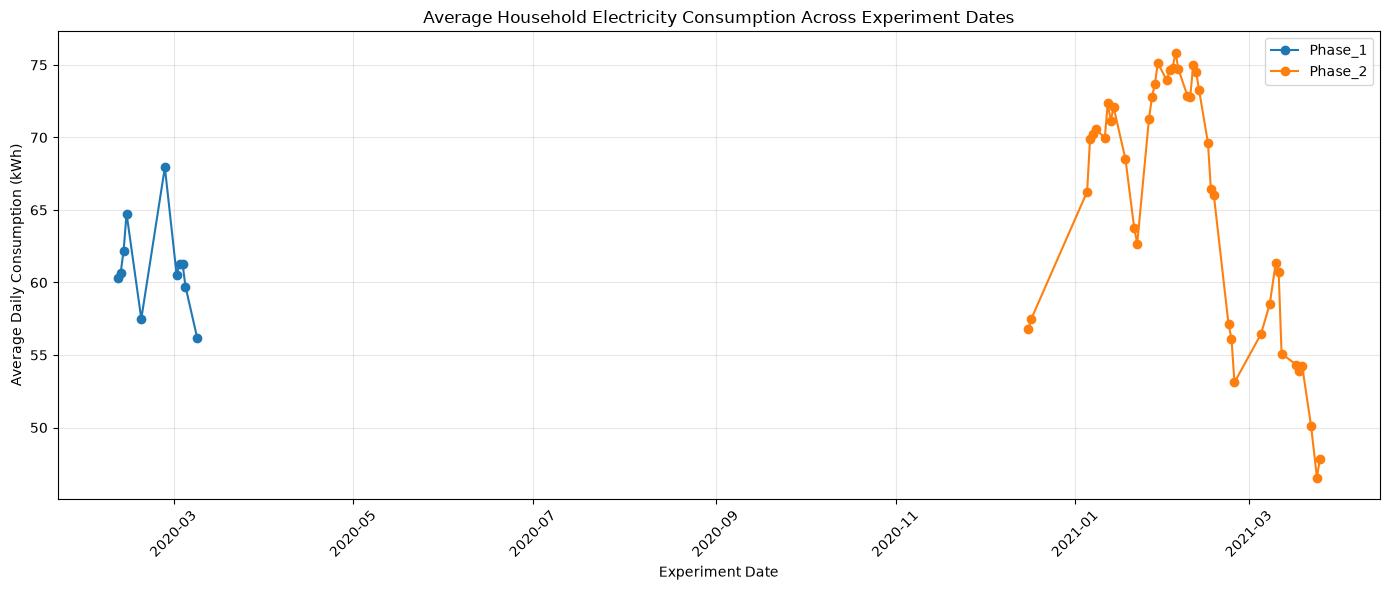

In [41]:
import matplotlib.pyplot as plt
import pandas as pd

# Attach participation phase to each experiment date
date_phase = (
    experiment_days[["Date", "Participation_Phase"]]
    .drop_duplicates()
)

date_phase["Date"] = pd.to_datetime(date_phase["Date"]).dt.date

# Merge phase information with consumption summary
trend_data = date_consumption_summary.merge(
    date_phase,
    on="Date",
    how="left"
)

trend_data["Date"] = pd.to_datetime(trend_data["Date"])

# Plot average daily consumption
plt.figure(figsize=(14, 6))

for phase in ["Phase_1", "Phase_2"]:
    phase_data = trend_data[
        trend_data["Participation_Phase"] == phase
    ]

    plt.plot(
        phase_data["Date"],
        phase_data["mean_consumption"],
        marker="o",
        label=phase
    )

plt.title("Average Household Electricity Consumption Across Experiment Dates")
plt.xlabel("Experiment Date")
plt.ylabel("Average Daily Consumption (kWh)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Average Daily Consumption Across Experiment Dates

### Analysis Performed
Average and median household electricity consumption were calculated for all 55 unique experiment dates.

The analysis covered:
- Phase 1: 11 experiment dates.
- Phase 2: 44 experiment dates.

### Summary Statistics

| Measure | Result |
|---|---:|
| Experiment dates | 55 |
| Average daily mean consumption | 64.488 kWh |
| Average daily median consumption | 58.389 kWh |
| Minimum daily mean consumption | 46.551 kWh |
| Maximum daily mean consumption | 75.850 kWh |

### Visualization
A line chart was created to display average household daily electricity consumption across experiment dates, with Phase 1 and Phase 2 shown separately.

### Initial Observations
- Average daily consumption varies across experiment dates.
- The two participation phases have substantially different household sample sizes.
- Phase 1 and Phase 2 should initially be examined separately.

### Research Limitation
Changes in average consumption across experiment dates do not establish that experimental price signals caused those changes. Weather, calendar effects, household characteristics, and experiment design must be considered.

### Current Status
Daily household consumption has been calculated for all 55 experiment dates, and a phase-separated trend chart has been created.

In [43]:
print("Experiment-day reference data:")
display(experiment_days.head(10))

print("\nUnique price signals:")
print(sorted(experiment_days["Price_signal"].dropna().unique()))

print("\nPrice signal counts:")
display(
    experiment_days["Price_signal"].value_counts()
)

Experiment-day reference data:


,Participation_Phase,Price_signal,Date,Group
0,Phase_1,A_10,2020-02-13,H1
1,Phase_1,A_10,2020-03-02,H1
2,Phase_1,A_5,2020-02-14,H1
3,Phase_1,A_5,2020-03-03,H1
4,Phase_1,B_10,2020-03-04,H1
5,Phase_1,B_5,2020-02-11,H1
6,Phase_1,C,2020-02-12,H1
7,Phase_1,C,2020-03-05,H1
8,Phase_1,P_10,2020-02-13,H2
9,Phase_1,P_10,2020-02-19,H2



Unique price signals:
['A_10', 'A_5', 'B_10', 'B_15', 'B_2', 'B_5', 'C', 'P0_10', 'P0_2', 'P0_30', 'P_10', 'P_15', 'P_2', 'P_5']

Price signal counts:


Price_signal
B_10     40
B_2      35
B_5      30
P_10     30
B_15     28
P_15     20
P_2      16
P_5      15
A_10     12
A_5      11
C        10
P0_10    10
P0_2      5
P0_30     5
Name: count, dtype: int64

In [44]:
# Check whether each date and group has only one price signal

signal_check = (
    experiment_days.groupby(
        ["Participation_Phase", "Date", "Group"]
    )["Price_signal"]
    .nunique()
    .reset_index(name="Unique_Signals")
)

multiple_signals = signal_check[
    signal_check["Unique_Signals"] > 1
]

print(
    "Total date-group combinations:",
    len(signal_check)
)

print(
    "Date-group combinations with multiple signals:",
    len(multiple_signals)
)

if len(multiple_signals) > 0:
    display(multiple_signals)
else:
    print("Each date-group combination has only one price signal.")

Total date-group combinations: 267
Date-group combinations with multiple signals: 0
Each date-group combination has only one price signal.


In [45]:
# Inspect hourly dataset column names
hourly_columns = pd.read_csv(
    "../data/raw/data_hourly.csv",
    nrows=5
)

print("Hourly dataset columns:")
print(hourly_columns.columns.tolist())

print("\nSample hourly records:")
display(hourly_columns.head())

Hourly dataset columns:
['ID', 'From', 'Date', 'Hour', 'Participation_Phase', 'Demand_kWh', 'Price_signal', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72']

Sample hourly records:


,ID,From,Date,Hour,Participation_Phase,Demand_kWh,Price_signal,Experiment_price_NOK_kWh,Temperature,Temperature24,Temperature48,Temperature72
0,Exp_43,2020-02-01T00:00:00Z,2020-02-01,1,Phase_1,0.348,NaN,NaN,7.6,6.1,5.0,4.4
1,Exp_43,2020-02-01T01:00:00Z,2020-02-01,2,Phase_1,0.589,NaN,NaN,8.2,6.2,5.1,4.4
2,Exp_43,2020-02-01T02:00:00Z,2020-02-01,3,Phase_1,0.358,NaN,NaN,8.4,6.3,5.3,4.5
3,Exp_43,2020-02-01T03:00:00Z,2020-02-01,4,Phase_1,0.582,NaN,NaN,8.4,6.4,5.4,4.5
4,Exp_43,2020-02-01T04:00:00Z,2020-02-01,5,Phase_1,0.364,NaN,NaN,8.2,6.5,5.5,4.6


In [46]:
# Check price signals by household and experiment date

signal_assignment_check = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Price_signal"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    summary = (
        filtered.groupby(["Date", "ID"])["Price_signal"]
        .nunique()
        .reset_index(name="Unique_Signals")
    )

    signal_assignment_check.append(summary)

# Combine results across chunks
signal_assignments = (
    pd.concat(signal_assignment_check)
    .groupby(["Date", "ID"])["Unique_Signals"]
    .sum()
    .reset_index()
)

print("Household-date combinations checked:", len(signal_assignments))

print("\nNumber of unique signal values per household-date:")
display(signal_assignments["Unique_Signals"].value_counts().sort_index())

Household-date combinations checked: 200662

Number of unique signal values per household-date:


Unique_Signals
0    136945
1     63708
2         9
Name: count, dtype: int64

In [47]:
# Find household-date combinations with multiple signals

multiple_signal_cases = signal_assignments[
    signal_assignments["Unique_Signals"] > 1
]

print("Household-date combinations with multiple signals:")
display(multiple_signal_cases)

# Inspect the original hourly records for these cases
multiple_details = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Hour", "Price_signal"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk.merge(
        multiple_signal_cases[["Date", "ID"]],
        on=["Date", "ID"],
        how="inner"
    )

    if not filtered.empty:
        multiple_details.append(filtered)

if multiple_details:
    multiple_details_df = pd.concat(multiple_details)

    print("\nDetailed hourly signal records:")
    display(
        multiple_details_df.sort_values(
            ["Date", "ID", "Hour"]
        )
    )
else:
    print("No detailed records found.")

Household-date combinations with multiple signals:


,Date,ID,Unique_Signals
10257,2020-12-16,Exp_3553,2
13712,2020-12-17,Exp_2721,2
54219,2021-01-18,Exp_3747,2
59308,2021-01-21,Exp_4391,2
87097,2021-02-02,Exp_1823,2
95157,2021-02-03,Exp_5163,2
117877,2021-02-11,Exp_1964,2
126774,2021-02-15,Exp_2097,2
189366,2021-03-22,Exp_3312,2



Detailed hourly signal records:


,ID,Date,Hour,Price_signal
0,Exp_3553,2020-12-16,1,B_10
1,Exp_3553,2020-12-16,2,B_10
2,Exp_3553,2020-12-16,3,B_10
3,Exp_3553,2020-12-16,4,B_10
4,Exp_3553,2020-12-16,5,B_10
...,...,...,...,...
11,Exp_3312,2021-03-22,20,B_5
12,Exp_3312,2021-03-22,21,B_5
13,Exp_3312,2021-03-22,22,B_5
14,Exp_3312,2021-03-22,23,B_5


In [48]:
# Recheck the nine household-date combinations
# using actual distinct signal values across all chunks

signal_sets = {}

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Price_signal"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk.merge(
        multiple_signal_cases[["Date", "ID"]],
        on=["Date", "ID"],
        how="inner"
    )

    for (date, household), group in filtered.groupby(["Date", "ID"]):
        key = (date, household)

        if key not in signal_sets:
            signal_sets[key] = set()

        signal_sets[key].update(
            group["Price_signal"].dropna().unique()
        )

# Display verified distinct signals
for key, signals in sorted(signal_sets.items()):
    print(
        "Date:", key[0],
        "| Household:", key[1],
        "| Actual signals:", sorted(signals)
    )

Date: 2020-12-16 | Household: Exp_3553 | Actual signals: ['B_10']
Date: 2020-12-17 | Household: Exp_2721 | Actual signals: ['A_10']
Date: 2021-01-18 | Household: Exp_3747 | Actual signals: ['P0_10']
Date: 2021-01-21 | Household: Exp_4391 | Actual signals: ['P_15']
Date: 2021-02-02 | Household: Exp_1823 | Actual signals: ['B_15']
Date: 2021-02-03 | Household: Exp_5163 | Actual signals: ['B_5']
Date: 2021-02-11 | Household: Exp_1964 | Actual signals: ['P_10']
Date: 2021-02-15 | Household: Exp_2097 | Actual signals: ['P_15']
Date: 2021-03-22 | Household: Exp_3312 | Actual signals: ['B_5']


In [2]:
import pandas as pd

# Recreate experiment dates
experiment_days = pd.read_csv(
    "../data/raw/experiment_days.csv"
)

experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"]
).dt.date

experiment_dates = experiment_days["Date"].unique()

signal_chunks = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Price_signal"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(
        chunk["Date"]
    ).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    summary = (
        filtered.groupby(["Date", "ID"])["Price_signal"]
        .agg(lambda x: tuple(x.dropna().unique()))
        .reset_index()
    )

    signal_chunks.append(summary)

# Combine records across chunks
all_signals = pd.concat(signal_chunks)

def merge_signals(values):
    return sorted({
        signal
        for group in values
        for signal in group
    })

household_signals = (
    all_signals.groupby(["Date", "ID"])["Price_signal"]
    .agg(merge_signals)
    .reset_index()
)

household_signals["Assigned_Signal"] = (
    household_signals["Price_signal"]
    .apply(lambda x: x[0] if len(x) == 1 else None)
)

household_signals["Signal_Status"] = (
    household_signals["Price_signal"]
    .apply(
        lambda x: "No signal recorded"
        if len(x) == 0
        else "One signal recorded"
        if len(x) == 1
        else "Multiple signals recorded"
    )
)

print("Household-date records:", len(household_signals))

print("\nSignal status:")
display(household_signals["Signal_Status"].value_counts())

print("\nPrice signal distribution:")
display(
    household_signals["Assigned_Signal"].value_counts(
        dropna=False
    )
)

Household-date records: 200662

Signal status:


Signal_Status
No signal recorded     136945
One signal recorded     63717
Name: count, dtype: int64


Price signal distribution:


Assigned_Signal
NaN      136945
B_10       9316
B_2        8113
P_10       7331
B_5        6821
B_15       6378
P_15       4890
P_2        3855
P_5        3577
A_10       3013
A_5        2737
P0_10      2580
C          2486
P0_2       1310
P0_30      1310
Name: count, dtype: int64

In [3]:
# Combine household-level signals and daily consumption

price_consumption = daily_consumption_all.merge(
    household_signals[
        ["Date", "ID", "Assigned_Signal", "Signal_Status"]
    ],
    on=["Date", "ID"],
    how="left"
)

print("Total combined records:", len(price_consumption))

print("\nSignal status:")
display(price_consumption["Signal_Status"].value_counts())

print("\nSample combined records:")
display(price_consumption.head(10))

print(
    "\nMissing daily consumption:",
    price_consumption["Demand_kWh"].isna().sum()
)

NameError: name 'daily_consumption_all' is not defined

In [4]:
import pandas as pd

# 1. Load experiment dates
experiment_days = pd.read_csv(
    "../data/raw/experiment_days.csv"
)

experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"]
).dt.date

experiment_dates = experiment_days["Date"].unique()

# 2. Recalculate daily household consumption
daily_chunks = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "ID", "Demand_kWh"],
    chunksize=100000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"]).dt.date

    filtered = chunk[
        chunk["Date"].isin(experiment_dates)
    ]

    totals = (
        filtered.groupby(["Date", "ID"])["Demand_kWh"]
        .sum()
        .reset_index()
    )

    daily_chunks.append(totals)

daily_consumption_all = (
    pd.concat(daily_chunks)
    .groupby(["Date", "ID"], as_index=False)["Demand_kWh"]
    .sum()
)

# 3. Combine with household price signals
price_consumption = daily_consumption_all.merge(
    household_signals[
        ["Date", "ID", "Assigned_Signal", "Signal_Status"]
    ],
    on=["Date", "ID"],
    how="left"
)

# 4. Display results
print("Total combined records:", len(price_consumption))

print("\nSignal status:")
display(price_consumption["Signal_Status"].value_counts())

print("\nSample combined records:")
display(price_consumption.head(10))

print(
    "\nMissing daily consumption:",
    price_consumption["Demand_kWh"].isna().sum()
)

Total combined records: 200662

Signal status:


Signal_Status
No signal recorded     136945
One signal recorded     63717
Name: count, dtype: int64


Sample combined records:


,Date,ID,Demand_kWh,Assigned_Signal,Signal_Status
0,2020-02-11,Exp_1,65.314,B_5,One signal recorded
1,2020-02-11,Exp_10,89.690,B_5,One signal recorded
2,2020-02-11,Exp_100,4.192,B_5,One signal recorded
3,2020-02-11,Exp_101,85.246,B_5,One signal recorded
4,2020-02-11,Exp_102,11.188,B_5,One signal recorded
5,2020-02-11,Exp_103,14.973,B_5,One signal recorded
6,2020-02-11,Exp_104,19.248,B_5,One signal recorded
7,2020-02-11,Exp_105,8.487,B_5,One signal recorded
8,2020-02-11,Exp_106,54.267,B_5,One signal recorded
9,2020-02-11,Exp_107,89.816,B_5,One signal recorded



Missing daily consumption: 0


In [5]:
# Keep households with one recorded price signal
signal_data = price_consumption[
    price_consumption["Signal_Status"] == "One signal recorded"
].copy()

# Calculate consumption statistics by price signal
signal_summary = (
    signal_data.groupby("Assigned_Signal")["Demand_kWh"]
    .agg(
        mean_consumption="mean",
        median_consumption="median",
        std="std",
        household_date_count="count"
    )
    .reset_index()
    .sort_values("mean_consumption", ascending=False)
)

print("Average daily consumption by experimental price signal:")

display(signal_summary.round(3))

Average daily consumption by experimental price signal:


,Assigned_Signal,mean_consumption,median_consumption,std,household_date_count
13,P_5,73.036,65.300,48.621,3577
11,P_15,70.181,61.625,50.063,4890
3,B_15,68.728,60.179,46.155,6378
0,A_10,67.982,60.360,47.713,3013
10,P_10,67.856,60.352,47.505,7331
5,B_5,67.400,59.310,44.988,6821
12,P_2,66.448,59.100,45.080,3855
7,P0_10,65.057,56.115,48.258,2580
4,B_2,64.396,56.286,43.966,8113
2,B_10,64.302,56.894,43.638,9316


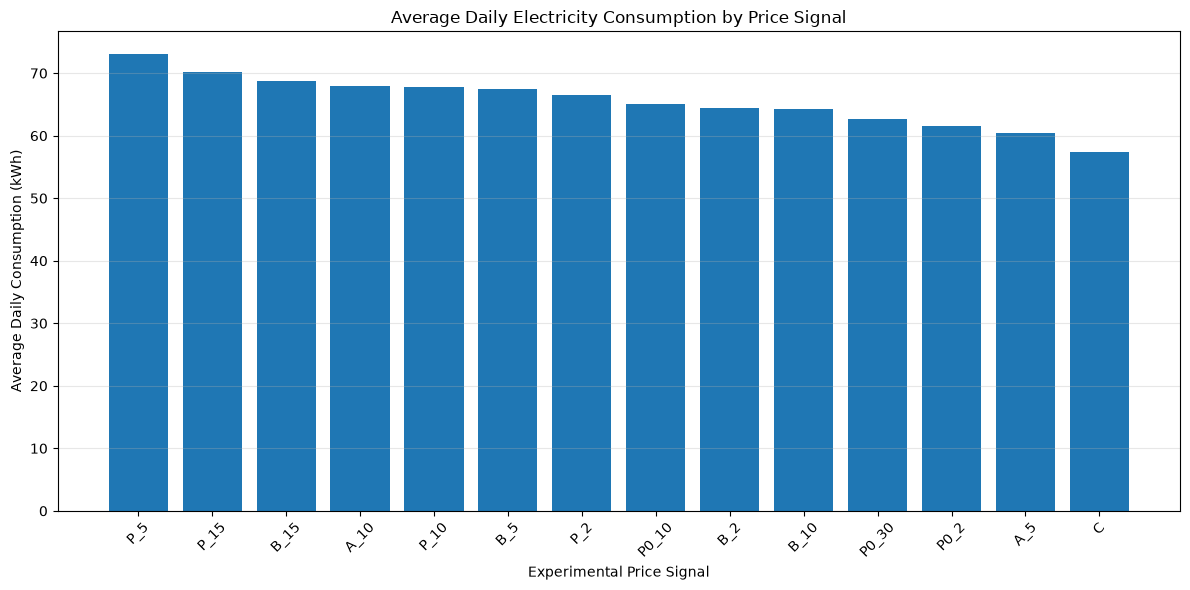

In [6]:
import matplotlib.pyplot as plt

# Sort signals from highest to lowest mean consumption
plot_data = signal_summary.sort_values(
    "mean_consumption",
    ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data["Assigned_Signal"],
    plot_data["mean_consumption"]
)

plt.title("Average Daily Electricity Consumption by Price Signal")
plt.xlabel("Experimental Price Signal")
plt.ylabel("Average Daily Consumption (kWh)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Create a date-to-phase lookup
date_phase = (
    experiment_days[["Date", "Participation_Phase"]]
    .drop_duplicates()
)

date_phase["Date"] = pd.to_datetime(
    date_phase["Date"]
).dt.date

# Check that each date belongs to only one phase
print("Unique experiment dates:", date_phase["Date"].nunique())
print("Date-phase records:", len(date_phase))

# Attach participation phase to household consumption records
price_consumption = price_consumption.merge(
    date_phase,
    on="Date",
    how="left",
    validate="many_to_one"
)

# Keep records with one recorded signal
phase_signal_data = price_consumption[
    price_consumption["Signal_Status"] == "One signal recorded"
].copy()

# Calculate consumption statistics separately by phase and signal
phase_signal_summary = (
    phase_signal_data.groupby(
        ["Participation_Phase", "Assigned_Signal"]
    )["Demand_kWh"]
    .agg(
        mean_consumption="mean",
        median_consumption="median",
        household_date_count="count"
    )
    .reset_index()
)

print("\nConsumption by phase and price signal:")
display(
    phase_signal_summary.round(3)
)

Unique experiment dates: 55
Date-phase records: 55

Consumption by phase and price signal:


,Participation_Phase,Assigned_Signal,mean_consumption,median_consumption,household_date_count
0,Phase_1,A_10,61.608,57.772,438
1,Phase_1,A_5,63.305,60.613,438
2,Phase_1,B_10,62.102,60.598,219
3,Phase_1,B_5,60.417,56.298,219
4,Phase_1,C,60.782,57.608,438
5,Phase_1,P_10,63.108,58.814,660
6,Phase_1,P_5,58.835,55.256,440
7,Phase_2,A_10,69.066,60.950,2575
8,Phase_2,A_5,59.791,50.470,2299
9,Phase_2,B_10,64.355,56.830,9097


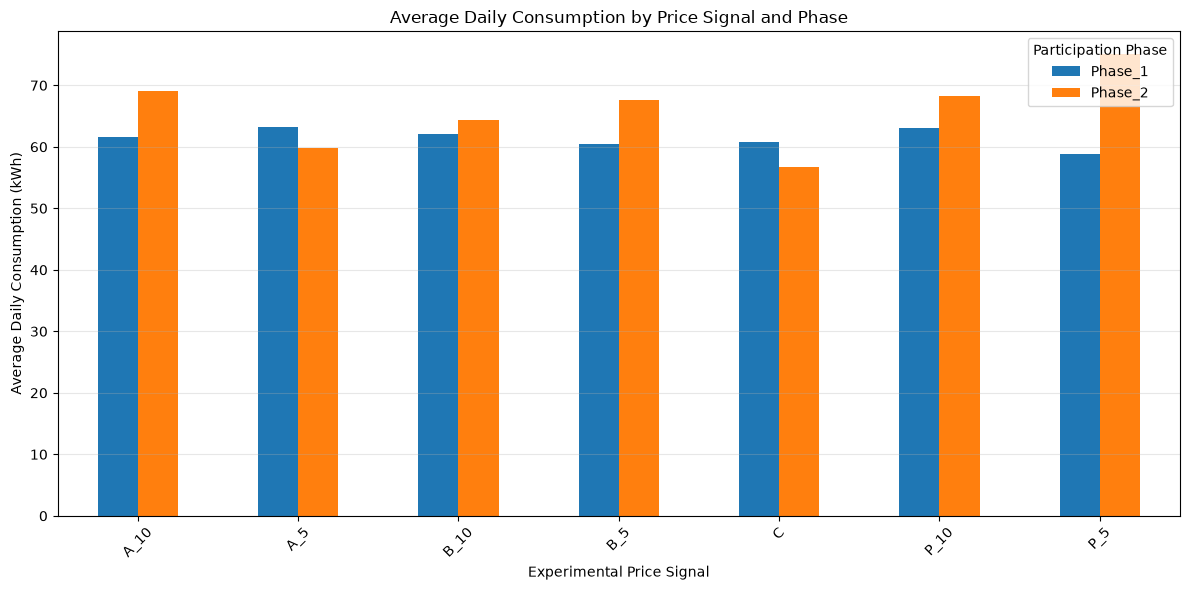

In [8]:
import matplotlib.pyplot as plt

# Keep only signals that appear in both phases
shared_signals = (
    phase_signal_summary.groupby("Assigned_Signal")[
        "Participation_Phase"
    ].nunique()
)

shared_signal_names = shared_signals[
    shared_signals == 2
].index

comparison_data = phase_signal_summary[
    phase_signal_summary["Assigned_Signal"].isin(shared_signal_names)
]

# Arrange data for plotting
comparison_pivot = comparison_data.pivot(
    index="Assigned_Signal",
    columns="Participation_Phase",
    values="mean_consumption"
)

# Plot grouped bars
comparison_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Daily Consumption by Price Signal and Phase")
plt.xlabel("Experimental Price Signal")
plt.ylabel("Average Daily Consumption (kWh)")
plt.xticks(rotation=45)
plt.legend(title="Participation Phase")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Count signal and no-signal days for each household
household_status = (
    price_consumption.groupby("ID")["Signal_Status"]
    .value_counts()
    .unstack(fill_value=0)
)

# Make sure both status columns exist
for column in ["One signal recorded", "No signal recorded"]:
    if column not in household_status.columns:
        household_status[column] = 0

# Classify each household
household_status["Household_Category"] = "Mixed"

household_status.loc[
    (household_status["One signal recorded"] > 0) &
    (household_status["No signal recorded"] == 0),
    "Household_Category"
] = "Always received a signal"

household_status.loc[
    (household_status["One signal recorded"] == 0) &
    (household_status["No signal recorded"] > 0),
    "Household_Category"
] = "Never received a signal"

# Display household counts
print("Household classification:")
display(
    household_status["Household_Category"]
    .value_counts()
    .to_frame("Number_of_Households")
)

print("\nTotal households:", len(household_status))

Household classification:


,Number_of_Households
Household_Category,
Mixed,3133
Never received a signal,1296



Total households: 4429


In [10]:
# Count signal and no-signal experiment days per household and phase
household_phase_status = (
    price_consumption.groupby(
        ["Participation_Phase", "ID", "Signal_Status"]
    )
    .size()
    .unstack(fill_value=0)
)

# Ensure both columns exist
for column in ["One signal recorded", "No signal recorded"]:
    if column not in household_phase_status.columns:
        household_phase_status[column] = 0

# Classify each household within each phase
household_phase_status["Household_Category"] = "Mixed"

household_phase_status.loc[
    (household_phase_status["One signal recorded"] > 0) &
    (household_phase_status["No signal recorded"] == 0),
    "Household_Category"
] = "Always received a signal"

household_phase_status.loc[
    (household_phase_status["One signal recorded"] == 0) &
    (household_phase_status["No signal recorded"] > 0),
    "Household_Category"
] = "Never received a signal"

# Count households in each category by phase
phase_household_counts = (
    household_phase_status
    .groupby(["Participation_Phase", "Household_Category"])
    .size()
    .unstack(fill_value=0)
)

print("Household classification by participation phase:")
display(phase_household_counts)

Household classification by participation phase:


Household_Category,Mixed,Never received a signal
Participation_Phase,,
Phase_1,439,303
Phase_2,3103,1272


In [11]:
# Count households with and without a recorded signal on each date
daily_signal_counts = (
    price_consumption.groupby(
        ["Participation_Phase", "Date", "Signal_Status"]
    )["ID"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure both columns exist
for column in ["One signal recorded", "No signal recorded"]:
    if column not in daily_signal_counts.columns:
        daily_signal_counts[column] = 0

# Calculate total households and percentage with a signal
daily_signal_counts["Total_Households"] = (
    daily_signal_counts["One signal recorded"] +
    daily_signal_counts["No signal recorded"]
)

daily_signal_counts["Signal_Percentage"] = (
    daily_signal_counts["One signal recorded"] /
    daily_signal_counts["Total_Households"] * 100
)

print("First 15 experiment dates:")
display(daily_signal_counts.head(15).round(2))

print("\nSummary by participation phase:")
display(
    daily_signal_counts.groupby("Participation_Phase")[
        ["One signal recorded", "No signal recorded", "Signal_Percentage"]
    ].mean().round(2)
)

First 15 experiment dates:


Signal_Status,Participation_Phase,Date,No signal recorded,One signal recorded,Total_Households,Signal_Percentage
0,Phase_1,2020-02-11,523,219,742,29.51
1,Phase_1,2020-02-12,523,219,742,29.51
2,Phase_1,2020-02-13,303,439,742,59.16
3,Phase_1,2020-02-14,523,219,742,29.51
4,Phase_1,2020-02-19,522,220,742,29.65
5,Phase_1,2020-02-27,522,220,742,29.65
6,Phase_1,2020-03-02,523,219,742,29.51
7,Phase_1,2020-03-03,303,439,742,59.16
8,Phase_1,2020-03-04,523,219,742,29.51
9,Phase_1,2020-03-05,523,219,742,29.51



Summary by participation phase:


Signal_Status,One signal recorded,No signal recorded,Signal_Percentage
Participation_Phase,,,
Phase_1,259.27,482.73,34.94
Phase_2,1383.30,2991.70,31.62


In [12]:
# Create a list of scheduled date-signal combinations
scheduled_signals = (
    experiment_days[["Date", "Price_signal"]]
    .drop_duplicates()
    .copy()
)

scheduled_signals["Date"] = pd.to_datetime(
    scheduled_signals["Date"]
).dt.date

# Select household-date records with a recorded signal
recorded_signals = price_consumption[
    price_consumption["Signal_Status"] == "One signal recorded"
][["Date", "ID", "Assigned_Signal"]].copy()

recorded_signals["Date"] = pd.to_datetime(
    recorded_signals["Date"]
).dt.date

# Match each recorded household signal to the scheduled signals
signal_check = recorded_signals.merge(
    scheduled_signals,
    left_on=["Date", "Assigned_Signal"],
    right_on=["Date", "Price_signal"],
    how="left",
    indicator=True
)

# Summarize matching results
signal_check["Schedule_Match"] = signal_check["_merge"].map({
    "both": "Matched",
    "left_only": "Not matched"
})

print("Recorded household-date signals:", len(signal_check))

print("\nSchedule matching results:")
display(
    signal_check["Schedule_Match"]
    .value_counts()
    .to_frame("Number_of_Records")
)

print("\nExamples of signals not found in the schedule:")
display(
    signal_check[
        signal_check["Schedule_Match"] == "Not matched"
    ].head(10)
)

Recorded household-date signals: 63717

Schedule matching results:


,Number_of_Records
Schedule_Match,
Matched,63717



Examples of signals not found in the schedule:


,Date,ID,Assigned_Signal,Price_signal,_merge,Schedule_Match


In [13]:
import pandas as pd

# Load participant information
participants = pd.read_csv(
    "../data/raw/participants.csv"
)

# Inspect dataset structure
print("Dataset shape:", participants.shape)

print("\nColumn names:")
print(participants.columns.tolist())

print("\nData types:")
print(participants.dtypes)

print("\nFirst 10 rows:")
display(participants.head(10))

print("\nMissing values:")
display(participants.isnull().sum())

Dataset shape: (7410, 15)

Column names:
['ID', 'Participation_Experiment', 'Recruitment_organisation', 'Municipality', 'Region', 'Survey1_answered', 'Survey2_answered', 'Survey3_answered', 'Participation_Phase', 'Control_Price_Phase1', 'Control_Price_Phase2', 'Group_Phase1', 'Group_Phase2', 'Participation_status_Phase1', 'Participation_status_Phase2']

Data types:
ID                             str
Participation_Experiment       str
Recruitment_organisation       str
Municipality                   str
Region                         str
Survey1_answered               str
Survey2_answered               str
Survey3_answered               str
Participation_Phase            str
Control_Price_Phase1           str
Control_Price_Phase2           str
Group_Phase1                   str
Group_Phase2                   str
Participation_status_Phase1    str
Participation_status_Phase2    str
dtype: object

First 10 rows:


,ID,Participation_Experiment,Recruitment_organisation,Municipality,Region,Survey1_answered,Survey2_answered,Survey3_answered,Participation_Phase,Control_Price_Phase1,Control_Price_Phase2,Group_Phase1,Group_Phase2,Participation_status_Phase1,Participation_status_Phase2
0,Exp_1,Yes,Transmission system operator,Bergen,Bergen,Yes,Yes,Yes,Both,Price group,Price group,H1,H1,OK,OK
1,Exp_2,Yes,Transmission system operator,Stavanger,Stavanger,Yes,No,Yes,Both,Price group,Price group,H1,H1,OK,OK
2,Exp_3,Yes,Transmission system operator,Oslo,Oslo,Yes,Yes,No,Both,Price group,Price group,H1,H1,OK,OK
3,Exp_4,Yes,Transmission system operator,Bergen,Bergen,Yes,Yes,Yes,Both,Price group,Price group,H1,H1,OK,OK
4,Exp_5,Yes,Transmission system operator,Bergen,Bergen,Yes,Yes,Yes,Both,Price group,Price group,H1,H1,OK,OK
5,Exp_6,Yes,Transmission system operator,Bergen,Bergen,Yes,Yes,No,Both,Price group,Price group,H1,H1,No_information,No_information
6,Exp_7,Yes,Transmission system operator,Stavanger,Stavanger,Yes,No,No,Both,Price group,Price group,H1,H1,OK,No_information
7,Exp_8,Yes,Transmission system operator,Oslo,Oslo,Yes,Yes,Yes,Both,Price group,Price group,H1,H1,OK,OK
8,Exp_9,Yes,Transmission system operator,Oslo,Oslo,Yes,Yes,No,Both,Price group,Price group,H1,H1,OK,OK
9,Exp_10,Yes,Transmission system operator,Oslo,Oslo,Yes,Yes,Yes,Both,Price group,Price group,H1,H1,OK,OK



Missing values:


ID                                0
Participation_Experiment          0
Recruitment_organisation          0
Municipality                      0
Region                            0
Survey1_answered               5687
Survey2_answered               5687
Survey3_answered               1035
Participation_Phase               0
Control_Price_Phase1           6668
Control_Price_Phase2           3035
Group_Phase1                   6668
Group_Phase2                   3035
Participation_status_Phase1    6668
Participation_status_Phase2    3035
dtype: int64

In [14]:
# Inspect unique assignment values and their counts
assignment_columns = [
    "Participation_Experiment",
    "Participation_Phase",
    "Control_Price_Phase1",
    "Control_Price_Phase2",
    "Group_Phase1",
    "Group_Phase2",
    "Participation_status_Phase1",
    "Participation_status_Phase2"
]

for column in assignment_columns:
    print(f"\n--- {column} ---")
    display(
        participants[column]
        .value_counts(dropna=False)
        .to_frame("Count")
    )


--- Participation_Experiment ---


,Count
Participation_Experiment,
Yes,4429
No,2981



--- Participation_Phase ---


,Count
Participation_Phase,
Phase_2,5687
Phase_1,1035
Both,688



--- Control_Price_Phase1 ---


,Count
Control_Price_Phase1,
NaN,6668
Price group,439
Control group,303


... (6 outputs left out)


--- Participation_status_Phase1 ---


,Count
Participation_status_Phase1,
NaN,6668
OK,735
No_information,7



--- Participation_status_Phase2 ---


,Count
Participation_status_Phase2,
OK,4309
NaN,3035
No_information,66


In [15]:
# Build Phase 1 assignment records
phase1_assignments = participants[
    participants["Control_Price_Phase1"].notna()
][
    ["ID", "Control_Price_Phase1", "Group_Phase1",
     "Participation_status_Phase1"]
].copy()

phase1_assignments["Participation_Phase"] = "Phase_1"

phase1_assignments = phase1_assignments.rename(columns={
    "Control_Price_Phase1": "Assignment_Type",
    "Group_Phase1": "Assigned_Group",
    "Participation_status_Phase1": "Participation_Status"
})


# Build Phase 2 assignment records
phase2_assignments = participants[
    participants["Control_Price_Phase2"].notna()
][
    ["ID", "Control_Price_Phase2", "Group_Phase2",
     "Participation_status_Phase2"]
].copy()

phase2_assignments["Participation_Phase"] = "Phase_2"

phase2_assignments = phase2_assignments.rename(columns={
    "Control_Price_Phase2": "Assignment_Type",
    "Group_Phase2": "Assigned_Group",
    "Participation_status_Phase2": "Participation_Status"
})


# Combine both phases
assignment_lookup = pd.concat(
    [phase1_assignments, phase2_assignments],
    ignore_index=True
)

print("Assignment records:", len(assignment_lookup))
print("Unique households:", assignment_lookup["ID"].nunique())

print(
    "Duplicate household-phase assignments:",
    assignment_lookup.duplicated(
        ["ID", "Participation_Phase"]
    ).sum()
)


# Match official assignments to consumption records
price_consumption_verified = price_consumption.merge(
    assignment_lookup,
    on=["ID", "Participation_Phase"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\nAssignment matching results:")
display(
    price_consumption_verified["_merge"]
    .value_counts()
    .to_frame("Number_of_Records")
)


# Compare official assignment with recorded signal status
print("\nOfficial assignment vs recorded signal status:")

display(
    pd.crosstab(
        price_consumption_verified["Assignment_Type"],
        price_consumption_verified["Signal_Status"],
        margins=True
    )
)

Assignment records: 5117
Unique households: 4429
Duplicate household-phase assignments: 0

Assignment matching results:


,Number_of_Records
_merge,
both,200662
left_only,0
right_only,0



Official assignment vs recorded signal status:


Signal_Status,No signal recorded,One signal recorded,All
Assignment_Type,,,
Control group,59301,0,59301
Price group,77644,63717,141361
All,136945,63717,200662


In [16]:
# Count participants by phase, assignment and participation status
status_summary = (
    assignment_lookup.groupby(
        [
            "Participation_Phase",
            "Assignment_Type",
            "Participation_Status"
        ],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

print("Participation status by official assignment:")
display(status_summary)

# Check how many household-day records belong to each status
print("\nHousehold-day records by participation status:")

display(
    price_consumption_verified.groupby(
        [
            "Participation_Phase",
            "Assignment_Type",
            "Participation_Status"
        ],
        dropna=False
    )
    .size()
    .to_frame("Household_Day_Records")
)

Participation status by official assignment:


Participation_Status                 No_information    OK
Participation_Phase Assignment_Type                      
Phase_1             Control group                 0   303
                    Price group                   7   432
Phase_2             Control group                 0  1272
                    Price group                  66  3037


Household-day records by participation status:


Household_Day_Records
Participation_Phase Assignment_Type Participation_Status                       
Phase_1             Control group   OK                                     3333
                    Price group     No_information                           77
                                    OK                                     4752
Phase_2             Control group   OK                                    55968
                    Price group     No_information                         2904
                                    OK                                   133628

In [17]:
# Select price-group participants with no-information status
no_information_participants = assignment_lookup[
    (assignment_lookup["Assignment_Type"] == "Price group") &
    (assignment_lookup["Participation_Status"] == "No_information")
].copy()

print(
    "Total households with No_information:",
    no_information_participants["ID"].nunique()
)

print("\nCounts by phase and assigned group:")

display(
    no_information_participants.groupby(
        ["Participation_Phase", "Assigned_Group"]
    )["ID"]
    .nunique()
    .to_frame("Number_of_Households")
)

print("\nSample records:")
display(no_information_participants.head(15))

Total households with No_information: 66

Counts by phase and assigned group:


Number_of_Households
Participation_Phase Assigned_Group                      
Phase_1             H1                                 5
                    H2                                 2
Phase_2             H1                                32
                    H2                                34


Sample records:


,ID,Assignment_Type,Assigned_Group,Participation_Status,Participation_Phase
5,Exp_6,Price group,H1,No_information,Phase_1
71,Exp_72,Price group,H1,No_information,Phase_1
82,Exp_83,Price group,H1,No_information,Phase_1
111,Exp_112,Price group,H1,No_information,Phase_1
200,Exp_201,Price group,H1,No_information,Phase_1
359,Exp_360,Price group,H2,No_information,Phase_1
427,Exp_428,Price group,H2,No_information,Phase_1
747,Exp_6,Price group,H1,No_information,Phase_2
748,Exp_7,Price group,H1,No_information,Phase_2
757,Exp_18,Price group,H1,No_information,Phase_2


In [18]:
# Create official treatment assignment indicator
price_consumption_verified["Treatment_Assigned"] = (
    price_consumption_verified["Assignment_Type"]
    .map({
        "Price group": 1,
        "Control group": 0
    })
)

# Create observed signal indicator
price_consumption_verified["Signal_Received"] = (
    price_consumption_verified["Signal_Status"]
    .map({
        "One signal recorded": 1,
        "No signal recorded": 0
    })
)

# Display treatment assignment and signal receipt
print("Treatment assignment vs signal receipt:")

display(
    pd.crosstab(
        price_consumption_verified["Treatment_Assigned"],
        price_consumption_verified["Signal_Received"],
        margins=True
    )
)

# Check notification/participation status
print("\nParticipation status by treatment assignment:")

display(
    pd.crosstab(
        price_consumption_verified["Treatment_Assigned"],
        price_consumption_verified["Participation_Status"],
        margins=True
    )
)

Treatment assignment vs signal receipt:


Signal_Received,0,1,All
Treatment_Assigned,,,
0,59301,0,59301
1,77644,63717,141361
All,136945,63717,200662



Participation status by treatment assignment:


Participation_Status,No_information,OK,All
Treatment_Assigned,,,
0,0,59301,59301
1,2981,138380,141361
All,2981,197681,200662


In [19]:
print("Treatment assignment counts:")
display(
    price_consumption_verified["Treatment_Assigned"]
    .value_counts(dropna=False)
    .rename(index={1: "Treatment", 0: "Control"})
)

print("\nSignal receipt counts:")
display(
    price_consumption_verified["Signal_Received"]
    .value_counts(dropna=False)
    .rename(index={1: "Signal recorded", 0: "No signal recorded"})
)

print("\nMissing treatment assignments:",
      price_consumption_verified["Treatment_Assigned"].isna().sum())

print("Missing signal indicators:",
      price_consumption_verified["Signal_Received"].isna().sum())

Treatment assignment counts:


Treatment_Assigned
Treatment    141361
Control       59301
Name: count, dtype: int64


Signal receipt counts:


Signal_Received
No signal recorded    136945
Signal recorded        63717
Name: count, dtype: int64


Missing treatment assignments: 0
Missing signal indicators: 0


In [20]:
# Compare treatment and control groups separately by phase

phase_assignment_summary = (
    price_consumption_verified
    .groupby(
        ["Participation_Phase", "Assignment_Type"]
    )
    .agg(
        unique_households=("ID", "nunique"),
        household_day_records=("ID", "size"),
        mean_consumption=("Demand_kWh", "mean"),
        median_consumption=("Demand_kWh", "median"),
        std_consumption=("Demand_kWh", "std")
    )
    .reset_index()
)

print("Treatment and control comparison by phase:")

display(phase_assignment_summary.round(3))

Treatment and control comparison by phase:


,Participation_Phase,Assignment_Type,unique_households,household_day_records,mean_consumption,median_consumption,std_consumption
0,Phase_1,Control group,303,3333,59.968,60.531,35.811
1,Phase_1,Price group,439,4829,61.920,58.037,39.795
2,Phase_2,Control group,1272,55968,66.618,58.920,44.433
3,Phase_2,Price group,3103,136532,64.801,56.760,45.261


In [21]:
# Attach geographical information to official assignments
participant_locations = participants[
    ["ID", "Region", "Municipality"]
].drop_duplicates("ID")

assignment_locations = assignment_lookup.merge(
    participant_locations,
    on="ID",
    how="left",
    validate="many_to_one"
)

# Count households by phase, region and assignment
region_assignment_summary = (
    assignment_locations.groupby(
        ["Participation_Phase", "Region", "Assignment_Type"],
        dropna=False
    )["ID"]
    .nunique()
    .unstack("Assignment_Type", fill_value=0)
)

print("Household assignment distribution by region:")
display(region_assignment_summary)

print("\nCheck for missing regional information:")
print(
    "Missing regions:",
    assignment_locations["Region"].isna().sum()
)

Household assignment distribution by region:


Assignment_Type                Control group  Price group
Participation_Phase Region                               
Phase_1             Bergen                64          103
                    Oslo                 171          225
                    Stavanger             68          111
Phase_2             Bergen               111          315
                    Bodø                 214          221
                    Oslo                 414         1738
                    Stavanger             63          104
                    Tromsø               266          524
                    Trondheim            204          201


Check for missing regional information:
Missing regions: 0


In [22]:
# Calculate regional percentages within each phase and assignment group
regional_percentages = (
    assignment_locations.groupby(
        ["Participation_Phase", "Assignment_Type"]
    )["Region"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Percentage")
    .reset_index()
)

# Display percentages separately for each phase
for phase in ["Phase_1", "Phase_2"]:
    print(f"\nRegional distribution: {phase}")

    phase_data = regional_percentages[
        regional_percentages["Participation_Phase"] == phase
    ]

    display(
        phase_data.pivot(
            index="Region",
            columns="Assignment_Type",
            values="Percentage"
        ).round(2)
    )


Regional distribution: Phase_1


Assignment_Type,Control group,Price group
Region,,
Bergen,21.12,23.46
Oslo,56.44,51.25
Stavanger,22.44,25.28



Regional distribution: Phase_2


Assignment_Type,Control group,Price group
Region,,
Bergen,8.73,10.15
Bodø,16.82,7.12
Oslo,32.55,56.01
Stavanger,4.95,3.35
Tromsø,20.91,16.89
Trondheim,16.04,6.48


In [23]:
from scipy.stats import chi2_contingency
import numpy as np

for phase in ["Phase_1", "Phase_2"]:

    phase_data = assignment_locations[
        assignment_locations["Participation_Phase"] == phase
    ]

    contingency_table = pd.crosstab(
        phase_data["Region"],
        phase_data["Assignment_Type"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    print(f"\nResults for {phase}")
    print("Chi-square statistic:", round(chi2, 3))
    print("Degrees of freedom:", dof)
    print("P-value:", p_value)
    print("Cramer's V:", round(cramers_v, 3))


Results for Phase_1
Chi-square statistic: 1.939
Degrees of freedom: 2
P-value: 0.37928321903097006
Cramer's V: 0.051

Results for Phase_2
Chi-square statistic: 291.484
Degrees of freedom: 5
P-value: 6.780337564570314e-61
Cramer's V: 0.258


In [24]:
# Attach recruitment organisation to assignment records
recruitment_data = assignment_lookup.merge(
    participants[["ID", "Recruitment_organisation"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

# Count households by phase, assignment and recruitment organisation
recruitment_summary = (
    recruitment_data.groupby(
        [
            "Participation_Phase",
            "Recruitment_organisation",
            "Assignment_Type"
        ],
        dropna=False
    )["ID"]
    .nunique()
    .unstack("Assignment_Type", fill_value=0)
)

print("Household distribution by recruitment organisation:")
display(recruitment_summary)

print("\nMissing recruitment organisation records:")
print(
    recruitment_data["Recruitment_organisation"].isna().sum()
)

print("\nUnique recruitment organisations:")
print(
    recruitment_data["Recruitment_organisation"].nunique()
)

Household distribution by recruitment organisation:


Assignment_Type                                   Control group  Price group
Participation_Phase Recruitment_organisation                                
Phase_1             Transmission system operator            303          439
Phase_2             Electricity supplier 1                  513         1949
                    Electricity supplier 2                  266          524
                    Electricity supplier 3                  214          221
                    Transmission system operator            279          409


Missing recruitment organisation records:
0

Unique recruitment organisations:
4


In [25]:
from scipy.stats import chi2_contingency
import numpy as np

# Select Phase 2 participants
phase2_recruitment = recruitment_data[
    recruitment_data["Participation_Phase"] == "Phase_2"
]

# Create contingency table
recruitment_table = pd.crosstab(
    phase2_recruitment["Recruitment_organisation"],
    phase2_recruitment["Assignment_Type"]
)

print("Phase 2 recruitment organisation table:")
display(recruitment_table)

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    recruitment_table
)

# Calculate Cramer's V
n = recruitment_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(recruitment_table.shape) - 1))
)

print("\nPhase 2 statistical results")
print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)
print("Cramer's V:", round(cramers_v, 3))

print("\nPhase 1: Test not applicable because only one recruitment organisation is present.")

Phase 2 recruitment organisation table:


Assignment_Type,Control group,Price group
Recruitment_organisation,,
Electricity supplier 1,513,1949
Electricity supplier 2,266,524
Electricity supplier 3,214,221
Transmission system operator,279,409



Phase 2 statistical results
Chi-square statistic: 218.471
Degrees of freedom: 3
P-value: 4.2983822992963343e-47
Cramer's V: 0.223

Phase 1: Test not applicable because only one recruitment organisation is present.


In [26]:
import pandas as pd

# Define 14-day pre-experiment periods
baseline_windows = {
    "Phase_1": ("2020-01-28", "2020-02-10"),
    "Phase_2": ("2020-12-02", "2020-12-15")
}

daily_chunks = []

# Read the large hourly file in smaller chunks
for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=[
        "ID",
        "Date",
        "Participation_Phase",
        "Demand_kWh"
    ],
    chunksize=200000
):

    for phase, (start_date, end_date) in baseline_windows.items():

        selected = chunk[
            (chunk["Participation_Phase"] == phase) &
            (chunk["Date"].between(start_date, end_date))
        ]

        if not selected.empty:

            daily_totals = (
                selected.groupby(["ID", "Date"])["Demand_kWh"]
                .sum()
                .reset_index()
            )

            daily_totals["Participation_Phase"] = phase

            daily_chunks.append(daily_totals)

# Combine partial daily totals from all chunks
baseline_daily = pd.concat(
    daily_chunks,
    ignore_index=True
)

# Recombine any household-date records split across chunks
baseline_daily = (
    baseline_daily.groupby(
        ["Participation_Phase", "ID", "Date"]
    )["Demand_kWh"]
    .sum()
    .reset_index()
)

# Calculate average daily consumption per household
baseline_household = (
    baseline_daily.groupby(
        ["Participation_Phase", "ID"]
    )["Demand_kWh"]
    .agg(
        baseline_mean_daily_kWh="mean",
        baseline_days="count"
    )
    .reset_index()
)

print("Baseline household records:", len(baseline_household))

print("\nBaseline days per household:")
display(
    baseline_household.groupby("Participation_Phase")[
        "baseline_days"
    ].describe().round(2)
)

# Attach official assignment information
baseline_analysis = assignment_lookup.merge(
    baseline_household,
    on=["Participation_Phase", "ID"],
    how="left",
    validate="one_to_one"
)

print("\nBaseline data coverage:")
display(
    baseline_analysis.groupby(
        ["Participation_Phase", "Assignment_Type"]
    )["baseline_mean_daily_kWh"]
    .agg(
        households_with_baseline="count",
        average_baseline_consumption="mean"
    )
    .round(3)
    .reset_index()
)

Baseline household records: 5117

Baseline days per household:


,count,mean,std,min,25%,50%,75%,max
Participation_Phase,,,,,,,,
Phase_1,742.0,14.0,0.0,14.0,14.0,14.0,14.0,14.0
Phase_2,4375.0,14.0,0.0,14.0,14.0,14.0,14.0,14.0



Baseline data coverage:


,Participation_Phase,Assignment_Type,households_with_baseline,average_baseline_consumption
0,Phase_1,Control group,303,61.019
1,Phase_1,Price group,439,65.092
2,Phase_2,Control group,1272,57.329
3,Phase_2,Price group,3103,56.461


In [27]:
from scipy.stats import ttest_ind
import numpy as np

for phase in ["Phase_1", "Phase_2"]:

    phase_data = baseline_analysis[
        baseline_analysis["Participation_Phase"] == phase
    ]

    treatment = phase_data.loc[
        phase_data["Assignment_Type"] == "Price group",
        "baseline_mean_daily_kWh"
    ].dropna()

    control = phase_data.loc[
        phase_data["Assignment_Type"] == "Control group",
        "baseline_mean_daily_kWh"
    ].dropna()

    # Welch's independent-samples t-test
    t_stat, p_value = ttest_ind(
        treatment,
        control,
        equal_var=False
    )

    # Calculate standardized mean difference
    pooled_sd = np.sqrt(
        (treatment.var(ddof=1) + control.var(ddof=1)) / 2
    )

    smd = (
        treatment.mean() - control.mean()
    ) / pooled_sd

    print(f"\nResults for {phase}")
    print("Treatment households:", len(treatment))
    print("Control households:", len(control))
    print("Mean difference (kWh):",
          round(treatment.mean() - control.mean(), 3))
    print("T-statistic:", round(t_stat, 3))
    print("P-value:", p_value)
    print("Standardized Mean Difference:", round(smd, 3))


Results for Phase_1
Treatment households: 439
Control households: 303
Mean difference (kWh): 4.073
T-statistic: 1.476
P-value: 0.1404937150663496
Standardized Mean Difference: 0.109

Results for Phase_2
Treatment households: 3103
Control households: 1272
Mean difference (kWh): -0.868
T-statistic: -0.732
P-value: 0.4639783361926124
Standardized Mean Difference: -0.024


In [28]:
import numpy as np

for phase in ["Phase_1", "Phase_2"]:

    phase_data = baseline_analysis[
        baseline_analysis["Participation_Phase"] == phase
    ]

    treatment = phase_data.loc[
        phase_data["Assignment_Type"] == "Price group",
        "baseline_mean_daily_kWh"
    ].dropna()

    control = phase_data.loc[
        phase_data["Assignment_Type"] == "Control group",
        "baseline_mean_daily_kWh"
    ].dropna()

    # Sample-size-weighted pooled standard deviation
    pooled_sd = np.sqrt(
        (
            (len(treatment) - 1) * treatment.var(ddof=1)
            + (len(control) - 1) * control.var(ddof=1)
        ) /
        (len(treatment) + len(control) - 2)
    )

    smd = (
        treatment.mean() - control.mean()
    ) / pooled_sd

    print(f"\n{phase}")
    print("Conventional SMD:", round(smd, 4))


Phase_1
Conventional SMD: 0.1077

Phase_2
Conventional SMD: -0.0239


In [29]:
import pandas as pd

# Baseline periods
baseline_windows = {
    "Phase_1": ("2020-01-28", "2020-02-10"),
    "Phase_2": ("2020-12-02", "2020-12-15")
}

# Collect hourly temperature totals for each household
weather_parts = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["ID", "Date", "Participation_Phase", "Temperature"],
    chunksize=500_000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"])

    for phase, (start, end) in baseline_windows.items():
        filtered = chunk[
            (chunk["Participation_Phase"] == phase)
            & (chunk["Date"] >= start)
            & (chunk["Date"] <= end)
        ]

        if not filtered.empty:
            grouped = filtered.groupby("ID")["Temperature"].agg(
                ["sum", "count"]
            )
            weather_parts.append(
                grouped.assign(Participation_Phase=phase)
            )

# Combine chunk results
weather_totals = (
    pd.concat(weather_parts)
    .groupby(["ID", "Participation_Phase"])[["sum", "count"]]
    .sum()
    .reset_index()
)

weather_totals["baseline_mean_temperature"] = (
    weather_totals["sum"] / weather_totals["count"]
)

# Add official treatment/control assignment
weather_balance = baseline_analysis[
    ["ID", "Participation_Phase", "Assignment_Type"]
].merge(
    weather_totals[
        ["ID", "Participation_Phase", "baseline_mean_temperature"]
    ],
    on=["ID", "Participation_Phase"],
    how="left",
    validate="one_to_one"
)

print("Household-phase records:", len(weather_balance))
print("\nMissing baseline temperatures:")
print(weather_balance["baseline_mean_temperature"].isna().sum())

print("\nTemperature summary by phase and assignment:")
print(
    weather_balance.groupby(
        ["Participation_Phase", "Assignment_Type"]
    )["baseline_mean_temperature"].agg(
        ["count", "mean", "std", "median"]
    ).round(3)
)

Household-phase records: 5117

Missing baseline temperatures:
0

Temperature summary by phase and assignment:
                                     count   mean    std  median
Participation_Phase Assignment_Type                             
Phase_1             Control group      303  2.871  1.348   1.691
                    Price group        439  3.012  1.358   1.691
Phase_2             Control group     1272  2.254  1.706   2.330
                    Price group       3103  2.350  1.521   2.330


In [30]:
from scipy.stats import ttest_ind
import numpy as np

for phase in ["Phase_1", "Phase_2"]:

    phase_data = weather_balance[
        weather_balance["Participation_Phase"] == phase
    ]

    treatment = phase_data.loc[
        phase_data["Assignment_Type"] == "Price group",
        "baseline_mean_temperature"
    ].dropna()

    control = phase_data.loc[
        phase_data["Assignment_Type"] == "Control group",
        "baseline_mean_temperature"
    ].dropna()

    t_stat, p_value = ttest_ind(
        treatment, control, equal_var=False
    )

    pooled_sd = np.sqrt(
        (
            (len(treatment) - 1) * treatment.var(ddof=1)
            + (len(control) - 1) * control.var(ddof=1)
        ) /
        (len(treatment) + len(control) - 2)
    )

    smd = (
        treatment.mean() - control.mean()
    ) / pooled_sd

    print(f"\n{phase}")
    print("Mean temperature difference:",
          round(treatment.mean() - control.mean(), 4))
    print("T-statistic:", round(t_stat, 4))
    print("P-value:", round(p_value, 4))
    print("Conventional SMD:", round(smd, 4))


Phase_1
Mean temperature difference: 0.1408
T-statistic: 1.3944
P-value: 0.1637
Conventional SMD: 0.104

Phase_2
Mean temperature difference: 0.0962
T-statistic: 1.7472
P-value: 0.0807
Conventional SMD: 0.061


In [31]:
import pandas as pd

temperature_parts = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=[
        "Date",
        "Participation_Phase",
        "Temperature"
    ],
    chunksize=500_000
):
    daily_temp = (
        chunk.groupby(
            ["Date", "Participation_Phase"]
        )["Temperature"]
        .agg(["mean", "min", "max", "count"])
        .reset_index()
    )

    temperature_parts.append(daily_temp)

temperature_by_date = (
    pd.concat(temperature_parts)
    .groupby(["Date", "Participation_Phase"])
    .agg({
        "mean": "mean",
        "min": "min",
        "max": "max",
        "count": "sum"
    })
    .reset_index()
)

temperature_by_date["Date"] = pd.to_datetime(
    temperature_by_date["Date"]
)

print("Number of date-phase records:", len(temperature_by_date))
print("\nDate range:")
print(temperature_by_date["Date"].min())
print(temperature_by_date["Date"].max())

print("\nTemperature summary:")
print(
    temperature_by_date[
        ["mean", "min", "max"]
    ].describe().round(2)
)

print("\nMissing values:")
print(temperature_by_date.isna().sum())

Number of date-phase records: 191

Date range:
2020-01-06 00:00:00
2021-03-26 00:00:00

Temperature summary:
         mean     min     max
count  191.00  191.00  191.00
mean     1.03   -4.96    6.38
std      3.82    6.06    3.04
min     -8.20  -21.80   -1.00
25%     -0.79   -8.80    4.60
50%      1.80   -3.90    7.00
75%      4.00   -0.15    8.25
max      6.80    4.50   12.80

Missing values:
Date                   0
Participation_Phase    0
mean                   0
min                    0
max                    0
count                  0
dtype: int64


In [32]:
import pandas as pd

# Load the experiment schedule
experiment_days = pd.read_csv("../data/raw/experiment_days.csv")
experiment_days["Date"] = pd.to_datetime(
    experiment_days["Date"]
).dt.strftime("%Y-%m-%d")

# Keep only scheduled date-phase combinations
experiment_keys = set(
    zip(
        experiment_days["Date"],
        experiment_days["Participation_Phase"]
    )
)

temperature_parts = []

# Read hourly data in chunks
for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=["Date", "Participation_Phase", "Temperature"],
    chunksize=500_000
):
    chunk["Date"] = chunk["Date"].astype(str)

    mask = [
        (date, phase) in experiment_keys
        for date, phase in zip(
            chunk["Date"], chunk["Participation_Phase"]
        )
    ]

    filtered = chunk.loc[mask]

    if not filtered.empty:
        grouped = filtered.groupby(
            ["Date", "Participation_Phase"]
        )["Temperature"].agg(
            temperature_sum="sum",
            temperature_min="min",
            temperature_max="max",
            temperature_count="count"
        ).reset_index()

        temperature_parts.append(grouped)

# Combine chunk-level results accurately
experiment_weather = (
    pd.concat(temperature_parts)
    .groupby(["Date", "Participation_Phase"])
    .agg({
        "temperature_sum": "sum",
        "temperature_min": "min",
        "temperature_max": "max",
        "temperature_count": "sum"
    })
    .reset_index()
)

experiment_weather["mean_temperature"] = (
    experiment_weather["temperature_sum"]
    / experiment_weather["temperature_count"]
)

experiment_weather["Date"] = pd.to_datetime(
    experiment_weather["Date"]
)

print("Experiment date-phase records:", len(experiment_weather))
print("\nRecords expected:", len(experiment_days))
print("\nMissing temperature values:")
print(experiment_weather.isna().sum())

print("\nTemperature summary:")
print(
    experiment_weather[
        ["mean_temperature", "temperature_min", "temperature_max"]
    ].describe().round(2)
)

print("\nSummary by phase:")
print(
    experiment_weather.groupby("Participation_Phase")[
        "mean_temperature"
    ].agg(["count", "mean", "min", "max"]).round(2)
)

Experiment date-phase records: 55

Records expected: 267

Missing temperature values:
Date                   0
Participation_Phase    0
temperature_sum        0
temperature_min        0
temperature_max        0
temperature_count      0
mean_temperature       0
dtype: int64

Temperature summary:
       mean_temperature  temperature_min  temperature_max
count             55.00            55.00            55.00
mean              -1.68            -9.05             5.21
std                4.15             6.47             3.92
min               -8.43           -21.80            -1.00
25%               -5.67           -13.50             1.20
50%               -1.66            -8.90             6.20
75%                1.59            -4.10             8.10
max                5.62             3.20            12.80

Summary by phase:
                     count  mean   min   max
Participation_Phase                         
Phase_1                 11  2.31 -1.66  5.62
Phase_2                 44 -

In [33]:
import pandas as pd

# Read only the required columns, in manageable chunks
daily_parts = []

for chunk in pd.read_csv(
    "../data/raw/data_hourly.csv",
    usecols=[
        "ID",
        "Date",
        "Participation_Phase",
        "Demand_kWh",
        "Temperature"
    ],
    chunksize=500_000
):
    chunk["Date"] = pd.to_datetime(chunk["Date"])

    # Calculate household-level daily consumption and temperature
    household_daily = chunk.groupby(
        ["ID", "Date", "Participation_Phase"]
    ).agg(
        daily_consumption=("Demand_kWh", "sum"),
        daily_temperature=("Temperature", "mean")
    ).reset_index()

    daily_parts.append(household_daily)

# Combine chunk-level results
household_daily_data = (
    pd.concat(daily_parts)
    .groupby(["ID", "Date", "Participation_Phase"])
    .agg(
        daily_consumption=("daily_consumption", "sum"),
        daily_temperature=("daily_temperature", "mean")
    )
    .reset_index()
)

# Keep experiment dates only
experiment_days = pd.read_csv("../data/raw/experiment_days.csv")
experiment_days["Date"] = pd.to_datetime(experiment_days["Date"])

experiment_keys = experiment_days[
    ["Date", "Participation_Phase"]
].drop_duplicates()

experiment_daily_data = household_daily_data.merge(
    experiment_keys,
    on=["Date", "Participation_Phase"],
    how="inner"
)

# Calculate average consumption and temperature per date and phase
date_weather_consumption = experiment_daily_data.groupby(
    ["Date", "Participation_Phase"]
).agg(
    average_consumption=("daily_consumption", "mean"),
    average_temperature=("daily_temperature", "mean"),
    household_count=("ID", "nunique")
).reset_index()

print("Experiment date records:", len(date_weather_consumption))

print("\nCorrelation between temperature and consumption:")
print(
    date_weather_consumption[
        ["average_temperature", "average_consumption"]
    ].corr().round(3)
)

print("\nSummary by phase:")
print(
    date_weather_consumption.groupby("Participation_Phase")[
        ["average_temperature", "average_consumption"]
    ].mean().round(2)
)

Experiment date records: 55

Correlation between temperature and consumption:
                     average_temperature  average_consumption
average_temperature                1.000               -0.925
average_consumption               -0.925                1.000

Summary by phase:
                     average_temperature  average_consumption
Participation_Phase                                          
Phase_1                             2.31                61.12
Phase_2                            -2.68                65.33


In [34]:
for phase in ["Phase_1", "Phase_2"]:

    phase_data = date_weather_consumption[
        date_weather_consumption["Participation_Phase"] == phase
    ]

    pearson_corr = phase_data[
        ["average_temperature", "average_consumption"]
    ].corr(method="pearson").iloc[0, 1]

    spearman_corr = phase_data[
        ["average_temperature", "average_consumption"]
    ].corr(method="spearman").iloc[0, 1]

    print(f"\n{phase}")
    print("Experiment dates:", len(phase_data))
    print("Pearson correlation:", round(pearson_corr, 3))
    print("Spearman correlation:", round(spearman_corr, 3))


Phase_1
Experiment dates: 11
Pearson correlation: -0.857
Spearman correlation: -0.718

Phase_2
Experiment dates: 44
Pearson correlation: -0.969
Spearman correlation: -0.97


In [35]:
import pandas as pd

# Load participant information
participants = pd.read_csv("../data/raw/participants.csv")

print("Dataset shape:", participants.shape)

print("\nAvailable columns:")
for column in participants.columns:
    print("-", column)

print("\nMissing values:")
print(participants.isna().sum())

print("\nRecruitment organisation:")
print(participants["Recruitment_organisation"].value_counts(dropna=False))

print("\nRegion:")
print(participants["Region"].value_counts(dropna=False))

print("\nMunicipality:")
print(participants["Municipality"].value_counts(dropna=False))

print("\nSurvey response counts:")
for column in [
    "Survey1_answered",
    "Survey2_answered",
    "Survey3_answered"
]:
    print(f"\n{column}")
    print(participants[column].value_counts(dropna=False))

Dataset shape: (7410, 15)

Available columns:
- ID
- Participation_Experiment
- Recruitment_organisation
- Municipality
- Region
- Survey1_answered
- Survey2_answered
- Survey3_answered
- Participation_Phase
- Control_Price_Phase1
- Control_Price_Phase2
- Group_Phase1
- Group_Phase2
- Participation_status_Phase1
- Participation_status_Phase2

Missing values:
ID                                0
Participation_Experiment          0
Recruitment_organisation          0
Municipality                      0
Region                            0
Survey1_answered               5687
Survey2_answered               5687
Survey3_answered               1035
Participation_Phase               0
Control_Price_Phase1           6668
Control_Price_Phase2           3035
Group_Phase1                   6668
Group_Phase2                   3035
Participation_status_Phase1    6668
Participation_status_Phase2    3035
dtype: int64

Recruitment organisation:
Recruitment_organisation
Market research company         29

In [36]:
import pandas as pd

participants = pd.read_csv("../data/raw/participants.csv")

# Create one record per household and experimental phase
phase1 = participants[
    participants["Control_Price_Phase1"].notna()
].copy()

phase1["Analysis_Phase"] = "Phase_1"
phase1["Assignment_Type"] = phase1["Control_Price_Phase1"]

phase2 = participants[
    participants["Control_Price_Phase2"].notna()
].copy()

phase2["Analysis_Phase"] = "Phase_2"
phase2["Assignment_Type"] = phase2["Control_Price_Phase2"]

assignment_data = pd.concat(
    [phase1, phase2],
    ignore_index=True
)

print("Experimental household-phase records:",
      len(assignment_data))

# Survey response patterns by phase and assignment
for survey in [
    "Survey1_answered",
    "Survey2_answered",
    "Survey3_answered"
]:
    print(f"\n{'=' * 45}")
    print(survey)
    print("=" * 45)

    print(
        pd.crosstab(
            [
                assignment_data["Analysis_Phase"],
                assignment_data["Assignment_Type"]
            ],
            assignment_data[survey],
            dropna=False
        )
    )

Experimental household-phase records: 5117

Survey1_answered
Survey1_answered                No  Yes   NaN
Analysis_Phase Assignment_Type               
Phase_1        Control group    34  269     0
               Price group       7  432     0
Phase_2        Control group    30  249   993
               Price group       4  405  2694

Survey2_answered
Survey2_answered                 No  Yes   NaN
Analysis_Phase Assignment_Type                
Phase_1        Control group     88  215     0
               Price group      110  329     0
Phase_2        Control group     78  201   993
               Price group       98  311  2694

Survey3_answered
Survey3_answered                  No   Yes  NaN
Analysis_Phase Assignment_Type                 
Phase_1        Control group     131   148   24
               Price group       214   195   30
Phase_2        Control group     657   615    0
               Price group      1675  1428    0


In [37]:
import os

raw_folder = "../data/raw"

print("Files currently available in data/raw:\n")

for filename in sorted(os.listdir(raw_folder)):
    file_path = os.path.join(raw_folder, filename)
    size_mb = os.path.getsize(file_path) / (1024 * 1024)

    print(f"{filename} — {size_mb:.2f} MB")

Files currently available in data/raw:

data_hourly.csv — 1007.63 MB
experiment_days.csv — 0.01 MB
participants.csv — 0.75 MB
price_signals.csv — 0.01 MB


In [ ]:
# Attach recruitment organisation to assignment records
recruitment_data = assignment_lookup.merge(
    participants[["ID", "Recruitment_organisation"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

# Count households by phase, assignment and recruitment organisation
recruitment_summary = (
    recruitment_data.groupby(
        [
            "Participation_Phase",
            "Recruitment_organisation",
            "Assignment_Type"
        ],
        dropna=False
    )["ID"]
    .nunique()
    .unstack("Assignment_Type", fill_value=0)
)

print("Household distribution by recruitment organisation:")
display(recruitment_summary)

print("\nMissing recruitment organisation records:")
print(
    recruitment_data["Recruitment_organisation"].isna().sum()
)

print("\nUnique recruitment organisations:")
print(
    recruitment_data["Recruitment_organisation"].nunique()
)

Household distribution by recruitment organisation:


Assignment_Type                                   Control group  Price group
Participation_Phase Recruitment_organisation                                
Phase_1             Transmission system operator            303          439
Phase_2             Electricity supplier 1                  513         1949
                    Electricity supplier 2                  266          524
                    Electricity supplier 3                  214          221
                    Transmission system operator            279          409


Missing recruitment organisation records:
0

Unique recruitment organisations:
4


In [38]:
import pandas as pd

# Load Survey 1 answers and questions
survey1_answers = pd.read_csv(
    "../data/raw/survey1_answers.csv"
)

survey1_questions = pd.read_csv(
    "../data/raw/survey1_questions.csv"
)

print("SURVEY 1 ANSWERS")
print("Shape:", survey1_answers.shape)
print("\nColumns:")
print(survey1_answers.columns.tolist())
print("\nFirst 5 rows:")
display(survey1_answers.head())

print("\n\nSURVEY 1 QUESTIONS")
print("Shape:", survey1_questions.shape)
print("\nColumns:")
print(survey1_questions.columns.tolist())
print("\nFirst 10 rows:")
display(survey1_questions.head())

SURVEY 1 ANSWERS
Shape: (1682, 96)

Columns:
['ID', 'q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q6b1', 'q6b2', 'q6c', 'q7', 'q8', 'q9N1', 'q9N2', 'q9N3', 'q9N4', 'q9N5', 'q9N6', 'q9N7', 'q9N8', 'q9d1', 'q9d2', 'q9d3', 'q9d4', 'q10', 'q11', 'q12', 'q13', 'q14', 'q14b', 'q15_1', 'q15_2', 'q15_3', 'q15_4', 'q_ekstra_a', 'q_ekstra_b_1', 'q_ekstra_b_2', 'q_ekstra_b_3', 'q_ekstra_b_4', 'q_ekstra_c', 'q_ekstra_d_1', 'q_ekstra_d_2', 'q_ekstra_d_3', 'q_ekstra_d_4', 'q_ekstra_d_5', 'q16_bil', 'q16_bil_a.1', 'q16_bil_b', 'q16.1', 'q16b6.1', 'q16b6.2', 'q16b6.3', 'q16bN1', 'q16bN2', 'q16bN3', 'q16b1_1', 'q16b2_1', 'q16b3_1', 'q16b4_1', 'q16b5_1.1', 'q16b1_2', 'q16b2_2', 'q16b3_2', 'q16b4_2', 'q16b5_2.1', 'q16b1_3', 'q16b2_3', 'q16b3_3', 'q16b4_3', 'q16b5_3.1', 'q17', 'q17b.1', 'q17c', 'q18', 'q_kjonn', 'q19', 'q20.1', 'q20.2', 'q20.3', 'q20.4', 'q20.5', 'q20.6', 'q20.7', 'q20.8', 'q20.9', 'q21', 'q22', 'q23', 'q24.1', 'q24.2', 'q24.3', 'q24.4', 'q24.5', 'q24.6', 'q24.7', 'husstand']

First 5 rows:


,ID,q1,q2,q3,q4,q5,q6,q6b1,q6b2,q6c,...,q22,q23,q24.1,q24.2,q24.3,q24.4,q24.5,q24.6,q24.7,husstand
0,Exp_743,Yes,Variable price,No,Detached house,160 m2 or larger,Yes,Yes,Yes,NaN,...,NOK 800 000 - 999 999,Yes,0,0,0,0,0,2,0,-
1,Exp_236,Yes,Spot price / Hourly spot,No,Detached house,160 m2 or larger,Yes,No,NaN,NaN,...,NOK 1 000 000 - 1 499 999,Yes,0,0,0,3,0,0,0,Single-family households with adult children (...
2,Exp_744,Yes,Spot price / Hourly spot,No,Detached house,160 m2 or larger,Yes,Yes,Yes,NaN,...,NOK 1 500 000 or more,No,0,1,0,2,0,0,0,-
3,Exp_745,Yes,Spot price / Hourly spot,Yes,Detached house,120-159 m2,Yes,No,NaN,NaN,...,NOK 500 000 -799 999,Yes,0,0,0,0,0,2,0,-
4,Exp_746,Yes,Spot price / Hourly spot,No,Detached house,160 m2 or larger,Yes,No,NaN,NaN,...,NOK 800 000 - 999 999,Yes,0,1,0,1,0,1,0,-




SURVEY 1 QUESTIONS
Shape: (255, 6)

Columns:
['Question_ID', 'Question', 'Answer', 'Not_included_english', 'Sporsmal', 'Svar']

First 10 rows:


,Question_ID,Question,Answer,Not_included_english,Sporsmal,Svar
0,q1,"In this project, we want to talk with the pers...",Yes,NaN,I dette prosjektet skal vi snakke med den i hu...,Ja
1,q1,"In this project, we want to talk with the pers...",No,NaN,I dette prosjektet skal vi snakke med den i hu...,Nei
2,q2,What type of electricity contract do you have?,Spot price / Hourly spot,NaN,Hvilken type strømavtale har du?,Spotpris /Timespot
3,q2,What type of electricity contract do you have?,Variable price,NaN,Hvilken type strømavtale har du?,Variabel pris
4,q2,What type of electricity contract do you have?,Fixed price,NaN,Hvilken type strømavtale har du?,Fast pris


In [39]:
# Organize the question descriptions
question_summary = (
    survey1_questions
    .groupby("Question_ID")
    .agg(
        Question=("Question", "first"),
        Number_of_answer_options=("Answer", "count"),
        Available_answers=(
            "Answer",
            lambda x: " | ".join(x.dropna().astype(str).unique())
        )
    )
    .reset_index()
)

print("Number of unique questions:",
      len(question_summary))

print("\nSurvey 1 question catalogue:")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 100)

display(question_summary)

Number of unique questions: 100

Survey 1 question catalogue:


,Question_ID,Question,Number_of_answer_options,Available_answers
0,husstand,Which of the following alternatives describes your household?,12,Living alone | Couple without children living at home | Couple with small child (youngest child ...
1,husstand_1,Which of the following alternatives describes your household? Other:,0,
2,q1,"In this project, we want to talk with the person in the household who receives the electricity b...",2,Yes | No
3,q10,What indoor temperature do you usually prefer in the living room when you want to feel comfortab...,0,
4,q11,Do you have a lower indoor temperature in rooms that are not used that often?,2,Yes | No
5,q12,Do you reduce the temperature at night or when no one is home?,2,Yes | No
6,q13,Do you control the heating?,4,"No | Yes, manually (turn on and off panel heaters, regulate temperature on thermostats, etc.) | ..."
7,q14,How is the hot water heated in your home?,5,Own electric water heater | Heat pump | Electric flow heater | Shared water heater or district h...
8,q14b,Do you actively control the electric water heater by switching it on and off or changing the tem...,4,"No | Yes, manually | Yes, automated by time | Yes, automated by price (advanced control based on..."
9,q15_1,What air ventilation system do you have in your home?,1,What air ventilation system do you have in your home? Natural ventilation (ventilation via windo...


In [40]:
import pandas as pd

# Load the two datasets
survey1_answers = pd.read_csv(
    "../data/raw/survey1_answers.csv"
)

participants = pd.read_csv(
    "../data/raw/participants.csv"
)

# Identify households assigned in each phase
phase1_ids = set(
    participants.loc[
        participants["Control_Price_Phase1"].notna(), "ID"
    ]
)

phase2_ids = set(
    participants.loc[
        participants["Control_Price_Phase2"].notna(), "ID"
    ]
)

survey_ids = set(survey1_answers["ID"].dropna())

print("Survey 1 responses:", len(survey_ids))
print("Phase 1 assigned households:", len(phase1_ids))
print("Phase 2 assigned households:", len(phase2_ids))

print("\nSurvey 1 household overlap:")
print("Phase 1:", len(survey_ids & phase1_ids))
print("Phase 2:", len(survey_ids & phase2_ids))
print("Both phases:", len(survey_ids & phase1_ids & phase2_ids))
print("Neither phase:", len(survey_ids - phase1_ids - phase2_ids))

print("\nDuplicate household IDs in Survey 1:",
      survey1_answers["ID"].duplicated().sum())

Survey 1 responses: 1682
Phase 1 assigned households: 742
Phase 2 assigned households: 4375

Survey 1 household overlap:
Phase 1: 701
Phase 2: 654
Both phases: 654
Neither phase: 981

Duplicate household IDs in Survey 1: 0


In [41]:
import pandas as pd

participants = pd.read_csv(
    "../data/raw/participants.csv"
)

survey1_answers = pd.read_csv(
    "../data/raw/survey1_answers.csv"
)

# Merge Phase 1 assignment with survey response availability
phase1_data = participants[
    participants["Control_Price_Phase1"].notna()
][["ID", "Control_Price_Phase1"]].copy()

phase1_data = phase1_data.merge(
    survey1_answers[["ID"]],
    on="ID",
    how="left",
    indicator=True
)

phase1_data["Survey1_available"] = (
    phase1_data["_merge"] == "both"
)

print("Phase 1 Survey 1 coverage:")
print(
    phase1_data.groupby("Control_Price_Phase1")[
        "Survey1_available"
    ].agg(["count", "sum", "mean"])
)

print("\nCoverage percentages:")
print(
    phase1_data.groupby("Control_Price_Phase1")[
        "Survey1_available"
    ].mean().mul(100).round(2)
)

Phase 1 Survey 1 coverage:
                      count  sum      mean
Control_Price_Phase1                      
Control group           303  269  0.887789
Price group             439  432  0.984055

Coverage percentages:
Control_Price_Phase1
Control group    88.78
Price group      98.41
Name: Survey1_available, dtype: float64


In [42]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# Load participant and survey data
participants = pd.read_csv("../data/raw/participants.csv")
survey1_answers = pd.read_csv("../data/raw/survey1_answers.csv")

# Identify Phase 1 households
phase1 = participants[
    participants["Control_Price_Phase1"].notna()
].copy()

# Mark survey response availability
survey_ids = set(survey1_answers["ID"])

phase1["Survey1_status"] = np.where(
    phase1["ID"].isin(survey_ids),
    "Respondent",
    "Non-respondent"
)

# Attach previously calculated baseline consumption
comparison = phase1.merge(
    baseline_analysis[
        baseline_analysis["Participation_Phase"] == "Phase_1"
    ][["ID", "baseline_mean_daily_kWh"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Households by survey status:")
print(comparison["Survey1_status"].value_counts())

print("\nBaseline consumption by survey status:")
print(
    comparison.groupby("Survey1_status")[
        "baseline_mean_daily_kWh"
    ].agg(["count", "mean", "std", "median"]).round(3)
)

# Welch's t-test
respondents = comparison.loc[
    comparison["Survey1_status"] == "Respondent",
    "baseline_mean_daily_kWh"
].dropna()

nonrespondents = comparison.loc[
    comparison["Survey1_status"] == "Non-respondent",
    "baseline_mean_daily_kWh"
].dropna()

t_stat, p_value = ttest_ind(
    respondents,
    nonrespondents,
    equal_var=False
)

print("\nWelch's t-test:")
print("Mean difference (respondents - non-respondents):",
      round(respondents.mean() - nonrespondents.mean(), 3))
print("T-statistic:", round(t_stat, 3))
print("P-value:", round(p_value, 4))

Households by survey status:
Survey1_status
Respondent        701
Non-respondent     41
Name: count, dtype: int64

Baseline consumption by survey status:
                count    mean     std  median
Survey1_status                               
Non-respondent     41  53.356  34.929  59.782
Respondent        701  64.018  37.965  62.499

Welch's t-test:
Mean difference (respondents - non-respondents): 10.662
T-statistic: 1.89
P-value: 0.0651


In [44]:
import pandas as pd

# Load the participant and survey data
participants = pd.read_csv("../data/raw/participants.csv")
survey1_answers = pd.read_csv("../data/raw/survey1_answers.csv")

# Keep Phase 1 households with official assignments
phase1 = participants[
    participants["Control_Price_Phase1"].notna()
].copy()

# Convert household size to numeric
survey1_answers["q19"] = pd.to_numeric(
    survey1_answers["q19"],
    errors="coerce"
)

# Merge survey answers with assignment information
household_size_data = phase1.merge(
    survey1_answers[["ID", "q19"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

# Compare household size by assignment group
print("Household size by treatment/control group:")
print(
    household_size_data.groupby("Control_Price_Phase1")["q19"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("\nMissing household-size responses:")
print(household_size_data["q19"].isna().sum())

print("\nHousehold-size values:")
print(
    household_size_data["q19"]
    .value_counts(dropna=False)
    .sort_index()
)

Household size by treatment/control group:
                      count  mean  median  std
Control_Price_Phase1                          
Control group             0   NaN     NaN  NaN
Price group               0   NaN     NaN  NaN

Missing household-size responses:
742

Household-size values:
q19
NaN    742
Name: count, dtype: int64


In [45]:
survey1_answers = pd.read_csv("../data/raw/survey1_answers.csv")

print("Original q19 values:")
print(survey1_answers["q19"].value_counts(dropna=False).head(30))

print("\nData type:")
print(survey1_answers["q19"].dtype)

print("\nExample values:")
print(survey1_answers["q19"].dropna().head(15).tolist())

Original q19 values:
q19
2 persons    700
1 person     376
4 persons    257
3 persons    229
5 persons     97
6 persons     16
8 persons      4
7 persons      3
Name: count, dtype: int64

Data type:
str

Example values:
['2 persons', '3 persons', '3 persons', '2 persons', '3 persons', '4 persons', '2 persons', '1 person', '2 persons', '2 persons', '3 persons', '3 persons', '1 person', '4 persons', '2 persons']


In [46]:
# Extract the number from labels such as "2 persons"
survey1_answers["q19_numeric"] = (
    survey1_answers["q19"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Keep Phase 1 households with official assignments
phase1 = participants[
    participants["Control_Price_Phase1"].notna()
].copy()

# Merge household size with assignment information
household_size_data = phase1.merge(
    survey1_answers[["ID", "q19", "q19_numeric"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

# Compare household size by assignment group
print("Household size by treatment/control group:")
print(
    household_size_data.groupby("Control_Price_Phase1")["q19_numeric"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("\nMissing household-size responses:")
print(household_size_data["q19_numeric"].isna().sum())

print("\nHousehold-size distribution by assignment group:")
print(
    pd.crosstab(
        household_size_data["Control_Price_Phase1"],
        household_size_data["q19"],
        normalize="index"
    ).mul(100).round(1)
)

Household size by treatment/control group:
                      count  mean  median   std
Control_Price_Phase1                           
Control group           269  2.44     2.0  1.14
Price group             432  2.53     2.0  1.32

Missing household-size responses:
41

Household-size distribution by assignment group:
q19                   1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                         
Control group             18.2       47.2       13.8       14.1        6.7   
Price group               20.4       42.4       13.7       14.4        6.9   

q19                   6 persons  7 persons  8 persons  
Control_Price_Phase1                                   
Control group               0.0        0.0        0.0  
Price group                 1.6        0.2        0.5  


In [47]:
# Inspect original building-type responses
print("Building type responses:")
print(survey1_answers["q4"].value_counts(dropna=False))

print("\nNumber of unique building types:")
print(survey1_answers["q4"].nunique())

Building type responses:
q4
Detached house                                                          639
Apartment block                                                         613
Townhouses, chain houses and other small houses with 3 homes or more    275
Semi-detached house                                                     148
Other type of building                                                    7
Name: count, dtype: int64

Number of unique building types:
5


In [48]:
# Merge building type with Phase 1 assignment information
building_type_data = phase1.merge(
    survey1_answers[["ID", "q4"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Building type counts by assignment group:")
print(
    pd.crosstab(
        building_type_data["Control_Price_Phase1"],
        building_type_data["q4"],
        dropna=False
    )
)

print("\nBuilding type percentages by assignment group:")
print(
    pd.crosstab(
        building_type_data["Control_Price_Phase1"],
        building_type_data["q4"],
        normalize="index"
    ).mul(100).round(1)
)

print("\nMissing building-type responses:")
print(building_type_data["q4"].isna().sum())

Building type counts by assignment group:
q4                    Apartment block  Detached house  Other type of building  \
Control_Price_Phase1                                                            
Control group                      88             102                       1   
Price group                       147             180                       2   

q4                    Semi-detached house  \
Control_Price_Phase1                        
Control group                          34   
Price group                            36   

q4                    Townhouses, chain houses and other small houses with 3 homes or more  \
Control_Price_Phase1                                                                         
Control group                                                                           44   
Price group                                                                             67   

q4                    NaN  
Control_Price_Phase1       
Control group      

In [49]:
print("Home-size responses:")
print(survey1_answers["q5"].value_counts(dropna=False).head(30))

print("\nData type:")
print(survey1_answers["q5"].dtype)

print("\nExample values:")
print(survey1_answers["q5"].dropna().head(15).tolist())

Home-size responses:
q5
160 m2 or larger    569
120-159 m2          350
60-79 m2            216
100-119 m2          208
80-99 m2            199
50-59 m2             72
30-49 m2             64
Below 30 m2           4
Name: count, dtype: int64

Data type:
str

Example values:
['160 m2 or larger', '160 m2 or larger', '160 m2 or larger', '120-159 m2', '160 m2 or larger', '160 m2 or larger', '120-159 m2', '30-49 m2', '160 m2 or larger', '100-119 m2', '120-159 m2', '160 m2 or larger', '80-99 m2', '120-159 m2', '80-99 m2']


In [50]:
# Merge home size with Phase 1 assignment information
home_size_data = phase1.merge(
    survey1_answers[["ID", "q5"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Home-size counts by assignment group:")
print(
    pd.crosstab(
        home_size_data["Control_Price_Phase1"],
        home_size_data["q5"],
        dropna=False
    )
)

print("\nHome-size percentages by assignment group:")
print(
    pd.crosstab(
        home_size_data["Control_Price_Phase1"],
        home_size_data["q5"],
        normalize="index"
    ).mul(100).round(1)
)

print("\nMissing home-size responses:")
print(home_size_data["q5"].isna().sum())

Home-size counts by assignment group:
q5                    100-119 m2  120-159 m2  160 m2 or larger  30-49 m2  \
Control_Price_Phase1                                                       
Control group                 27          73                89         5   
Price group                   58          84               159        20   

q5                    50-59 m2  60-79 m2  80-99 m2  Below 30 m2  NaN  
Control_Price_Phase1                                                  
Control group                9        35        30            1   34  
Price group                 23        37        51            0    7  

Home-size percentages by assignment group:
q5                    100-119 m2  120-159 m2  160 m2 or larger  30-49 m2  \
Control_Price_Phase1                                                       
Control group               10.0        27.1              33.1       1.9   
Price group                 13.4        19.4              36.8       4.6   

q5                    50

In [51]:
heating_columns = [
    "q9N1", "q9N2", "q9N3", "q9N4",
    "q9N5", "q9N6", "q9N7", "q9N8"
]

for column in heating_columns:
    print(f"\n{column} responses:")
    print(survey1_answers[column].value_counts(dropna=False))


q9N1 responses:
q9N1
Main heat source          751
No                        587
Additional heat source    344
Name: count, dtype: int64

q9N2 responses:
q9N2
Additional heat source    952
No                        394
Main heat source          336
Name: count, dtype: int64

q9N3 responses:
q9N3
No                        1211
Main heat source           414
Additional heat source      57
Name: count, dtype: int64

q9N4 responses:
q9N4
No                        1606
Main heat source            69
Additional heat source       7
Name: count, dtype: int64

q9N5 responses:
q9N5
Additional heat source    848
No                        720
Main heat source          114
Name: count, dtype: int64

q9N6 responses:
q9N6
No                        1571
Additional heat source      71
Main heat source            40
Name: count, dtype: int64

q9N7 responses:
q9N7
No                        1447
Main heat source           228
Additional heat source       7
Name: count, dtype: int64

q9N8 responses:
q9N8


In [52]:
heating_questions = survey1_questions[
    survey1_questions["Question_ID"].isin(heating_columns)
]

print(
    heating_questions[
        ["Question_ID", "Question", "Answer", "Sporsmal", "Svar"]
    ].to_string(index=False)
)

Question_ID                                                                      Question                 Answer                                                                   Sporsmal               Svar
       q9N1                                         How is the home heated? Panel heaters       Main heat source                                     Hvordan varmes boligen opp? Panelovner    Hovedoppvarming
       q9N1                                         How is the home heated? Panel heaters Additional heat source                                     Hvordan varmes boligen opp? Panelovner Tilleggsoppvarming
       q9N1                                         How is the home heated? Panel heaters                     No                                     Hvordan varmes boligen opp? Panelovner                Nei
       q9N2                         How is the home heated? Electrical underfloor heating       Main heat source                            Hvordan varmes boligen opp? Elek

In [53]:
# Merge heating-system responses with Phase 1 assignments
heating_data = phase1.merge(
    survey1_answers[["ID"] + heating_columns],
    on="ID",
    how="left",
    validate="one_to_one"
)

# Compare main and additional heating use
for column in heating_columns:
    question = heating_questions.loc[
        heating_questions["Question_ID"] == column,
        "Question"
    ].iloc[0]

    print(f"\n{column}: {question}")

    print(
        pd.crosstab(
            heating_data["Control_Price_Phase1"],
            heating_data[column],
            normalize="index"
        ).mul(100).round(1)
    )

print("\nHouseholds missing all eight heating responses:")
print(heating_data[heating_columns].isna().all(axis=1).sum())


q9N1: How is the home heated? Panel heaters
q9N1                  Additional heat source  Main heat source    No
Control_Price_Phase1                                                
Control group                           20.4              42.8  36.8
Price group                             23.1              46.8  30.1

q9N2: How is the home heated? Electrical underfloor heating
q9N2                  Additional heat source  Main heat source    No
Control_Price_Phase1                                                
Control group                           57.6              23.8  18.6
Price group                             54.2              22.7  23.1

q9N3: How is the home heated? Air-to-air or air-to-water heat pump
q9N3                  Additional heat source  Main heat source    No
Control_Price_Phase1                                                
Control group                            5.2              25.7  69.1
Price group                              2.3              25.0  72.

In [8]:
import pandas as pd
import numpy as np


In [10]:
# Check heating-system survey response coverage

heating_data["Heating_Response_Status"] = (
    heating_data[heating_columns]
    .notna()
    .any(axis=1)
    .map({
        True: "Has heating responses",
        False: "Missing all heating responses"
    })
)

print(
    pd.crosstab(
        heating_data["Control_Price_Phase1"],
        heating_data["Heating_Response_Status"],
        margins=True
    )
)

print("\nResponse percentages by group:")

print(
    pd.crosstab(
        heating_data["Control_Price_Phase1"],
        heating_data["Heating_Response_Status"],
        normalize="index"
    ).mul(100).round(1)
)

NameError: name 'heating_data' is not defined

In [ ]:
# Recreate heating_data

heating_data = phase1.merge(
    survey1_answers[["ID"] + heating_columns],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Heating data created successfully!")
print("Shape:", heating_data.shape)

NameError: name 'phase1' is not defined

In [ ]:
# Check important project variables

required_variables = [
    "phase1",
    "survey1_answers",
    "heating_columns",
    "heating_questions",
    "participants"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")

phase1: Missing
survey1_answers: Missing
heating_columns: Missing
heating_questions: Missing
participants: Missing


In [ ]:
import pandas as pd
import numpy as np


In [ ]:
participants = pd.read_csv("../data/raw/participants.csv")
survey1_answers = pd.read_csv("../data/raw/survey1_answers.csv")

In [ ]:
# Check whether the main datasets are loaded

print("Participants:", participants.shape)
print("Survey answers:", survey1_answers.shape)

Participants: (7410, 15)
Survey answers: (1682, 96)


In [11]:
print("Heating data shape:", heating_data.shape)

print("Missing all eight heating responses:",
      heating_data[heating_columns].isna().all(axis=1).sum())

NameError: name 'heating_data' is not defined

In [12]:
# Recreate heating_data from Phase 1 assignments and survey responses

heating_data = phase1.merge(
    survey1_answers[["ID"] + heating_columns],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Heating data shape:", heating_data.shape)

print(
    "Missing all eight heating responses:",
    heating_data[heating_columns].isna().all(axis=1).sum()
)

NameError: name 'phase1' is not defined

In [13]:
# Recreate Phase 1 assignment data

phase1 = participants[
    participants["Control_Price_Phase1"].isin(
        ["Control group", "Price group"]
    )
].copy()

print("Phase 1 shape:", phase1.shape)

print("\nGroup counts:")
print(phase1["Control_Price_Phase1"].value_counts())

Phase 1 shape: (742, 15)

Group counts:
Control_Price_Phase1
Price group      439
Control group    303
Name: count, dtype: int64


In [14]:
# Merge heating-system survey responses with Phase 1 assignments

heating_data = phase1.merge(
    survey1_answers[["ID"] + heating_columns],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Heating data shape:", heating_data.shape)

print(
    "\nHouseholds missing all eight heating responses:",
    heating_data[heating_columns].isna().all(axis=1).sum()
)

NameError: name 'heating_columns' is not defined

In [15]:
# Define the eight heating-system survey columns

heating_columns = [
    "q9N1",
    "q9N2",
    "q9N3",
    "q9N4",
    "q9N5",
    "q9N6",
    "q9N7",
    "q9N8"
]

print("Heating columns:", heating_columns)

print("\nChecking columns in survey data:")
print(survey1_answers[heating_columns].columns.tolist())

Heating columns: ['q9N1', 'q9N2', 'q9N3', 'q9N4', 'q9N5', 'q9N6', 'q9N7', 'q9N8']

Checking columns in survey data:
['q9N1', 'q9N2', 'q9N3', 'q9N4', 'q9N5', 'q9N6', 'q9N7', 'q9N8']


In [16]:
# Merge heating-system responses with Phase 1 assignments

heating_data = phase1.merge(
    survey1_answers[["ID"] + heating_columns],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Heating data shape:", heating_data.shape)

print("\nHouseholds missing all eight heating responses:")
print(heating_data[heating_columns].isna().all(axis=1).sum())

Heating data shape: (742, 23)

Households missing all eight heating responses:
41


In [17]:
# Check heating-system survey response coverage

heating_data["Heating_Response_Status"] = (
    heating_data[heating_columns]
    .notna()
    .any(axis=1)
    .map({
        True: "Has heating responses",
        False: "Missing all heating responses"
    })
)

print("Heating response counts by group:")

print(
    pd.crosstab(
        heating_data["Control_Price_Phase1"],
        heating_data["Heating_Response_Status"],
        margins=True
    )
)

print("\nHeating response percentages by group:")

print(
    pd.crosstab(
        heating_data["Control_Price_Phase1"],
        heating_data["Heating_Response_Status"],
        normalize="index"
    ).mul(100).round(1)
)

Heating response counts by group:
Heating_Response_Status  Has heating responses  Missing all heating responses  \
Control_Price_Phase1                                                            
Control group                              269                             34   
Price group                                432                              7   
All                                        701                             41   

Heating_Response_Status  All  
Control_Price_Phase1          
Control group            303  
Price group              439  
All                      742  

Heating response percentages by group:
Heating_Response_Status  Has heating responses  Missing all heating responses
Control_Price_Phase1                                                         
Control group                             88.8                           11.2
Price group                               98.4                            1.6


In [18]:
# Check missing values for each heating-system question

print("Missing responses for each heating question:\n")

print(heating_data[heating_columns].isna().sum())

print("\nMissing response percentages:\n")

print(
    heating_data[heating_columns]
    .isna()
    .mean()
    .mul(100)
    .round(1)
)

Missing responses for each heating question:

q9N1    41
q9N2    41
q9N3    41
q9N4    41
q9N5    41
q9N6    41
q9N7    41
q9N8    41
dtype: int64

Missing response percentages:

q9N1    5.5
q9N2    5.5
q9N3    5.5
q9N4    5.5
q9N5    5.5
q9N6    5.5
q9N7    5.5
q9N8    5.5
dtype: float64


In [19]:
# Check whether households with heating responses
# have complete answers to all eight questions

complete_heating_responses = heating_data[
    heating_data[heating_columns].notna().all(axis=1)
]

print("Households with complete heating responses:",
      len(complete_heating_responses))

print("\nComplete heating responses by group:")

print(
    complete_heating_responses[
        "Control_Price_Phase1"
    ].value_counts()
)

print("\nCheck for any partially missing heating responses:")

print(
    (
        heating_data[heating_columns].notna().any(axis=1)
        & ~heating_data[heating_columns].notna().all(axis=1)
    ).sum()
)

Households with complete heating responses: 701

Complete heating responses by group:
Control_Price_Phase1
Price group      432
Control group    269
Name: count, dtype: int64

Check for any partially missing heating responses:
0


In [20]:
# Inspect unique response categories for each heating question

for column in heating_columns:
    print(f"\n{column}")
    print(heating_data[column].value_counts(dropna=False))


q9N1
q9N1
Main heat source          317
No                        229
Additional heat source    155
NaN                        41
Name: count, dtype: int64

q9N2
q9N2
Additional heat source    389
Main heat source          162
No                        150
NaN                        41
Name: count, dtype: int64

q9N3
q9N3
No                        500
Main heat source          177
NaN                        41
Additional heat source     24
Name: count, dtype: int64

q9N4
q9N4
No                        661
NaN                        41
Main heat source           36
Additional heat source      4
Name: count, dtype: int64

q9N5
q9N5
Additional heat source    388
No                        273
NaN                        41
Main heat source           40
Name: count, dtype: int64

q9N6
q9N6
No                        649
NaN                        41
Additional heat source     34
Main heat source           18
Name: count, dtype: int64

q9N7
q9N7
No                        606
Main heat source 

In [21]:
# Check valid response categories

expected_categories = [
    "Main heat source",
    "Additional heat source",
    "No"
]

for column in heating_columns:
    unexpected = heating_data.loc[
        heating_data[column].notna()
        & ~heating_data[column].isin(expected_categories),
        column
    ].unique()

    print(f"{column}: {unexpected}")

q9N1: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N2: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N3: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N4: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N5: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N6: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N7: <ArrowStringArray>
[]
Length: 0, dtype: str
q9N8: <ArrowStringArray>
[]
Length: 0, dtype: str


In [22]:
# Create heating-system data quality summary

heating_summary = pd.DataFrame({
    "Group": ["Control group", "Price group"],
    "Total households": [303, 439],
    "Complete responses": [269, 432],
    "Missing responses": [34, 7],
    "Response rate (%)": [88.8, 98.4]
})

print("Phase 1 Heating Survey Summary")
display(heating_summary)

Phase 1 Heating Survey Summary


,Group,Total households,Complete responses,Missing responses,Response rate (%)
0,Control group,303,269,34,88.8
1,Price group,439,432,7,98.4


In [23]:
heating_summary.to_csv(
    "../results/phase1_heating_summary.csv",
    index=False
)

print("Heating summary saved successfully!")

Heating summary saved successfully!


In [24]:
# Check building type survey column

print("Building type column available:",
      "q4" in survey1_answers.columns)

print("\nBuilding type question:")
print(survey1_questions.loc[
    survey1_questions["Question_ID"] == "q4",
    ["Question_ID", "Question"]
])

Building type column available: True

Building type question:


NameError: name 'survey1_questions' is not defined

In [25]:
# Check available survey-related variables

for name in ["survey1_answers", "survey1_questions", "survey_questions"]:
    print(name, ":", "Available" if name in globals() else "Missing")

survey1_answers : Available
survey1_questions : Missing
survey_questions : Missing


In [26]:
# Load survey question descriptions

survey1_questions = pd.read_csv(
    "../data/raw/survey1_questions.csv"
)

print("Survey questions loaded successfully!")
print("Shape:", survey1_questions.shape)

print("\nBuilding type question:")
print(
    survey1_questions.loc[
        survey1_questions["Question_ID"] == "q4",
        ["Question_ID", "Question"]
    ]
)

Survey questions loaded successfully!
Shape: (255, 6)

Building type question:
   Question_ID                                        Question
10          q4  What type of building do you live in? Is it a…
11          q4  What type of building do you live in? Is it a…
12          q4  What type of building do you live in? Is it a…
13          q4  What type of building do you live in? Is it a…
14          q4  What type of building do you live in? Is it a…


In [27]:
# Display unique building-type question descriptions

print(
    survey1_questions.loc[
        survey1_questions["Question_ID"] == "q4",
        "Question"
    ].drop_duplicates().to_string(index=False)
)

What type of building do you live in? Is it a…


In [28]:
# Check building-type responses

print("Building type response counts:")

print(
    survey1_answers["q4"].value_counts(dropna=False)
)

Building type response counts:
q4
Detached house                                                          639
Apartment block                                                         613
Townhouses, chain houses and other small houses with 3 homes or more    275
Semi-detached house                                                     148
Other type of building                                                    7
Name: count, dtype: int64


In [29]:
# Merge building type responses with Phase 1 assignments

building_data = phase1.merge(
    survey1_answers[["ID", "q4"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Building data shape:", building_data.shape)

print("\nMissing building-type responses:")
print(building_data["q4"].isna().sum())

print("\nBuilding types among Phase 1 participants:")
print(building_data["q4"].value_counts(dropna=False))

Building data shape: (742, 16)

Missing building-type responses:
41

Building types among Phase 1 participants:
q4
Detached house                                                          282
Apartment block                                                         235
Townhouses, chain houses and other small houses with 3 homes or more    111
Semi-detached house                                                      70
NaN                                                                      41
Other type of building                                                    3
Name: count, dtype: int64


In [30]:
# Compare building types between Phase 1 groups

print("Building type counts by group:")

print(
    pd.crosstab(
        building_data["Control_Price_Phase1"],
        building_data["q4"],
        margins=True
    )
)

print("\nBuilding type percentages by group:")

print(
    pd.crosstab(
        building_data["Control_Price_Phase1"],
        building_data["q4"],
        normalize="index"
    ).mul(100).round(1)
)

Building type counts by group:
q4                    Apartment block  Detached house  Other type of building  \
Control_Price_Phase1                                                            
Control group                      88             102                       1   
Price group                       147             180                       2   
All                               235             282                       3   

q4                    Semi-detached house  \
Control_Price_Phase1                        
Control group                          34   
Price group                            36   
All                                    70   

q4                    Townhouses, chain houses and other small houses with 3 homes or more  \
Control_Price_Phase1                                                                         
Control group                                                        44                      
Price group                                            

In [31]:
building_summary = pd.crosstab(
    building_data["Control_Price_Phase1"],
    building_data["q4"],
    margins=True
)

building_summary.to_csv(
    "../results/phase1_building_type_summary.csv"
)

print("Building-type summary saved successfully.")

Building-type summary saved successfully.


In [32]:
from scipy.stats import chi2_contingency

building_table = pd.crosstab(
    building_data["Control_Price_Phase1"],
    building_data["q4"]
)

chi2, p_value, dof, expected = chi2_contingency(building_table)

print("Chi-square statistic:", round(chi2, 3))
print("P-value:", round(p_value, 4))
print("Degrees of freedom:", dof)

Chi-square statistic: 3.85
P-value: 0.4267
Degrees of freedom: 4


In [33]:
building_test_result = pd.DataFrame({
    "Test": ["Chi-square test"],
    "Chi-square statistic": [chi2],
    "P-value": [p_value],
    "Degrees of freedom": [dof],
    "Conclusion": [
        "No statistically significant association between building type and group assignment"
    ]
})

building_test_result.to_csv(
    "../results/phase1_building_type_test.csv",
    index=False
)

print("Building-type test result saved successfully.")

Building-type test result saved successfully.


In [34]:
print("Household size responses:")
print(survey1_answers["q19"].value_counts(dropna=False))

Household size responses:
q19
2 persons    700
1 person     376
4 persons    257
3 persons    229
5 persons     97
6 persons     16
8 persons      4
7 persons      3
Name: count, dtype: int64


In [35]:
household_size_data = phase1.merge(
    survey1_answers[["ID", "q19"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", household_size_data.shape)
print("\nMissing household-size responses:")
print(household_size_data["q19"].isna().sum())

print("\nHousehold-size counts in Phase 1:")
print(household_size_data["q19"].value_counts(dropna=False))

Dataset shape: (742, 16)

Missing household-size responses:
41

Household-size counts in Phase 1:
q19
2 persons    310
1 person     137
4 persons    100
3 persons     96
5 persons     48
NaN           41
6 persons      7
8 persons      2
7 persons      1
Name: count, dtype: int64


In [36]:
print("Household-size counts by group:")

print(pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["q19"],
    margins=True
))

print("\nHousehold-size percentages by group:")

print(pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["q19"],
    normalize="index"
).mul(100).round(1))

Household-size counts by group:
q19                   1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                         
Control group               49        127         37         38         18   
Price group                 88        183         59         62         30   
All                        137        310         96        100         48   

q19                   6 persons  7 persons  8 persons  All  
Control_Price_Phase1                                        
Control group                 0          0          0  269  
Price group                   7          1          2  432  
All                           7          1          2  701  

Household-size percentages by group:
q19                   1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                         
Control group             18.2       47.2       13.8       14.1        6.7   


In [37]:
from scipy.stats import chi2_contingency

household_size_table = pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["q19"]
)

chi2_hh, p_hh, dof_hh, expected_hh = chi2_contingency(
    household_size_table
)

print("Chi-square statistic:", round(chi2_hh, 3))
print("P-value:", round(p_hh, 4))
print("Degrees of freedom:", dof_hh)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected_hh,
    index=household_size_table.index,
    columns=household_size_table.columns
).round(2))

Chi-square statistic: 7.525
P-value: 0.3763
Degrees of freedom: 7

Expected frequencies:
q19                   1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                         
Control group            52.57     118.96      36.84      38.37      18.42   
Price group              84.43     191.04      59.16      61.63      29.58   

q19                   6 persons  7 persons  8 persons  
Control_Price_Phase1                                   
Control group              2.69       0.38       0.77  
Price group                4.31       0.62       1.23  


In [38]:
household_size_data["Household_Size_Grouped"] = (
    household_size_data["q19"].replace({
        "6 persons": "6 or more persons",
        "7 persons": "6 or more persons",
        "8 persons": "6 or more persons"
    })
)

print(pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["Household_Size_Grouped"]
))

Household_Size_Grouped  1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                           
Control group                 49        127         37         38         18   
Price group                   88        183         59         62         30   

Household_Size_Grouped  6 or more persons  
Control_Price_Phase1                       
Control group                           0  
Price group                            10  


In [39]:
household_size_grouped_table = pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["Household_Size_Grouped"]
)

chi2_hh_grouped, p_hh_grouped, dof_hh_grouped, expected_hh_grouped = (
    chi2_contingency(household_size_grouped_table)
)

print("Chi-square statistic:", round(chi2_hh_grouped, 3))
print("P-value:", round(p_hh_grouped, 4))
print("Degrees of freedom:", dof_hh_grouped)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected_hh_grouped,
    index=household_size_grouped_table.index,
    columns=household_size_grouped_table.columns
).round(2))

Chi-square statistic: 7.525
P-value: 0.1844
Degrees of freedom: 5

Expected frequencies:
Household_Size_Grouped  1 person  2 persons  3 persons  4 persons  5 persons  \
Control_Price_Phase1                                                           
Control group              52.57     118.96      36.84      38.37      18.42   
Price group                84.43     191.04      59.16      61.63      29.58   

Household_Size_Grouped  6 or more persons  
Control_Price_Phase1                       
Control group                        3.84  
Price group                          6.16  


In [40]:
household_size_data["Household_Size_Final"] = (
    household_size_data["q19"].replace({
        "5 persons": "5 or more persons",
        "6 persons": "5 or more persons",
        "7 persons": "5 or more persons",
        "8 persons": "5 or more persons"
    })
)

final_household_table = pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["Household_Size_Final"]
)

print(final_household_table)

Household_Size_Final  1 person  2 persons  3 persons  4 persons  \
Control_Price_Phase1                                              
Control group               49        127         37         38   
Price group                 88        183         59         62   

Household_Size_Final  5 or more persons  
Control_Price_Phase1                     
Control group                        18  
Price group                          40  


In [41]:
chi2_hh_final, p_hh_final, dof_hh_final, expected_hh_final = (
    chi2_contingency(final_household_table)
)

print("Chi-square statistic:", round(chi2_hh_final, 3))
print("P-value:", round(p_hh_final, 4))
print("Degrees of freedom:", dof_hh_final)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected_hh_final,
    index=final_household_table.index,
    columns=final_household_table.columns
).round(2))

Chi-square statistic: 2.604
P-value: 0.6261
Degrees of freedom: 4

Expected frequencies:
Household_Size_Final  1 person  2 persons  3 persons  4 persons  \
Control_Price_Phase1                                              
Control group            52.57     118.96      36.84      38.37   
Price group              84.43     191.04      59.16      61.63   

Household_Size_Final  5 or more persons  
Control_Price_Phase1                     
Control group                     22.26  
Price group                       35.74  


In [42]:
household_size_test_result = pd.DataFrame({
    "Test": ["Chi-square test"],
    "Chi-square statistic": [chi2_hh_final],
    "P-value": [p_hh_final],
    "Degrees of freedom": [dof_hh_final],
    "Conclusion": [
        "No statistically significant association between household size and group assignment"
    ]
})

household_size_test_result.to_csv(
    "../results/phase1_household_size_test.csv",
    index=False
)

final_household_table.to_csv(
    "../results/phase1_household_size_summary.csv"
)

print("Final household-size results saved successfully.")

Final household-size results saved successfully.


In [43]:
print("Household floor-area responses:")
print(survey1_answers["q5"].value_counts(dropna=False))

Household floor-area responses:
q5
160 m2 or larger    569
120-159 m2          350
60-79 m2            216
100-119 m2          208
80-99 m2            199
50-59 m2             72
30-49 m2             64
Below 30 m2           4
Name: count, dtype: int64


In [44]:
floor_area_data = phase1.merge(
    survey1_answers[["ID", "q5"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", floor_area_data.shape)

print("\nMissing floor-area responses:")
print(floor_area_data["q5"].isna().sum())

print("\nFloor-area counts in Phase 1:")
print(floor_area_data["q5"].value_counts(dropna=False))

Dataset shape: (742, 16)

Missing floor-area responses:
41

Floor-area counts in Phase 1:
q5
160 m2 or larger    248
120-159 m2          157
100-119 m2           85
80-99 m2             81
60-79 m2             72
NaN                  41
50-59 m2             32
30-49 m2             25
Below 30 m2           1
Name: count, dtype: int64


In [45]:
print("Floor-area counts by group:")

print(pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["q5"],
    margins=True
))

print("\nFloor-area percentages by group:")

print(pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["q5"],
    normalize="index"
).mul(100).round(1))

Floor-area counts by group:
q5                    100-119 m2  120-159 m2  160 m2 or larger  30-49 m2  \
Control_Price_Phase1                                                       
Control group                 27          73                89         5   
Price group                   58          84               159        20   
All                           85         157               248        25   

q5                    50-59 m2  60-79 m2  80-99 m2  Below 30 m2  All  
Control_Price_Phase1                                                  
Control group                9        35        30            1  269  
Price group                 23        37        51            0  432  
All                         32        72        81            1  701  

Floor-area percentages by group:
q5                    100-119 m2  120-159 m2  160 m2 or larger  30-49 m2  \
Control_Price_Phase1                                                       
Control group               10.0        27.1      

In [46]:
from scipy.stats import chi2_contingency

floor_area_table = pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["q5"]
)

chi2_floor, p_floor, dof_floor, expected_floor = chi2_contingency(
    floor_area_table
)

print("Chi-square statistic:", round(chi2_floor, 3))
print("P-value:", round(p_floor, 4))
print("Degrees of freedom:", dof_floor)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected_floor,
    index=floor_area_table.index,
    columns=floor_area_table.columns
).round(2))

Chi-square statistic: 16.447
P-value: 0.0213
Degrees of freedom: 7

Expected frequencies:
q5                    100-119 m2  120-159 m2  160 m2 or larger  30-49 m2  \
Control_Price_Phase1                                                       
Control group              32.62       60.25             95.17      9.59   
Price group                52.38       96.75            152.83     15.41   

q5                    50-59 m2  60-79 m2  80-99 m2  Below 30 m2  
Control_Price_Phase1                                             
Control group            12.28     27.63     31.08         0.38  
Price group              19.72     44.37     49.92         0.62  


In [48]:
floor_area_data["Floor_Area_Grouped"] = (
    floor_area_data["q5"].replace({
        "Below 30 m2": "Below 60 m2",
        "30-49 m2": "Below 60 m2",
        "50-59 m2": "Below 60 m2"
    })
)

print(pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["Floor_Area_Grouped"]
))

Floor_Area_Grouped    100-119 m2  120-159 m2  160 m2 or larger  60-79 m2  \
Control_Price_Phase1                                                       
Control group                 27          73                89        35   
Price group                   58          84               159        37   

Floor_Area_Grouped    80-99 m2  Below 60 m2  
Control_Price_Phase1                         
Control group               30           15  
Price group                 51           43  


In [49]:
floor_area_grouped_table = pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["Floor_Area_Grouped"]
)

chi2_floor_grouped, p_floor_grouped, dof_floor_grouped, expected_floor_grouped = (
    chi2_contingency(floor_area_grouped_table)
)

print("Chi-square statistic:", round(chi2_floor_grouped, 3))
print("P-value:", round(p_floor_grouped, 4))
print("Degrees of freedom:", dof_floor_grouped)

print("\nExpected frequencies:")
print(pd.DataFrame(
    expected_floor_grouped,
    index=floor_area_grouped_table.index,
    columns=floor_area_grouped_table.columns
).round(2))

Chi-square statistic: 13.691
P-value: 0.0177
Degrees of freedom: 5

Expected frequencies:
Floor_Area_Grouped    100-119 m2  120-159 m2  160 m2 or larger  60-79 m2  \
Control_Price_Phase1                                                       
Control group              32.62       60.25             95.17     27.63   
Price group                52.38       96.75            152.83     44.37   

Floor_Area_Grouped    80-99 m2  Below 60 m2  
Control_Price_Phase1                         
Control group            31.08        22.26  
Price group              49.92        35.74  


In [50]:
floor_area_test_result = pd.DataFrame({
    "Test": ["Chi-square test"],
    "Chi-square statistic": [chi2_floor_grouped],
    "P-value": [p_floor_grouped],
    "Degrees of freedom": [dof_floor_grouped],
    "Conclusion": [
        "Statistically significant association between floor area and group assignment"
    ]
})

floor_area_test_result.to_csv(
    "../results/phase1_floor_area_test.csv",
    index=False
)

floor_area_grouped_table.to_csv(
    "../results/phase1_floor_area_summary.csv"
)

print("Final floor-area results saved successfully.")

Final floor-area results saved successfully.


In [51]:
phase1_characteristics_summary = pd.DataFrame({
    "Characteristic": [
        "Building type",
        "Household size",
        "Household floor area"
    ],
    "Test": [
        "Chi-square",
        "Chi-square",
        "Chi-square"
    ],
    "Chi-square statistic": [
        chi2,
        chi2_hh_final,
        chi2_floor_grouped
    ],
    "P-value": [
        p_value,
        p_hh_final,
        p_floor_grouped
    ],
    "Conclusion": [
        "No significant association",
        "No significant association",
        "Significant association"
    ]
})

phase1_characteristics_summary.to_csv(
    "../results/phase1_characteristics_summary.csv",
    index=False
)

print(phase1_characteristics_summary.round(4))
print("\nSummary saved successfully.")

         Characteristic        Test  Chi-square statistic  P-value  \
0         Building type  Chi-square                3.8501   0.4267   
1        Household size  Chi-square                2.6040   0.6261   
2  Household floor area  Chi-square               13.6905   0.0177   

                   Conclusion  
0  No significant association  
1  No significant association  
2     Significant association  

Summary saved successfully.


In [52]:
import os

result_files = os.listdir("../results")

print("Available result files:")
for file in sorted(result_files):
    print("-", file)

Available result files:
- phase1_building_type_summary.csv
- phase1_building_type_test.csv
- phase1_characteristics_summary.csv
- phase1_floor_area_summary.csv
- phase1_floor_area_test.csv
- phase1_heating_summary.csv
- phase1_household_size_summary.csv
- phase1_household_size_test.csv


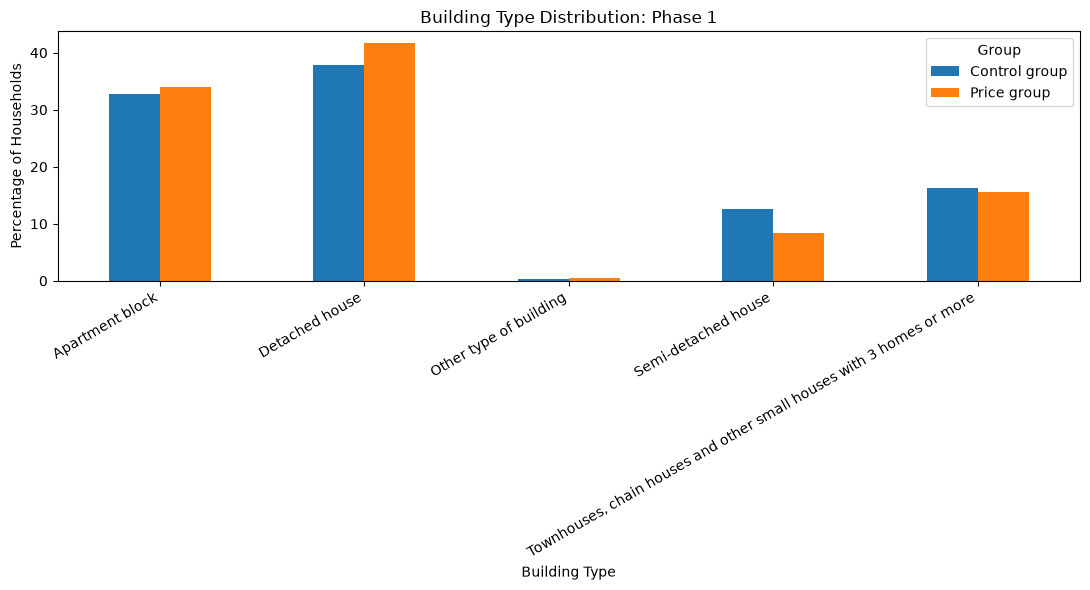

In [53]:
import matplotlib.pyplot as plt

building_percentages = pd.crosstab(
    building_data["Control_Price_Phase1"],
    building_data["q4"],
    normalize="index"
) * 100

building_percentages.T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Building Type Distribution: Phase 1")
plt.xlabel("Building Type")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Group")
plt.tight_layout()
plt.show()

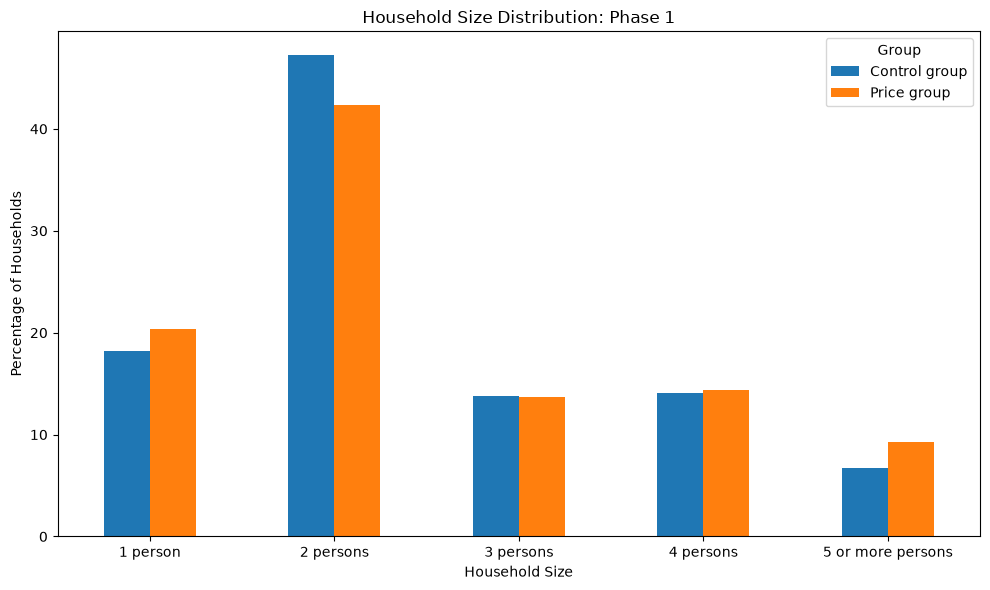

In [54]:
household_percentages = pd.crosstab(
    household_size_data["Control_Price_Phase1"],
    household_size_data["Household_Size_Final"],
    normalize="index"
) * 100

household_percentages.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Household Size Distribution: Phase 1")
plt.xlabel("Household Size")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=0)
plt.legend(title="Group")
plt.tight_layout()
plt.show()

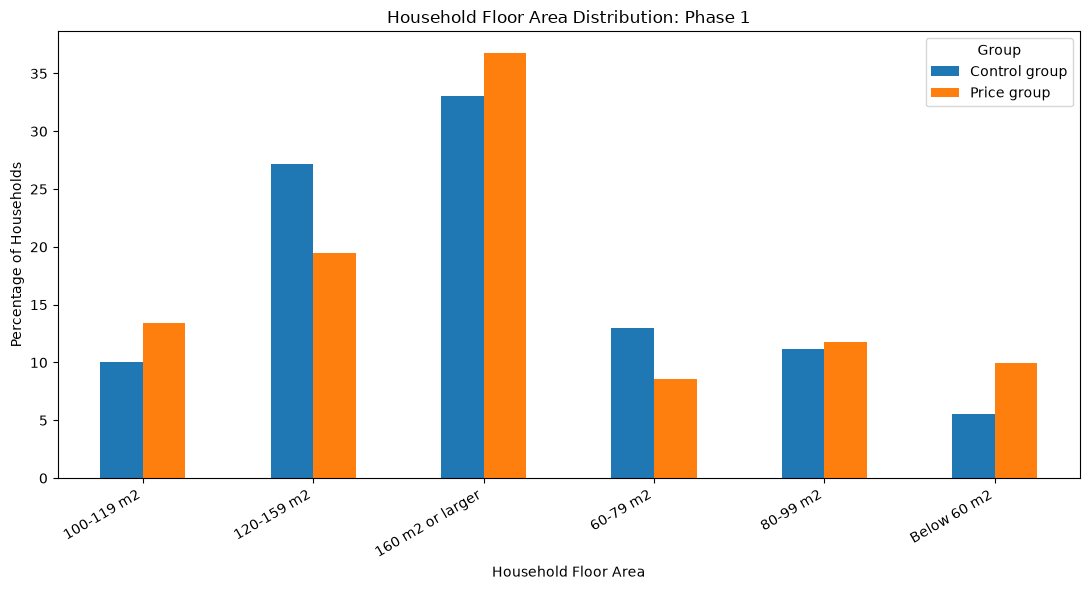

In [55]:
floor_area_percentages = pd.crosstab(
    floor_area_data["Control_Price_Phase1"],
    floor_area_data["Floor_Area_Grouped"],
    normalize="index"
) * 100

floor_area_percentages.T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Household Floor Area Distribution: Phase 1")
plt.xlabel("Household Floor Area")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Group")
plt.tight_layout()
plt.show()

<Figure size 1100x600 with 0 Axes>

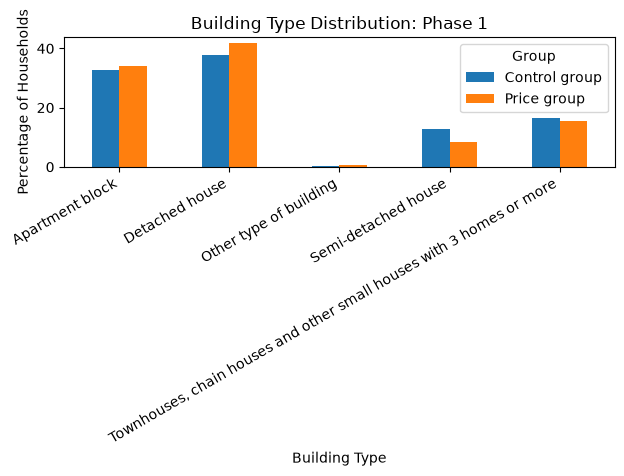

Building-type chart saved successfully.


In [56]:
plt.figure(figsize=(11, 6))

building_percentages.T.plot(kind="bar")

plt.title("Building Type Distribution: Phase 1")
plt.xlabel("Building Type")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Group")
plt.tight_layout()

plt.savefig(
    "../results/phase1_building_type_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Building-type chart saved successfully.")

<Figure size 1000x600 with 0 Axes>

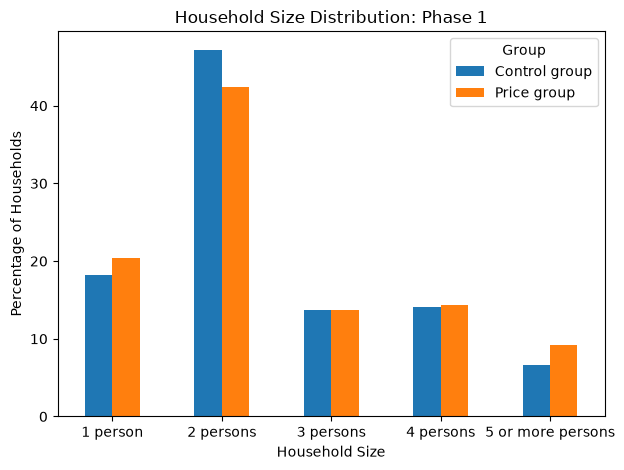

Household-size chart saved successfully.


In [57]:
plt.figure(figsize=(10, 6))

household_percentages.T.plot(kind="bar")

plt.title("Household Size Distribution: Phase 1")
plt.xlabel("Household Size")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=0)
plt.legend(title="Group")
plt.tight_layout()

plt.savefig(
    "../results/phase1_household_size_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Household-size chart saved successfully.")

<Figure size 1100x600 with 0 Axes>

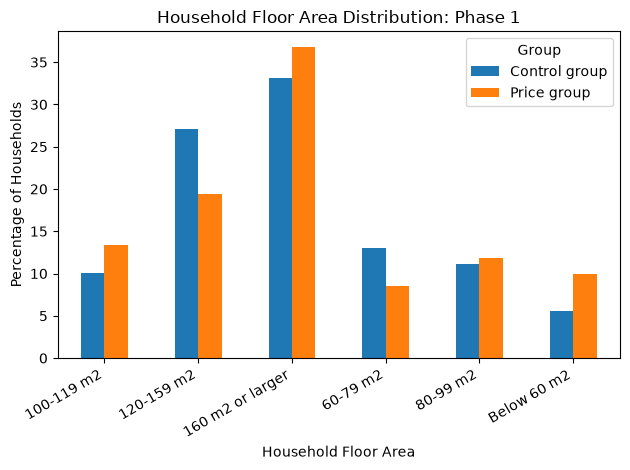

Floor-area chart saved successfully.


In [58]:
plt.figure(figsize=(11, 6))

floor_area_percentages.T.plot(kind="bar")

plt.title("Household Floor Area Distribution: Phase 1")
plt.xlabel("Household Floor Area")
plt.ylabel("Percentage of Households")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Group")
plt.tight_layout()

plt.savefig(
    "../results/phase1_floor_area_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Floor-area chart saved successfully.")

In [59]:
import os

chart_files = [
    "phase1_building_type_chart.png",
    "phase1_household_size_chart.png",
    "phase1_floor_area_chart.png"
]

for file in chart_files:
    print(file, "->", os.path.exists("../results/" + file))

phase1_building_type_chart.png -> True
phase1_household_size_chart.png -> True
phase1_floor_area_chart.png -> True


In [60]:
print("Baseline dataset available:", "baseline_summary" in globals())

Baseline dataset available: False


In [61]:
import pandas as pd

hourly = pd.read_csv(
    "../data/raw/data_hourly.csv",
    parse_dates=["Date"]
)

print("Hourly data loaded successfully.")
print("Dataset shape:", hourly.shape)

Hourly data loaded successfully.
Dataset shape: (13515600, 12)


In [62]:
participants = pd.read_csv("../data/raw/participants.csv")

phase1 = participants[
    participants["Control_Price_Phase1"].isin(
        ["Control group", "Price group"]
    )
].copy()

print("Phase 1 participants:", len(phase1))
print("\nGroup counts:")
print(phase1["Control_Price_Phase1"].value_counts())

Phase 1 participants: 742

Group counts:
Control_Price_Phase1
Price group      439
Control group    303
Name: count, dtype: int64


In [63]:
baseline_start = "2020-01-28"
baseline_end = "2020-02-10"

baseline_data = hourly[
    (hourly["ID"].isin(phase1["ID"])) &
    (hourly["Date"] >= baseline_start) &
    (hourly["Date"] <= baseline_end)
].copy()

print("Baseline data shape:", baseline_data.shape)
print("Unique households:", baseline_data["ID"].nunique())
print("Date range:")
print(baseline_data["Date"].min(), "to", baseline_data["Date"].max())

Baseline data shape: (249312, 12)
Unique households: 742
Date range:
2020-01-28 00:00:00 to 2020-02-10 00:00:00


In [64]:
baseline_daily = (
    baseline_data
    .groupby(["ID", "Date"])["Demand_kWh"]
    .sum()
    .reset_index()
)

print("Daily dataset shape:", baseline_daily.shape)
print("Unique households:", baseline_daily["ID"].nunique())
print("Unique dates:", baseline_daily["Date"].nunique())

print("\nFirst five rows:")
print(baseline_daily.head())

Daily dataset shape: (10388, 3)
Unique households: 742
Unique dates: 14

First five rows:
      ID       Date  Demand_kWh
0  Exp_1 2020-01-28      70.090
1  Exp_1 2020-01-29      68.489
2  Exp_1 2020-01-30      68.346
3  Exp_1 2020-01-31      68.268
4  Exp_1 2020-02-01      64.131


In [65]:
baseline_daily = baseline_daily.merge(
    phase1[["ID", "Control_Price_Phase1"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

print("Group assignment check:")
print(baseline_daily["Control_Price_Phase1"].value_counts())

print("\nMissing group assignments:")
print(baseline_daily["Control_Price_Phase1"].isna().sum())

Group assignment check:
Control_Price_Phase1
Price group      6146
Control group    4242
Name: count, dtype: int64

Missing group assignments:
0


In [66]:
baseline_household = (
    baseline_daily
    .groupby(["ID", "Control_Price_Phase1"])["Demand_kWh"]
    .mean()
    .reset_index()
)

print("Household-level baseline dataset:")
print(baseline_household.shape)

print("\nAverage baseline consumption by group:")
print(
    baseline_household
    .groupby("Control_Price_Phase1")["Demand_kWh"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)

Household-level baseline dataset:
(742, 3)

Average baseline consumption by group:
                      count    mean  median     std
Control_Price_Phase1                               
Control group           303  61.019  62.608  34.920
Price group             439  65.092  61.775  39.717


In [67]:
from scipy.stats import ttest_ind

control_baseline = baseline_household[
    baseline_household["Control_Price_Phase1"] == "Control group"
]["Demand_kWh"]

price_baseline = baseline_household[
    baseline_household["Control_Price_Phase1"] == "Price group"
]["Demand_kWh"]

t_stat, baseline_p_value = ttest_ind(
    price_baseline,
    control_baseline,
    equal_var=False
)

print("Welch t-statistic:", round(t_stat, 4))
print("P-value:", round(baseline_p_value, 4))
print("Mean difference (Price - Control):",
      round(price_baseline.mean() - control_baseline.mean(), 3), "kWh")

Welch t-statistic: 1.4756
P-value: 0.1405
Mean difference (Price - Control): 4.073 kWh


In [68]:
baseline_test_result = pd.DataFrame({
    "Test": ["Welch independent-samples t-test"],
    "Control mean kWh": [control_baseline.mean()],
    "Price mean kWh": [price_baseline.mean()],
    "Mean difference kWh": [
        price_baseline.mean() - control_baseline.mean()
    ],
    "T-statistic": [t_stat],
    "P-value": [baseline_p_value],
    "Conclusion": [
        "No statistically significant baseline difference"
    ]
})

baseline_test_result.to_csv(
    "../results/phase1_baseline_test.csv",
    index=False
)

print("Baseline test result saved successfully.")

Baseline test result saved successfully.


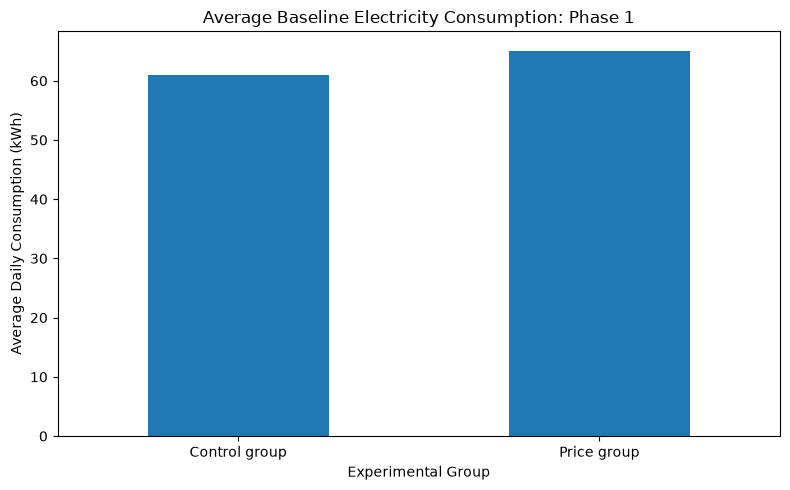

Baseline consumption chart saved successfully.


In [69]:
baseline_means = baseline_household.groupby(
    "Control_Price_Phase1"
)["Demand_kWh"].mean()

plt.figure(figsize=(8, 5))

baseline_means.plot(kind="bar")

plt.title("Average Baseline Electricity Consumption: Phase 1")
plt.xlabel("Experimental Group")
plt.ylabel("Average Daily Consumption (kWh)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../results/phase1_baseline_consumption_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Baseline consumption chart saved successfully.")

In [70]:
baseline_files = [
    "phase1_baseline_test.csv",
    "phase1_baseline_consumption_chart.png",
]

for file in baseline_files:
    print(file, "->", os.path.exists("../results/" + file))

phase1_baseline_test.csv -> True
phase1_baseline_consumption_chart.png -> True


In [71]:
experiment_days = pd.read_csv(
    "../data/raw/experiment_days.csv"
)

print("Experiment schedule shape:", experiment_days.shape)

print("\nColumns:")
print(experiment_days.columns.tolist())

print("\nFirst five rows:")
print(experiment_days.head())

Experiment schedule shape: (267, 4)

Columns:
['Participation_Phase', 'Price_signal', 'Date', 'Group']

First five rows:
  Participation_Phase Price_signal        Date Group
0             Phase_1         A_10  2020-02-13    H1
1             Phase_1         A_10  2020-03-02    H1
2             Phase_1          A_5  2020-02-14    H1
3             Phase_1          A_5  2020-03-03    H1
4             Phase_1         B_10  2020-03-04    H1


In [72]:
phase1_schedule = experiment_days[
    experiment_days["Participation_Phase"] == "Phase_1"
].copy()

phase1_schedule["Date"] = pd.to_datetime(
    phase1_schedule["Date"]
)

print("Phase 1 schedule shape:", phase1_schedule.shape)

print("\nNumber of unique experiment dates:",
      phase1_schedule["Date"].nunique())

print("\nGroups:")
print(phase1_schedule["Group"].value_counts())

print("\nPrice signals:")
print(phase1_schedule["Price_signal"].value_counts())

print("\nSchedule:")
print(
    phase1_schedule.sort_values(
        ["Date", "Group"]
    ).to_string(index=False)
)

Phase 1 schedule shape: (13, 4)

Number of unique experiment dates: 11

Groups:
Group
H1    8
H2    5
Name: count, dtype: int64

Price signals:
Price_signal
P_10    3
A_10    2
A_5     2
C       2
P_5     2
B_10    1
B_5     1
Name: count, dtype: int64

Schedule:
Participation_Phase Price_signal       Date Group
            Phase_1          B_5 2020-02-11    H1
            Phase_1            C 2020-02-12    H1
            Phase_1         A_10 2020-02-13    H1
            Phase_1         P_10 2020-02-13    H2
            Phase_1          A_5 2020-02-14    H1
            Phase_1         P_10 2020-02-19    H2
            Phase_1         P_10 2020-02-27    H2
            Phase_1         A_10 2020-03-02    H1
            Phase_1          A_5 2020-03-03    H1
            Phase_1          P_5 2020-03-03    H2
            Phase_1         B_10 2020-03-04    H1
            Phase_1            C 2020-03-05    H1
            Phase_1          P_5 2020-03-09    H2


In [73]:
print("Phase 1 official assignment groups:")

print(
    phase1["Control_Price_Phase1"]
    .value_counts(dropna=False)
)

print("\nHousehold counts by assignment and schedule group:")

print(
    phase1.groupby("Control_Price_Phase1")["ID"]
    .nunique()
)

Phase 1 official assignment groups:
Control_Price_Phase1
Price group      439
Control group    303
Name: count, dtype: int64

Household counts by assignment and schedule group:
Control_Price_Phase1
Control group    303
Price group      439
Name: ID, dtype: int64


In [74]:
print("Phase 1 assignment-related columns:")

print(
    participants.columns[
        participants.columns.str.contains(
            "Group|Control|Price|Phase1",
            case=False
        )
    ].tolist()
)

print("\nPhase 1 group assignment counts:")

for column in ["Group_Phase1", "Control_Price_Phase1"]:
    print(f"\n{column}:")
    print(
        phase1[column]
        .value_counts(dropna=False)
    )

Phase 1 assignment-related columns:
['Control_Price_Phase1', 'Control_Price_Phase2', 'Group_Phase1', 'Group_Phase2', 'Participation_status_Phase1']

Phase 1 group assignment counts:

Group_Phase1:
Group_Phase1
Control    303
H2         220
H1         219
Name: count, dtype: int64

Control_Price_Phase1:
Control_Price_Phase1
Price group      439
Control group    303
Name: count, dtype: int64


In [75]:
print(
    pd.crosstab(
        phase1["Group_Phase1"],
        phase1["Control_Price_Phase1"]
    )
)

Control_Price_Phase1  Control group  Price group
Group_Phase1                                    
Control                         303            0
H1                                0          219
H2                                0          220


In [76]:
phase1_experiment_data = hourly[
    (hourly["Participation_Phase"] == "Phase_1") &
    (hourly["Date"].isin(phase1_schedule["Date"]))
].copy()

print("Experimental data shape:", phase1_experiment_data.shape)

print("\nUnique experiment dates:",
      phase1_experiment_data["Date"].nunique())

print("\nUnique households:",
      phase1_experiment_data["ID"].nunique())

print("\nPhase distribution:")
print(phase1_experiment_data["Participation_Phase"].value_counts())

Experimental data shape: (195888, 12)

Unique experiment dates: 11

Unique households: 742

Phase distribution:
Participation_Phase
Phase_1    195888
Name: count, dtype: int64


In [77]:
phase1_experiment_data = phase1_experiment_data.merge(
    phase1[["ID", "Group_Phase1", "Control_Price_Phase1"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

print("Dataset shape:", phase1_experiment_data.shape)

print("\nHouseholds by group:")
print(
    phase1_experiment_data.groupby("Group_Phase1")["ID"]
    .nunique()
)

print("\nMissing group assignments:")
print(
    phase1_experiment_data["Group_Phase1"].isna().sum()
)

Dataset shape: (195888, 14)

Households by group:
Group_Phase1
Control    303
H1         219
H2         220
Name: ID, dtype: int64

Missing group assignments:
0


In [78]:
schedule_check = phase1_experiment_data.merge(
    phase1_schedule,
    left_on=["Date", "Group_Phase1"],
    right_on=["Date", "Group"],
    how="left",
    indicator=True
)

print("Schedule matching results:")
print(schedule_check["_merge"].value_counts())

print("\nMatched records by scheduled group:")
print(
    schedule_check[schedule_check["_merge"] == "both"]
    .groupby(["Date", "Group_Phase1", "Price_signal"])
    ["ID"]
    .nunique()
)

Schedule matching results:
_merge
left_only     127440
both           68448
right_only         0
Name: count, dtype: int64

Matched records by scheduled group:


KeyError: 'Price_signal'

In [79]:
print(schedule_check.columns.tolist())

['ID', 'From', 'Date', 'Hour', 'Participation_Phase_x', 'Demand_kWh', 'Price_signal_x', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72', 'Group_Phase1', 'Control_Price_Phase1', 'Participation_Phase_y', 'Price_signal_y', 'Group', '_merge']


In [80]:
matched_schedule = schedule_check[
    schedule_check["_merge"] == "both"
].copy()

print("Matched hourly records:", len(matched_schedule))

print("\nMatched records by date, group and scheduled signal:")

print(
    matched_schedule.groupby(
        ["Date", "Group_Phase1", "Price_signal_y"]
    )["ID"].nunique()
)

Matched hourly records: 68448

Matched records by date, group and scheduled signal:
Date        Group_Phase1  Price_signal_y
2020-02-11  H1            B_5               219
2020-02-12  H1            C                 219
2020-02-13  H1            A_10              219
            H2            P_10              220
2020-02-14  H1            A_5               219
2020-02-19  H2            P_10              220
2020-02-27  H2            P_10              220
2020-03-02  H1            A_10              219
2020-03-03  H1            A_5               219
            H2            P_5               220
2020-03-04  H1            B_10              219
2020-03-05  H1            C                 219
2020-03-09  H2            P_5               220
Name: ID, dtype: int64


In [81]:
signal_check = matched_schedule[
    ["ID", "Date", "Group_Phase1",
     "Price_signal_x", "Price_signal_y"]
].drop_duplicates()

print("Unique household-date records:", len(signal_check))

print("\nObserved hourly signal vs scheduled signal:")

print(
    pd.crosstab(
        signal_check["Price_signal_y"],
        signal_check["Price_signal_x"],
        dropna=False
    )
)

Unique household-date records: 2852

Observed hourly signal vs scheduled signal:
Price_signal_x  A_10  A_5  B_10  B_5    C  P_10  P_5
Price_signal_y                                      
A_10             438    0     0    0    0     0    0
A_5                0  438     0    0    0     0    0
B_10               0    0   219    0    0     0    0
B_5                0    0     0  219    0     0    0
C                  0    0     0    0  438     0    0
P_10               0    0     0    0    0   660    0
P_5                0    0     0    0    0     0  440


In [82]:
experimental_daily = (
    phase1_experiment_data
    .groupby(["ID", "Date", "Group_Phase1", "Control_Price_Phase1"])
    ["Demand_kWh"]
    .sum()
    .reset_index()
)

print("Daily dataset shape:", experimental_daily.shape)

print("\nHousehold count:")
print(experimental_daily["ID"].nunique())

print("\nRecords by group:")
print(
    experimental_daily.groupby("Group_Phase1")
    .size()
)

print("\nFirst five rows:")
print(experimental_daily.head())

Daily dataset shape: (8162, 5)

Household count:
742

Records by group:
Group_Phase1
Control    3333
H1         2409
H2         2420
dtype: int64

First five rows:
      ID       Date Group_Phase1 Control_Price_Phase1  Demand_kWh
0  Exp_1 2020-02-11           H1          Price group      65.314
1  Exp_1 2020-02-12           H1          Price group      70.846
2  Exp_1 2020-02-13           H1          Price group      74.356
3  Exp_1 2020-02-14           H1          Price group      73.156
4  Exp_1 2020-02-19           H1          Price group      64.974


In [83]:
records_per_household = (
    experimental_daily
    .groupby(["ID", "Group_Phase1"])
    .size()
    .reset_index(name="Experiment_Days")
)

print("Observation counts by group:")
print(
    records_per_household.groupby("Group_Phase1")
    ["Experiment_Days"]
    .value_counts()
    .sort_index()
)

print("\nMinimum observations per household:",
      records_per_household["Experiment_Days"].min())

print("Maximum observations per household:",
      records_per_household["Experiment_Days"].max())

Observation counts by group:
Group_Phase1  Experiment_Days
Control       11                 303
H1            11                 219
H2            11                 220
Name: count, dtype: int64

Minimum observations per household: 11
Maximum observations per household: 11


In [84]:
experimental_group_summary = (
    experimental_daily
    .groupby("Group_Phase1")["Demand_kWh"]
    .agg(
        Households="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .round(3)
)

print(experimental_group_summary)

              Households    Mean  Median  Std_Dev
Group_Phase1                                     
Control             3333  59.968  60.531   35.811
H1                  2409  61.897  59.096   38.951
H2                  2420  61.943  56.938   40.626


In [85]:
signal_daily_summary = (
    matched_schedule
    .groupby(["Date", "Group_Phase1", "Price_signal_y", "ID"])
    ["Demand_kWh"]
    .sum()
    .reset_index()
    .groupby("Price_signal_y")["Demand_kWh"]
    .agg(
        Household_Days="count",
        Mean="mean",
        Median="median",
        Std_Dev="std"
    )
    .round(3)
)

print(signal_daily_summary)

                Household_Days    Mean  Median  Std_Dev
Price_signal_y                                         
A_10                       438  61.608  57.772   39.076
A_5                        438  63.305  60.613   39.246
B_10                       219  62.102  60.598   38.335
B_5                        219  60.417  56.298   38.608
C                          438  60.782  57.608   38.258
P_10                       660  63.108  58.814   41.597
P_5                        440  58.835  55.256   38.685


In [86]:
import os

os.makedirs("../results", exist_ok=True)

signal_daily_summary.to_csv(
    "../results/phase1_price_signal_consumption_summary.csv"
)

print("Price signal summary saved successfully.")

Price signal summary saved successfully.


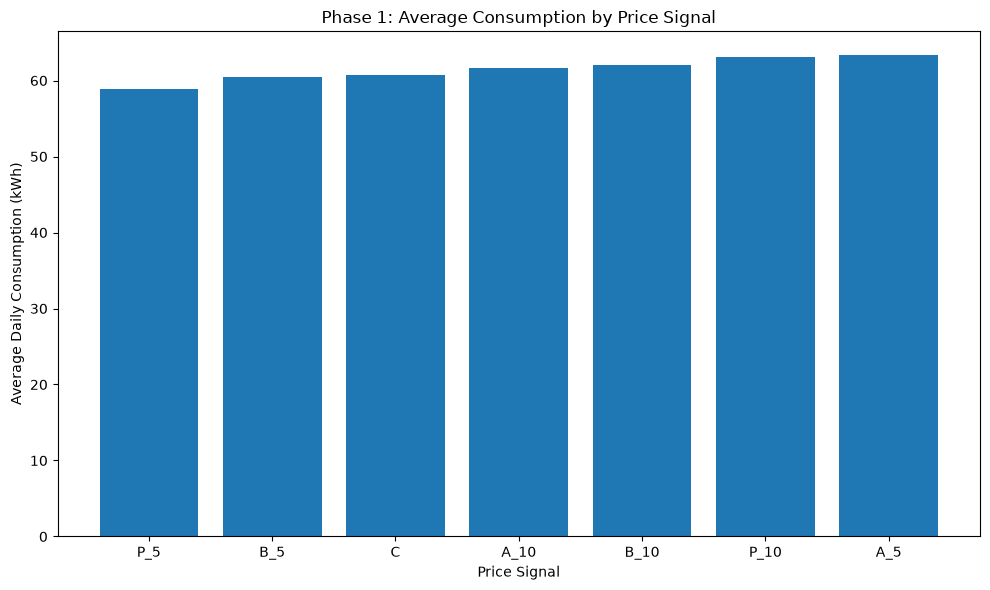

In [87]:
import matplotlib.pyplot as plt

signal_chart = signal_daily_summary.sort_values("Mean")

plt.figure(figsize=(10, 6))

plt.bar(
    signal_chart.index,
    signal_chart["Mean"]
)

plt.xlabel("Price Signal")
plt.ylabel("Average Daily Consumption (kWh)")
plt.title("Phase 1: Average Consumption by Price Signal")

plt.tight_layout()
plt.savefig(
    "../results/phase1_price_signal_consumption_chart.png",
    dpi=300
)

plt.show()

In [88]:
date_group_summary = (
    experimental_daily
    .groupby(["Date", "Group_Phase1"])["Demand_kWh"]
    .mean()
    .reset_index()
)

print("Date-level summary shape:", date_group_summary.shape)

print("\nFirst 15 rows:")
print(date_group_summary.head(15))

Date-level summary shape: (33, 3)

First 15 rows:
         Date Group_Phase1  Demand_kWh
0  2020-02-11      Control   59.274904
1  2020-02-11           H1   60.417119
2  2020-02-11           H2   61.708800
3  2020-02-12      Control   59.505729
4  2020-02-12           H1   61.062073
5  2020-02-12           H2   61.867495
6  2020-02-13      Control   61.824759
7  2020-02-13           H1   61.736776
8  2020-02-13           H2   63.192436
9  2020-02-14      Control   64.170003
10 2020-02-14           H1   64.487306
11 2020-02-14           H2   65.816255
12 2020-02-19      Control   56.102317
13 2020-02-19           H1   58.875137
14 2020-02-19           H2   58.026655


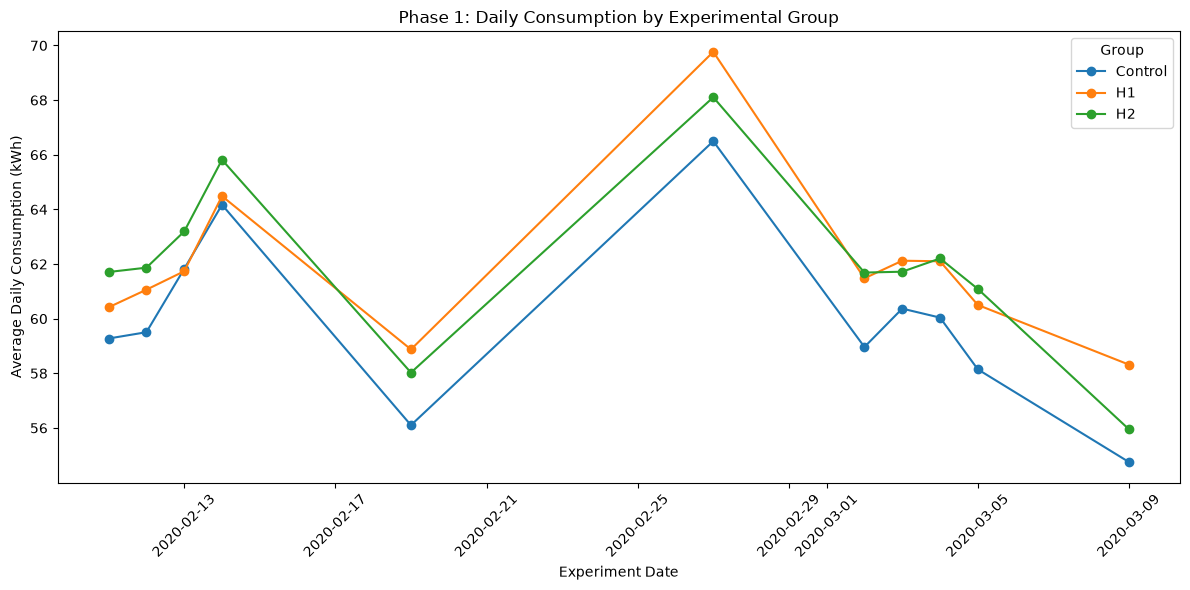

In [89]:
date_group_pivot = date_group_summary.pivot(
    index="Date",
    columns="Group_Phase1",
    values="Demand_kWh"
)

plt.figure(figsize=(12, 6))

for group in ["Control", "H1", "H2"]:
    plt.plot(
        date_group_pivot.index,
        date_group_pivot[group],
        marker="o",
        label=group
    )

plt.xlabel("Experiment Date")
plt.ylabel("Average Daily Consumption (kWh)")
plt.title("Phase 1: Daily Consumption by Experimental Group")
plt.xticks(rotation=45)
plt.legend(title="Group")
plt.tight_layout()

plt.savefig(
    "../results/phase1_daily_consumption_by_group.png",
    dpi=300
)

plt.show()

In [90]:
date_group_summary.to_csv(
    "../results/phase1_date_group_consumption_summary.csv",
    index=False
)

print("Date-group summary saved successfully.")

Date-group summary saved successfully.


In [91]:
temperature_summary = (
    phase1_experiment_data
    .groupby(["Date", "Group_Phase1"])["Temperature"]
    .mean()
    .reset_index()
)

print("Temperature summary shape:",
      temperature_summary.shape)

print("\nFirst 15 rows:")
print(temperature_summary.head(15))

Temperature summary shape: (33, 3)

First 15 rows:
         Date Group_Phase1  Temperature
0  2020-02-11      Control     3.051485
1  2020-02-11           H1     3.140164
2  2020-02-11           H2     3.115076
3  2020-02-12      Control     2.713628
4  2020-02-12           H1     2.684151
5  2020-02-12           H2     2.710284
6  2020-02-13      Control     1.105844
7  2020-02-13           H1     1.175000
8  2020-02-13           H2     1.154867
9  2020-02-14      Control     0.802269
10 2020-02-14           H1     1.067180
11 2020-02-14           H2     0.979015
12 2020-02-19      Control     2.398254
13 2020-02-19           H1     2.578919
14 2020-02-19           H2     2.514280


In [92]:
temperature_group_summary = (
    phase1_experiment_data
    .groupby("Group_Phase1")["Temperature"]
    .agg(
        Mean_Temperature="mean",
        Median_Temperature="median",
        Std_Dev="std"
    )
    .round(3)
)

print(temperature_group_summary)

              Mean_Temperature  Median_Temperature  Std_Dev
Group_Phase1                                               
Control                  2.238                 2.5    2.810
H1                       2.387                 2.5    2.757
H2                       2.338                 2.5    2.774


In [93]:
temperature_group_summary.to_csv(
    "../results/phase1_temperature_group_summary.csv"
)

print("Temperature summary saved successfully.")

Temperature summary saved successfully.


In [94]:
hourly_group_summary = (
    phase1_experiment_data
    .groupby(["Group_Phase1", "Hour"])["Demand_kWh"]
    .mean()
    .reset_index()
)

print("Hourly summary shape:", hourly_group_summary.shape)

print("\nFirst 15 rows:")
print(hourly_group_summary.head(15))

Hourly summary shape: (72, 3)

First 15 rows:
   Group_Phase1  Hour  Demand_kWh
0       Control     1    2.258499
1       Control     2    2.133526
2       Control     3    2.107000
3       Control     4    2.109179
4       Control     5    2.163582
5       Control     6    2.212670
6       Control     7    2.557267
7       Control     8    2.820803
8       Control     9    2.711846
9       Control    10    2.601023
10      Control    11    2.476623
11      Control    12    2.357761
12      Control    13    2.268242
13      Control    14    2.237626
14      Control    15    2.212963


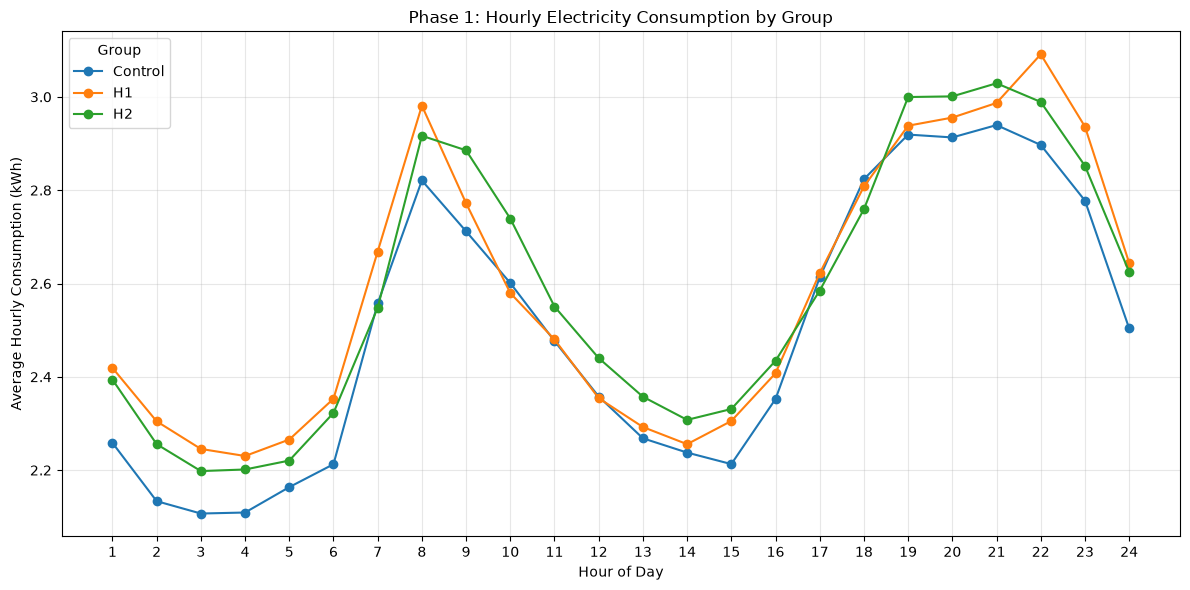

In [95]:
hourly_group_pivot = hourly_group_summary.pivot(
    index="Hour",
    columns="Group_Phase1",
    values="Demand_kWh"
)

plt.figure(figsize=(12, 6))

for group in ["Control", "H1", "H2"]:
    plt.plot(
        hourly_group_pivot.index,
        hourly_group_pivot[group],
        marker="o",
        label=group
    )

plt.xlabel("Hour of Day")
plt.ylabel("Average Hourly Consumption (kWh)")
plt.title("Phase 1: Hourly Electricity Consumption by Group")
plt.xticks(range(1, 25))
plt.legend(title="Group")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/phase1_hourly_consumption_by_group.png",
    dpi=300
)

plt.show()

In [96]:
for group in ["Control", "H1", "H2"]:
    group_data = hourly_group_summary[
        hourly_group_summary["Group_Phase1"] == group
    ]

    highest = group_data.loc[group_data["Demand_kWh"].idxmax()]
    lowest = group_data.loc[group_data["Demand_kWh"].idxmin()]

    print(f"\n{group}")
    print(
        f"Highest consumption: Hour {int(highest['Hour'])} "
        f"({highest['Demand_kWh']:.3f} kWh)"
    )
    print(
        f"Lowest consumption: Hour {int(lowest['Hour'])} "
        f"({lowest['Demand_kWh']:.3f} kWh)"
    )


Control
Highest consumption: Hour 21 (2.940 kWh)
Lowest consumption: Hour 3 (2.107 kWh)

H1
Highest consumption: Hour 22 (3.091 kWh)
Lowest consumption: Hour 4 (2.230 kWh)

H2
Highest consumption: Hour 21 (3.029 kWh)
Lowest consumption: Hour 3 (2.198 kWh)


In [97]:
hourly_group_summary.to_csv(
    "../results/phase1_hourly_consumption_summary.csv",
    index=False
)

print("Hourly consumption summary saved successfully.")

Hourly consumption summary saved successfully.


In [98]:
phase1_files = [
    "phase1_price_signal_consumption_summary.csv",
    "phase1_price_signal_consumption_chart.png",
    "phase1_daily_consumption_by_group.png",
    "phase1_date_group_consumption_summary.csv",
    "phase1_temperature_group_summary.csv",
    "phase1_hourly_consumption_summary.csv",
    "phase1_hourly_consumption_by_group.png"
]

for file in phase1_files:
    print(file, "->", os.path.exists("../results/" + file))

phase1_price_signal_consumption_summary.csv -> True
phase1_price_signal_consumption_chart.png -> True
phase1_daily_consumption_by_group.png -> True
phase1_date_group_consumption_summary.csv -> True
phase1_temperature_group_summary.csv -> True
phase1_hourly_consumption_summary.csv -> True
phase1_hourly_consumption_by_group.png -> True


In [99]:
temperature_summary.to_csv(
    "../results/phase1_date_group_temperature_summary.csv",
    index=False
)

print("Date-group temperature summary saved successfully.")

Date-group temperature summary saved successfully.


In [100]:
phase1_assignment_summary = (
    phase1[["ID", "Control_Price_Phase1", "Group_Phase1"]]
    .drop_duplicates()
    .groupby(
        ["Control_Price_Phase1", "Group_Phase1"]
    )
    .agg(Households=("ID", "nunique"))
    .reset_index()
)

print(phase1_assignment_summary)

  Control_Price_Phase1 Group_Phase1  Households
0        Control group      Control         303
1          Price group           H1         219
2          Price group           H2         220


In [101]:
phase1["Treatment_Assigned"] = (
    phase1["Control_Price_Phase1"] == "Price group"
).astype(int)

print(
    phase1[
        ["ID", "Control_Price_Phase1",
         "Group_Phase1", "Treatment_Assigned"]
    ].head(10)
)

print("\nTreatment counts:")
print(phase1["Treatment_Assigned"].value_counts())

       ID Control_Price_Phase1 Group_Phase1  Treatment_Assigned
0   Exp_1          Price group           H1                   1
1   Exp_2          Price group           H1                   1
2   Exp_3          Price group           H1                   1
3   Exp_4          Price group           H1                   1
4   Exp_5          Price group           H1                   1
5   Exp_6          Price group           H1                   1
6   Exp_7          Price group           H1                   1
7   Exp_8          Price group           H1                   1
8   Exp_9          Price group           H1                   1
9  Exp_10          Price group           H1                   1

Treatment counts:
Treatment_Assigned
1    439
0    303
Name: count, dtype: int64


In [102]:
experimental_daily = experimental_daily.merge(
    phase1[["ID", "Treatment_Assigned"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

print("Dataset shape:", experimental_daily.shape)

print("\nTreatment counts:")
print(
    experimental_daily.groupby("Treatment_Assigned")
    ["ID"].nunique()
)

print("\nMissing treatment assignments:",
      experimental_daily["Treatment_Assigned"].isna().sum())

Dataset shape: (8162, 6)

Treatment counts:
Treatment_Assigned
0    303
1    439
Name: ID, dtype: int64

Missing treatment assignments: 0


In [103]:
treatment_consistency = (
    experimental_daily
    .groupby("ID")["Treatment_Assigned"]
    .nunique()
)

print("Households with one treatment assignment:",
      (treatment_consistency == 1).sum())

print("Households with changing treatment assignment:",
      (treatment_consistency > 1).sum())

print("\nTreatment consistency check:")
print(treatment_consistency.value_counts())

Households with one treatment assignment: 742
Households with changing treatment assignment: 0

Treatment consistency check:
Treatment_Assigned
1    742
Name: count, dtype: int64


In [104]:
daily_temperature = (
    phase1_experiment_data
    .groupby(["ID", "Date"])["Temperature"]
    .mean()
    .reset_index(name="Daily_Temperature")
)

print("Daily temperature dataset shape:",
      daily_temperature.shape)

print("\nFirst five rows:")
print(daily_temperature.head())

Daily temperature dataset shape: (8162, 3)

First five rows:
      ID       Date  Daily_Temperature
0  Exp_1 2020-02-11           3.700000
1  Exp_1 2020-02-12           1.816667
2  Exp_1 2020-02-13           1.633333
3  Exp_1 2020-02-14           3.245833
4  Exp_1 2020-02-19           4.237500


In [105]:
causal_data = experimental_daily.merge(
    daily_temperature,
    on=["ID", "Date"],
    how="left",
    validate="one_to_one"
)

print("Causal dataset shape:", causal_data.shape)

print("\nMissing values:")
print(
    causal_data[
        ["Demand_kWh", "Treatment_Assigned", "Daily_Temperature"]
    ].isna().sum()
)

print("\nFirst five rows:")
print(causal_data.head())

Causal dataset shape: (8162, 7)

Missing values:
Demand_kWh            0
Treatment_Assigned    0
Daily_Temperature     0
dtype: int64

First five rows:
      ID       Date Group_Phase1 Control_Price_Phase1  Demand_kWh  \
0  Exp_1 2020-02-11           H1          Price group      65.314   
1  Exp_1 2020-02-12           H1          Price group      70.846   
2  Exp_1 2020-02-13           H1          Price group      74.356   
3  Exp_1 2020-02-14           H1          Price group      73.156   
4  Exp_1 2020-02-19           H1          Price group      64.974   

   Treatment_Assigned  Daily_Temperature  
0                   1           3.700000  
1                   1           1.816667  
2                   1           1.633333  
3                   1           3.245833  
4                   1           4.237500  


In [106]:
causal_data.to_csv(
    "../data/processed/phase1_causal_dataset.csv",
    index=False
)

print("Phase 1 causal dataset saved successfully.")

Phase 1 causal dataset saved successfully.


In [107]:
phase1_hourly_causal = phase1_experiment_data[
    [
        "ID",
        "Date",
        "Hour",
        "Demand_kWh",
        "Temperature",
        "Price_signal_x",
        "Experiment_price_NOK_kWh",
        "Group_Phase1"
    ]
].copy()

print("Hourly causal dataset shape:",
      phase1_hourly_causal.shape)

print("\nColumns:")
print(phase1_hourly_causal.columns.tolist())

print("\nFirst five rows:")
print(phase1_hourly_causal.head())

KeyError: "['Price_signal_x'] not in index"

In [108]:
print(phase1_experiment_data.columns.tolist())

['ID', 'From', 'Date', 'Hour', 'Participation_Phase', 'Demand_kWh', 'Price_signal', 'Experiment_price_NOK_kWh', 'Temperature', 'Temperature24', 'Temperature48', 'Temperature72', 'Group_Phase1', 'Control_Price_Phase1']


In [109]:
phase1_hourly_causal = phase1_experiment_data[
    [
        "ID",
        "Date",
        "Hour",
        "Demand_kWh",
        "Temperature",
        "Price_signal",
        "Experiment_price_NOK_kWh",
        "Group_Phase1"
    ]
].copy()

print("Hourly causal dataset shape:",
      phase1_hourly_causal.shape)

print("\nColumns:")
print(phase1_hourly_causal.columns.tolist())

print("\nFirst five rows:")
print(phase1_hourly_causal.head())

Hourly causal dataset shape: (195888, 8)

Columns:
['ID', 'Date', 'Hour', 'Demand_kWh', 'Temperature', 'Price_signal', 'Experiment_price_NOK_kWh', 'Group_Phase1']

First five rows:
       ID       Date  Hour  Demand_kWh  Temperature Price_signal  \
0  Exp_43 2020-02-11     1       0.560          3.0          B_5   
1  Exp_43 2020-02-11     2       0.312          3.0          B_5   
2  Exp_43 2020-02-11     3       0.583          3.3          B_5   
3  Exp_43 2020-02-11     4       0.328          3.7          B_5   
4  Exp_43 2020-02-11     5       0.332          4.0          B_5   

   Experiment_price_NOK_kWh Group_Phase1  
0                      1.00           H1  
1                      0.99           H1  
2                      0.95           H1  
3                      0.95           H1  
4                      0.96           H1  


In [110]:
phase1_hourly_causal = phase1_hourly_causal.merge(
    phase1[["ID", "Treatment_Assigned"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

print("Dataset shape:", phase1_hourly_causal.shape)

print("\nTreatment assignment counts:")
print(
    phase1_hourly_causal[
        ["ID", "Treatment_Assigned"]
    ].drop_duplicates()["Treatment_Assigned"].value_counts()
)

print("\nMissing treatment assignments:",
      phase1_hourly_causal["Treatment_Assigned"].isna().sum())

Dataset shape: (195888, 9)

Treatment assignment counts:
Treatment_Assigned
1    439
0    303
Name: count, dtype: int64

Missing treatment assignments: 0


In [111]:
assignment_check = (
    phase1_hourly_causal
    .groupby("ID")["Treatment_Assigned"]
    .nunique()
)

print("Households with changing assignments:",
      (assignment_check > 1).sum())

print("\nNumber of households checked:",
      assignment_check.shape[0])

Households with changing assignments: 0

Number of households checked: 742


In [112]:
hourly_count_check = (
    phase1_hourly_causal
    .groupby(["ID", "Date"])["Hour"]
    .nunique()
)

print("Household-date combinations:",
      len(hourly_count_check))

print("\nCombinations without exactly 24 hours:",
      (hourly_count_check != 24).sum())

print("\nMinimum hourly observations:",
      hourly_count_check.min())

print("Maximum hourly observations:",
      hourly_count_check.max())

Household-date combinations: 8162

Combinations without exactly 24 hours: 0

Minimum hourly observations: 24
Maximum hourly observations: 24


In [113]:
import os

os.makedirs("../data/processed", exist_ok=True)

phase1_hourly_causal.to_csv(
    "../data/processed/phase1_hourly_causal_dataset.csv",
    index=False
)

print("Hourly causal dataset saved successfully!")

Hourly causal dataset saved successfully!


In [114]:
hourly_check = pd.read_csv(
    "../data/processed/phase1_hourly_causal_dataset.csv"
)

print("Shape:", hourly_check.shape)
print("\nMissing values:")
print(hourly_check.isnull().sum())

Shape: (195888, 9)

Missing values:
ID                               0
Date                             0
Hour                             0
Demand_kWh                       0
Temperature                      0
Price_signal                127440
Experiment_price_NOK_kWh    127440
Group_Phase1                     0
Treatment_Assigned               0
dtype: int64


In [115]:
print(
    hourly_check.groupby("Treatment_Assigned")[
        ["Price_signal", "Experiment_price_NOK_kWh"]
    ].agg(
        lambda x: x.isna().sum()
    )
)

                    Price_signal  Experiment_price_NOK_kWh
Treatment_Assigned                                        
0                          79992                     79992
1                          47448                     47448


In [116]:
hourly_check["Signal_Received"] = (
    hourly_check["Price_signal"].notna()
).astype(int)

print("Signal exposure counts:")
print(hourly_check["Signal_Received"].value_counts())

print("\nTreatment assignment vs signal exposure:")
print(
    pd.crosstab(
        hourly_check["Treatment_Assigned"],
        hourly_check["Signal_Received"]
    )
)

Signal exposure counts:
Signal_Received
0    127440
1     68448
Name: count, dtype: int64

Treatment assignment vs signal exposure:
Signal_Received         0      1
Treatment_Assigned              
0                   79992      0
1                   47448  68448


In [117]:
hourly_check.to_csv(
    "../data/processed/phase1_hourly_causal_dataset.csv",
    index=False
)

print("Updated hourly causal dataset saved successfully!")
print("Shape:", hourly_check.shape)

Updated hourly causal dataset saved successfully!
Shape: (195888, 10)


In [118]:
print("Demand_kWh summary:")
print(hourly_check["Demand_kWh"].describe())

print("\nNegative consumption values:",
      (hourly_check["Demand_kWh"] < 0).sum())

print("\nZero consumption values:",
      (hourly_check["Demand_kWh"] == 0).sum())

Demand_kWh summary:
count    195888.000000
mean          2.546782
std           1.865000
min           0.000000
25%           1.099000
50%           2.270000
75%           3.581000
max          16.424000
Name: Demand_kWh, dtype: float64

Negative consumption values: 0

Zero consumption values: 11


In [119]:
zero_demand = hourly_check[
    hourly_check["Demand_kWh"] == 0
].copy()

print("Zero-consumption observations:")
print(zero_demand[
    [
        "ID",
        "Date",
        "Hour",
        "Demand_kWh",
        "Treatment_Assigned",
        "Signal_Received"
    ]
].to_string(index=False))

print("\nZero observations by treatment:")
print(
    zero_demand["Treatment_Assigned"].value_counts()
)

Zero-consumption observations:
     ID       Date  Hour  Demand_kWh  Treatment_Assigned  Signal_Received
Exp_117 2020-02-11    13         0.0                   1                1
Exp_117 2020-02-11    14         0.0                   1                1
Exp_443 2020-02-27    19         0.0                   0                0
Exp_443 2020-02-27    20         0.0                   0                0
Exp_559 2020-02-27    19         0.0                   0                0
Exp_559 2020-02-27    20         0.0                   0                0
Exp_524 2020-02-13    23         0.0                   0                0
Exp_524 2020-02-13    24         0.0                   0                0
Exp_524 2020-02-14     1         0.0                   0                0
Exp_683 2020-03-05    15         0.0                   0                0
Exp_177 2020-03-04    10         0.0                   1                1

Zero observations by treatment:
Treatment_Assigned
0    8
1    3
Name: count, dt

In [120]:
zero_demand_check = (
    hourly_check
    .sort_values(["ID", "Date", "Hour"])
    .copy()
)

zero_demand_check["Previous_Demand"] = (
    zero_demand_check
    .groupby(["ID", "Date"])["Demand_kWh"]
    .shift(1)
)

zero_demand_check["Next_Demand"] = (
    zero_demand_check
    .groupby(["ID", "Date"])["Demand_kWh"]
    .shift(-1)
)

print(
    zero_demand_check.loc[
        zero_demand_check["Demand_kWh"] == 0,
        [
            "ID",
            "Date",
            "Hour",
            "Previous_Demand",
            "Demand_kWh",
            "Next_Demand"
        ]
    ].to_string(index=False)
)

     ID       Date  Hour  Previous_Demand  Demand_kWh  Next_Demand
Exp_117 2020-02-11    13            2.574         0.0        0.000
Exp_117 2020-02-11    14            0.000         0.0        5.385
Exp_177 2020-03-04    10            0.935         0.0        1.723
Exp_443 2020-02-27    19            3.176         0.0        0.000
Exp_443 2020-02-27    20            0.000         0.0        5.274
Exp_524 2020-02-13    23            5.901         0.0        0.000
Exp_524 2020-02-13    24            0.000         0.0          NaN
Exp_524 2020-02-14     1              NaN         0.0        3.666
Exp_559 2020-02-27    19            6.137         0.0        0.000
Exp_559 2020-02-27    20            0.000         0.0        6.049
Exp_683 2020-03-05    15            0.539         0.0        0.017


In [121]:
high_demand = hourly_check[
    hourly_check["Demand_kWh"] >= 10
].copy()

print("Observations with demand >= 10 kWh:",
      len(high_demand))

print("\nHighest consumption observations:")
print(
    high_demand[
        [
            "ID",
            "Date",
            "Hour",
            "Demand_kWh",
            "Treatment_Assigned",
            "Signal_Received"
        ]
    ]
    .sort_values("Demand_kWh", ascending=False)
    .head(20)
    .to_string(index=False)
)

Observations with demand >= 10 kWh: 669

Highest consumption observations:
     ID       Date  Hour  Demand_kWh  Treatment_Assigned  Signal_Received
 Exp_31 2020-02-27    24      16.424                   1                0
Exp_741 2020-03-09     5      16.380                   0                0
Exp_741 2020-03-09     2      16.219                   0                0
Exp_741 2020-03-09     3      16.093                   0                0
 Exp_15 2020-02-27    20      16.041                   1                0
 Exp_31 2020-02-27    21      15.958                   1                0
 Exp_31 2020-02-27    22      15.864                   1                0
Exp_741 2020-02-19     2      15.671                   0                0
 Exp_31 2020-02-12    22      15.621                   1                1
Exp_674 2020-02-12    13      15.621                   0                0
Exp_741 2020-03-09     1      15.498                   0                0
 Exp_31 2020-02-27    23      15.403 

In [122]:
print("Hourly consumption percentiles:")

print(
    hourly_check["Demand_kWh"].quantile(
        [0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
    )
)

Hourly consumption percentiles:
0.900     4.963000
0.950     5.978000
0.990     8.392130
0.995     9.443565
0.999    11.876678
1.000    16.424000
Name: Demand_kWh, dtype: float64


In [123]:
group_demand_summary = (
    hourly_check
    .groupby("Treatment_Assigned")["Demand_kWh"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

print(group_demand_summary)

                     count      mean  median       std  min     max
Treatment_Assigned                                                 
0                    79992  2.498656   2.265  1.770251  0.0  16.380
1                   115896  2.579998   2.273  1.926988  0.0  16.424


In [124]:
hourly_pattern = (
    hourly_check
    .groupby(["Hour", "Treatment_Assigned"])["Demand_kWh"]
    .mean()
    .unstack()
)

hourly_pattern.columns = ["Control", "Treatment"]

hourly_pattern["Difference"] = (
    hourly_pattern["Treatment"] -
    hourly_pattern["Control"]
)

print(hourly_pattern.round(3))

      Control  Treatment  Difference
Hour                                
1       2.258      2.407       0.148
2       2.134      2.280       0.147
3       2.107      2.222       0.115
4       2.109      2.216       0.107
5       2.164      2.243       0.079
6       2.213      2.338       0.125
7       2.557      2.608       0.051
8       2.821      2.949       0.128
9       2.712      2.829       0.117
10      2.601      2.660       0.058
11      2.477      2.515       0.039
12      2.358      2.397       0.040
13      2.268      2.325       0.057
14      2.238      2.282       0.044
15      2.213      2.318       0.105
16      2.352      2.421       0.069
17      2.613      2.603      -0.010
18      2.824      2.784      -0.040
19      2.919      2.969       0.050
20      2.913      2.978       0.065
21      2.940      3.008       0.069
22      2.897      3.040       0.143
23      2.778      2.894       0.116
24      2.504      2.634       0.131


In [125]:
hourly_pattern.to_csv(
    "../results/phase1_hourly_treatment_control_comparison.csv"
)

print("Hourly comparison saved successfully!")

Hourly comparison saved successfully!


In [126]:
print("Available participant columns:")
print(participants.columns.tolist())

Available participant columns:
['ID', 'Participation_Experiment', 'Recruitment_organisation', 'Municipality', 'Region', 'Survey1_answered', 'Survey2_answered', 'Survey3_answered', 'Participation_Phase', 'Control_Price_Phase1', 'Control_Price_Phase2', 'Group_Phase1', 'Group_Phase2', 'Participation_status_Phase1', 'Participation_status_Phase2']


In [127]:
print("Survey columns:")
print(survey.columns.tolist())

Survey columns:


NameError: name 'survey' is not defined

In [128]:
print("Available survey-related variables:")

print([
    name for name in globals()
    if "survey" in name.lower()
])

Available survey-related variables:
['survey1_answers', 'survey1_questions']


In [129]:
print("Survey dataset shape:")
print(survey1_answers.shape)

print("\nSurvey columns:")
print(survey1_answers.columns.tolist())

Survey dataset shape:
(1682, 96)

Survey columns:
['ID', 'q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q6b1', 'q6b2', 'q6c', 'q7', 'q8', 'q9N1', 'q9N2', 'q9N3', 'q9N4', 'q9N5', 'q9N6', 'q9N7', 'q9N8', 'q9d1', 'q9d2', 'q9d3', 'q9d4', 'q10', 'q11', 'q12', 'q13', 'q14', 'q14b', 'q15_1', 'q15_2', 'q15_3', 'q15_4', 'q_ekstra_a', 'q_ekstra_b_1', 'q_ekstra_b_2', 'q_ekstra_b_3', 'q_ekstra_b_4', 'q_ekstra_c', 'q_ekstra_d_1', 'q_ekstra_d_2', 'q_ekstra_d_3', 'q_ekstra_d_4', 'q_ekstra_d_5', 'q16_bil', 'q16_bil_a.1', 'q16_bil_b', 'q16.1', 'q16b6.1', 'q16b6.2', 'q16b6.3', 'q16bN1', 'q16bN2', 'q16bN3', 'q16b1_1', 'q16b2_1', 'q16b3_1', 'q16b4_1', 'q16b5_1.1', 'q16b1_2', 'q16b2_2', 'q16b3_2', 'q16b4_2', 'q16b5_2.1', 'q16b1_3', 'q16b2_3', 'q16b3_3', 'q16b4_3', 'q16b5_3.1', 'q17', 'q17b.1', 'q17c', 'q18', 'q_kjonn', 'q19', 'q20.1', 'q20.2', 'q20.3', 'q20.4', 'q20.5', 'q20.6', 'q20.7', 'q20.8', 'q20.9', 'q21', 'q22', 'q23', 'q24.1', 'q24.2', 'q24.3', 'q24.4', 'q24.5', 'q24.6', 'q24.7', 'husstand']


In [130]:
household_variables = [
    "ID",
    "q4",
    "q5",
    "q19",
    "q9N1",
    "q9N2",
    "q9N3",
    "q9N4",
    "q9N5",
    "q9N6",
    "q9N7",
    "q9N8"
]

print(
    survey1_answers[household_variables].isnull().sum()
)

ID      0
q4      0
q5      0
q19     0
q9N1    0
q9N2    0
q9N3    0
q9N4    0
q9N5    0
q9N6    0
q9N7    0
q9N8    0
dtype: int64


In [131]:
phase1_survey_check = phase1[
    ["ID", "Treatment_Assigned"]
].merge(
    survey1_answers[["ID"]],
    on="ID",
    how="left",
    indicator=True
)

print("Total Phase 1 households:",
      len(phase1_survey_check))

print("\nSurvey coverage:")
print(phase1_survey_check["_merge"].value_counts())

print("\nSurvey coverage by treatment group:")
print(
    phase1_survey_check.groupby(
        ["Treatment_Assigned", "_merge"]
    ).size()
)

Total Phase 1 households: 742

Survey coverage:
_merge
both          701
left_only      41
right_only      0
Name: count, dtype: int64

Survey coverage by treatment group:
Treatment_Assigned  _merge   
0                   left_only     34
                    both         269
1                   left_only      7
                    both         432
dtype: int64


In [132]:
phase1_household_controls = phase1[
    ["ID", "Treatment_Assigned"]
].merge(
    survey1_answers[household_variables],
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Household controls shape:",
      phase1_household_controls.shape)

print("\nMissing values:")
print(phase1_household_controls.isnull().sum())

Household controls shape: (742, 13)

Missing values:
ID                     0
Treatment_Assigned     0
q4                    41
q5                    41
q19                   41
q9N1                  41
q9N2                  41
q9N3                  41
q9N4                  41
q9N5                  41
q9N6                  41
q9N7                  41
q9N8                  41
dtype: int64


In [133]:
for col in ["q4", "q5", "q19"]:
    print(f"\n--- {col} ---")
    print(
        phase1_household_controls[col]
        .value_counts(dropna=False)
    )


--- q4 ---
q4
Detached house                                                          282
Apartment block                                                         235
Townhouses, chain houses and other small houses with 3 homes or more    111
Semi-detached house                                                      70
NaN                                                                      41
Other type of building                                                    3
Name: count, dtype: int64

--- q5 ---
q5
160 m2 or larger    248
120-159 m2          157
100-119 m2           85
80-99 m2             81
60-79 m2             72
NaN                  41
50-59 m2             32
30-49 m2             25
Below 30 m2           1
Name: count, dtype: int64

--- q19 ---
q19
2 persons    310
1 person     137
4 persons    100
3 persons     96
5 persons     48
NaN           41
6 persons      7
8 persons      2
7 persons      1
Name: count, dtype: int64


In [134]:
heating_columns = [
    "q9N1", "q9N2", "q9N3", "q9N4",
    "q9N5", "q9N6", "q9N7", "q9N8"
]

for col in heating_columns:
    print(f"\n--- {col} ---")
    print(
        phase1_household_controls[col]
        .value_counts(dropna=False)
    )


--- q9N1 ---
q9N1
Main heat source          317
No                        229
Additional heat source    155
NaN                        41
Name: count, dtype: int64

--- q9N2 ---
q9N2
Additional heat source    389
Main heat source          162
No                        150
NaN                        41
Name: count, dtype: int64

--- q9N3 ---
q9N3
No                        500
Main heat source          177
NaN                        41
Additional heat source     24
Name: count, dtype: int64

--- q9N4 ---
q9N4
No                        661
NaN                        41
Main heat source           36
Additional heat source      4
Name: count, dtype: int64

--- q9N5 ---
q9N5
Additional heat source    388
No                        273
NaN                        41
Main heat source           40
Name: count, dtype: int64

--- q9N6 ---
q9N6
No                        649
NaN                        41
Additional heat source     34
Main heat source           18
Name: count, dtype: int64

--- q9N7 

In [135]:
characteristics_summary = (
    phase1_household_controls[
        ["q4", "q5", "q19"] + heating_columns
    ]
    .melt(
        var_name="Variable",
        value_name="Category"
    )
    .groupby(
        ["Variable", "Category"],
        dropna=False
    )
    .size()
    .reset_index(name="Count")
)

characteristics_summary.to_csv(
    "../results/phase1_household_characteristics_summary.csv",
    index=False
)

print("Household characteristics summary saved!")
print(characteristics_summary)

Household characteristics summary saved!
   Variable                                           Category  Count
0       q19                                           1 person    137
1       q19                                          2 persons    310
2       q19                                          3 persons     96
3       q19                                          4 persons    100
4       q19                                          5 persons     48
5       q19                                          6 persons      7
6       q19                                          7 persons      1
7       q19                                          8 persons      2
8       q19                                                NaN     41
9        q4                                    Apartment block    235
10       q4                                     Detached house    282
11       q4                             Other type of building      3
12       q4                                Semi-d

In [136]:
phase1_household_controls["Household_Size_Group"] = (
    phase1_household_controls["q19"]
    .replace({
        "6 persons": "5+ persons",
        "7 persons": "5+ persons",
        "8 persons": "5+ persons"
    })
)

print(
    phase1_household_controls[
        "Household_Size_Group"
    ].value_counts(dropna=False)
)

Household_Size_Group
2 persons     310
1 person      137
4 persons     100
3 persons      96
5 persons      48
NaN            41
5+ persons     10
Name: count, dtype: int64


In [137]:
phase1_household_controls["Floor_Area_Group"] = (
    phase1_household_controls["q5"].replace({
        "Below 30 m2": "Below 60 m2",
        "30-49 m2": "Below 60 m2",
        "50-59 m2": "Below 60 m2"
    })
)

print(
    phase1_household_controls[
        "Floor_Area_Group"
    ].value_counts(dropna=False)
)

Floor_Area_Group
160 m2 or larger    248
120-159 m2          157
100-119 m2           85
80-99 m2             81
60-79 m2             72
Below 60 m2          58
NaN                  41
Name: count, dtype: int64


In [138]:
phase1_household_controls["Building_Type_Group"] = (
    phase1_household_controls["q4"].replace({
        "Other type of building":
            "Other small houses and townhouses"
    })
)

print(
    phase1_household_controls[
        "Building_Type_Group"
    ].value_counts(dropna=False)
)

Building_Type_Group
Detached house                                                          282
Apartment block                                                         235
Townhouses, chain houses and other small houses with 3 homes or more    111
Semi-detached house                                                      70
NaN                                                                      41
Other small houses and townhouses                                         3
Name: count, dtype: int64


In [139]:
phase1_household_controls["Building_Type_Group"] = (
    phase1_household_controls["q4"].replace({
        "Other type of building":
            "Townhouses and other small houses"
    })
    .replace({
        "Townhouses, chain houses and other small houses with 3 homes or more":
            "Townhouses and other small houses"
    })
)

print(
    phase1_household_controls[
        "Building_Type_Group"
    ].value_counts(dropna=False)
)

Building_Type_Group
Detached house                       282
Apartment block                      235
Townhouses and other small houses    114
Semi-detached house                   70
NaN                                   41
Name: count, dtype: int64


In [140]:
phase1_household_controls["Panel_Heater_Main"] = (
    phase1_household_controls["q9N1"]
    .eq("Main heat source")
    .where(phase1_household_controls["q9N1"].notna())
)

phase1_household_controls["Panel_Heater_Additional"] = (
    phase1_household_controls["q9N1"]
    .eq("Additional heat source")
    .where(phase1_household_controls["q9N1"].notna())
)

print(
    phase1_household_controls[
        ["q9N1", "Panel_Heater_Main", "Panel_Heater_Additional"]
    ].value_counts(dropna=False)
)

q9N1                    Panel_Heater_Main  Panel_Heater_Additional
Main heat source        True               False                      317
No                      False              False                      229
Additional heat source  False              True                       155
NaN                     NaN                NaN                         41
Name: count, dtype: int64


In [141]:
heating_names = {
    "q9N1": "Panel_Heater",
    "q9N2": "Underfloor_Heating",
    "q9N3": "Heat_Pump",
    "q9N4": "Geothermal",
    "q9N5": "Fireplace_Wood_Stove",
    "q9N6": "Oil_Gas_Bio_Heater",
    "q9N7": "District_Heating",
    "q9N8": "Other_Heating"
}

for original, name in heating_names.items():

    valid = phase1_household_controls[original].notna()

    phase1_household_controls[f"{name}_Main"] = (
        phase1_household_controls[original]
        .eq("Main heat source")
        .where(valid)
    )

    phase1_household_controls[f"{name}_Additional"] = (
        phase1_household_controls[original]
        .eq("Additional heat source")
        .where(valid)
    )

print("Heating indicators created successfully!")

print("\nNew heating columns:")
print([
    col for col in phase1_household_controls.columns
    if col.endswith("_Main") or col.endswith("_Additional")
])

Heating indicators created successfully!

New heating columns:
['Panel_Heater_Main', 'Panel_Heater_Additional', 'Underfloor_Heating_Main', 'Underfloor_Heating_Additional', 'Heat_Pump_Main', 'Heat_Pump_Additional', 'Geothermal_Main', 'Geothermal_Additional', 'Fireplace_Wood_Stove_Main', 'Fireplace_Wood_Stove_Additional', 'Oil_Gas_Bio_Heater_Main', 'Oil_Gas_Bio_Heater_Additional', 'District_Heating_Main', 'District_Heating_Additional', 'Other_Heating_Main', 'Other_Heating_Additional']


In [142]:
for original, name in heating_names.items():

    valid = phase1_household_controls[original].notna()

    main = phase1_household_controls[f"{name}_Main"]
    additional = phase1_household_controls[f"{name}_Additional"]

    invalid = (
        valid &
        (main.astype(int) + additional.astype(int) > 1)
    ).sum()

    missing_mismatch = (
        phase1_household_controls[original].isna()
        != (main.isna() | additional.isna())
    ).sum()

    print(
        f"{name}: "
        f"Invalid combinations = {invalid}, "
        f"Missing mismatches = {missing_mismatch}"
    )

ValueError: cannot convert float NaN to integer

In [143]:
for original, name in heating_names.items():

    valid = phase1_household_controls[original].notna()

    main = phase1_household_controls[f"{name}_Main"]
    additional = phase1_household_controls[f"{name}_Additional"]

    invalid = (
        valid &
        ((main.fillna(False).astype(int) +
          additional.fillna(False).astype(int)) > 1)
    ).sum()

    missing_mismatch = (
        phase1_household_controls[original].isna()
        != (main.isna() & additional.isna())
    ).sum()

    print(
        f"{name}: "
        f"Invalid combinations = {invalid}, "
        f"Missing mismatches = {missing_mismatch}"
    )

Panel_Heater: Invalid combinations = 0, Missing mismatches = 0
Underfloor_Heating: Invalid combinations = 0, Missing mismatches = 0
Heat_Pump: Invalid combinations = 0, Missing mismatches = 0
Geothermal: Invalid combinations = 0, Missing mismatches = 0
Fireplace_Wood_Stove: Invalid combinations = 0, Missing mismatches = 0
Oil_Gas_Bio_Heater: Invalid combinations = 0, Missing mismatches = 0
District_Heating: Invalid combinations = 0, Missing mismatches = 0
Other_Heating: Invalid combinations = 0, Missing mismatches = 0


In [144]:
print("Dataset shape:", phase1_household_controls.shape)

print("\nAll columns:")
print(phase1_household_controls.columns.tolist())

print("\nMissing values:")
print(
    phase1_household_controls.isna()
    .sum()
    .sort_values(ascending=False)
)

Dataset shape: (742, 32)

All columns:
['ID', 'Treatment_Assigned', 'q4', 'q5', 'q19', 'q9N1', 'q9N2', 'q9N3', 'q9N4', 'q9N5', 'q9N6', 'q9N7', 'q9N8', 'Household_Size_Group', 'Floor_Area_Group', 'Building_Type_Group', 'Panel_Heater_Main', 'Panel_Heater_Additional', 'Underfloor_Heating_Main', 'Underfloor_Heating_Additional', 'Heat_Pump_Main', 'Heat_Pump_Additional', 'Geothermal_Main', 'Geothermal_Additional', 'Fireplace_Wood_Stove_Main', 'Fireplace_Wood_Stove_Additional', 'Oil_Gas_Bio_Heater_Main', 'Oil_Gas_Bio_Heater_Additional', 'District_Heating_Main', 'District_Heating_Additional', 'Other_Heating_Main', 'Other_Heating_Additional']

Missing values:
q5                                 41
q4                                 41
q9N1                               41
q19                                41
q9N2                               41
q9N3                               41
q9N5                               41
q9N4                               41
q9N8                               41

In [145]:
household_controls_path = (
    "../data/processed/phase1_household_controls.csv"
)

phase1_household_controls.to_csv(
    household_controls_path,
    index=False
)

print("Household-control dataset saved successfully!")
print("Shape:", phase1_household_controls.shape)

Household-control dataset saved successfully!
Shape: (742, 32)


In [146]:
household_controls_check = pd.read_csv(
    "../data/processed/phase1_household_controls.csv"
)

print("Reloaded shape:", household_controls_check.shape)
print("\nTreatment assignment counts:")
print(
    household_controls_check["Treatment_Assigned"]
    .value_counts()
)

print("\nMissing survey response count:")
print(household_controls_check["q4"].isna().sum())

Reloaded shape: (742, 32)

Treatment assignment counts:
Treatment_Assigned
1    439
0    303
Name: count, dtype: int64

Missing survey response count:
41


In [147]:
household_covariates = phase1_household_controls.drop(
    columns=[
        "q4", "q5", "q19",
        "q9N1", "q9N2", "q9N3", "q9N4",
        "q9N5", "q9N6", "q9N7", "q9N8"
    ]
).copy()

print("Household covariates shape:", household_covariates.shape)
print("\nRemaining columns:")
print(household_covariates.columns.tolist())

Household covariates shape: (742, 21)

Remaining columns:
['ID', 'Treatment_Assigned', 'Household_Size_Group', 'Floor_Area_Group', 'Building_Type_Group', 'Panel_Heater_Main', 'Panel_Heater_Additional', 'Underfloor_Heating_Main', 'Underfloor_Heating_Additional', 'Heat_Pump_Main', 'Heat_Pump_Additional', 'Geothermal_Main', 'Geothermal_Additional', 'Fireplace_Wood_Stove_Main', 'Fireplace_Wood_Stove_Additional', 'Oil_Gas_Bio_Heater_Main', 'Oil_Gas_Bio_Heater_Additional', 'District_Heating_Main', 'District_Heating_Additional', 'Other_Heating_Main', 'Other_Heating_Additional']


In [148]:
print("Total rows:", len(household_covariates))
print("Unique households:", household_covariates["ID"].nunique())
print("Duplicate household IDs:", household_covariates["ID"].duplicated().sum())
print("Missing household IDs:", household_covariates["ID"].isna().sum())

Total rows: 742
Unique households: 742
Duplicate household IDs: 0
Missing household IDs: 0


In [149]:
causal_data_with_controls = causal_data.merge(
    household_covariates,
    on=["ID", "Treatment_Assigned"],
    how="left",
    validate="many_to_one"
)

print("Original causal dataset:", causal_data.shape)
print("Dataset with household covariates:", causal_data_with_controls.shape)

print("\nMissing household characteristics:")
print(
    causal_data_with_controls["Household_Size_Group"].isna().sum()
)

Original causal dataset: (8162, 7)
Dataset with household covariates: (8162, 26)

Missing household characteristics:
451


In [150]:
print("Missing household size:")
print(causal_data_with_controls["Household_Size_Group"].isna().sum())

print("\nMissing floor area:")
print(causal_data_with_controls["Floor_Area_Group"].isna().sum())

print("\nMissing building type:")
print(causal_data_with_controls["Building_Type_Group"].isna().sum())

print("\nUnique households with missing survey data:")
print(
    causal_data_with_controls.loc[
        causal_data_with_controls["Household_Size_Group"].isna(),
        "ID"
    ].nunique()
)

Missing household size:
451

Missing floor area:
451

Missing building type:
451

Unique households with missing survey data:
41


In [151]:
household_covariate_columns = [
    col for col in household_covariates.columns
    if col not in ["ID", "Treatment_Assigned"]
]

print(
    causal_data_with_controls[
        household_covariate_columns
    ].isna().sum()
)

Household_Size_Group               451
Floor_Area_Group                   451
Building_Type_Group                451
Panel_Heater_Main                  451
Panel_Heater_Additional            451
Underfloor_Heating_Main            451
Underfloor_Heating_Additional      451
Heat_Pump_Main                     451
Heat_Pump_Additional               451
Geothermal_Main                    451
Geothermal_Additional              451
Fireplace_Wood_Stove_Main          451
Fireplace_Wood_Stove_Additional    451
Oil_Gas_Bio_Heater_Main            451
Oil_Gas_Bio_Heater_Additional      451
District_Heating_Main              451
District_Heating_Additional        451
Other_Heating_Main                 451
Other_Heating_Additional           451
dtype: int64


In [152]:
causal_data_with_controls.to_csv(
    "../data/processed/phase1_causal_dataset_with_controls.csv",
    index=False
)

print("Merged causal dataset saved successfully!")
print("Shape:", causal_data_with_controls.shape)

Merged causal dataset saved successfully!
Shape: (8162, 26)


In [153]:
print("Treatment assignment:")
print(
    causal_data_with_controls[
        ["ID", "Treatment_Assigned"]
    ]
    .drop_duplicates()["Treatment_Assigned"]
    .value_counts()
    .sort_index()
)

print("\nHousehold count:")
print(
    causal_data_with_controls["ID"].nunique()
)

print("\nTreatment assignment by date:")
print(
    causal_data_with_controls.groupby("Date")[
        "Treatment_Assigned"
    ].nunique().value_counts()
)

Treatment assignment:
Treatment_Assigned
0    303
1    439
Name: count, dtype: int64

Household count:
742

Treatment assignment by date:
Treatment_Assigned
2    11
Name: count, dtype: int64


In [154]:
assignment_check = (
    causal_data_with_controls
    .groupby("ID")["Treatment_Assigned"]
    .nunique()
)

print("Households checked:", len(assignment_check))
print("Households with changing assignment:", (assignment_check > 1).sum())
print("Households with one consistent assignment:", (assignment_check == 1).sum())

Households checked: 742
Households with changing assignment: 0
Households with one consistent assignment: 742


In [155]:
print("Daily outcome summary:")
print(causal_data_with_controls["Demand_kWh"].describe())

print("\nMissing daily outcomes:")
print(causal_data_with_controls["Demand_kWh"].isna().sum())

print("\nNumber of unique experiment dates:")
print(causal_data_with_controls["Date"].nunique())

Daily outcome summary:
count    8162.000000
mean       61.122762
std        38.228227
min         0.926000
25%        29.989750
50%        59.072000
75%        85.514250
max       227.457000
Name: Demand_kWh, dtype: float64

Missing daily outcomes:
0

Number of unique experiment dates:
11


In [156]:
print("Hourly outcome summary:")
print(hourly_check["Demand_kWh"].describe())

print("\nMissing hourly outcomes:")
print(hourly_check["Demand_kWh"].isna().sum())

print("\nUnique households:")
print(hourly_check["ID"].nunique())

print("\nUnique experiment dates:")
print(hourly_check["Date"].nunique())

print("\nUnique hours:")
print(hourly_check["Hour"].nunique())

Hourly outcome summary:
count    195888.000000
mean          2.546782
std           1.865000
min           0.000000
25%           1.099000
50%           2.270000
75%           3.581000
max          16.424000
Name: Demand_kWh, dtype: float64

Missing hourly outcomes:
0

Unique households:
742

Unique experiment dates:
11

Unique hours:
24


In [157]:
hourly_model_data = hourly_check[
    [
        "ID",
        "Date",
        "Hour",
        "Demand_kWh",
        "Treatment_Assigned",
        "Signal_Received",
        "Temperature"
    ]
].copy()

print("Hourly modelling dataset shape:", hourly_model_data.shape)

print("\nColumns:")
print(hourly_model_data.columns.tolist())

print("\nMissing values:")
print(hourly_model_data.isna().sum())

Hourly modelling dataset shape: (195888, 7)

Columns:
['ID', 'Date', 'Hour', 'Demand_kWh', 'Treatment_Assigned', 'Signal_Received', 'Temperature']

Missing values:
ID                    0
Date                  0
Hour                  0
Demand_kWh            0
Treatment_Assigned    0
Signal_Received       0
Temperature           0
dtype: int64


In [158]:
print("Treatment assignment vs signal exposure:")

print(
    pd.crosstab(
        hourly_model_data["Treatment_Assigned"],
        hourly_model_data["Signal_Received"],
        margins=True
    )
)

Treatment assignment vs signal exposure:
Signal_Received          0      1     All
Treatment_Assigned                       
0                    79992      0   79992
1                    47448  68448  115896
All                 127440  68448  195888


In [159]:
exposure_by_date = (
    hourly_model_data
    .groupby(["Date", "Treatment_Assigned"])["Signal_Received"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

exposure_by_date["Exposure_Percent"] = (
    exposure_by_date["mean"] * 100
)

print(exposure_by_date.to_string(index=False))

      Date  Treatment_Assigned  count   sum     mean  Exposure_Percent
2020-02-11                   0   7272     0 0.000000          0.000000
2020-02-11                   1  10536  5256 0.498861         49.886105
2020-02-12                   0   7272     0 0.000000          0.000000
2020-02-12                   1  10536  5256 0.498861         49.886105
2020-02-13                   0   7272     0 0.000000          0.000000
2020-02-13                   1  10536 10536 1.000000        100.000000
2020-02-14                   0   7272     0 0.000000          0.000000
2020-02-14                   1  10536  5256 0.498861         49.886105
2020-02-19                   0   7272     0 0.000000          0.000000
2020-02-19                   1  10536  5280 0.501139         50.113895
2020-02-27                   0   7272     0 0.000000          0.000000
2020-02-27                   1  10536  5280 0.501139         50.113895
2020-03-02                   0   7272     0 0.000000          0.000000
2020-0

In [160]:
observations_per_household = (
    hourly_model_data
    .groupby("ID")
    .size()
)

print("Household count:", len(observations_per_household))
print("Minimum observations:", observations_per_household.min())
print("Maximum observations:", observations_per_household.max())
print("Average observations:", observations_per_household.mean())

print("\nObservation counts:")
print(observations_per_household.value_counts().sort_index())

Household count: 742
Minimum observations: 264
Maximum observations: 264
Average observations: 264.0

Observation counts:
264    742
Name: count, dtype: int64


In [161]:
household_group_counts = (
    hourly_model_data[
        ["ID", "Treatment_Assigned"]
    ]
    .drop_duplicates()
    ["Treatment_Assigned"]
    .value_counts()
    .sort_index()
)

print("Unique households by treatment group:")
print(household_group_counts)

print("\nTreatment proportion:")
print(
    hourly_model_data[
        ["ID", "Treatment_Assigned"]
    ]
    .drop_duplicates()["Treatment_Assigned"]
    .mean()
)

Unique households by treatment group:
Treatment_Assigned
0    303
1    439
Name: count, dtype: int64

Treatment proportion:
0.5916442048517521


In [162]:
import doubleml as dml

print("DoubleML version:", dml.__version__)
print("DoubleML package imported successfully!")

DoubleML version: 0.11.4
DoubleML package imported successfully!


In [163]:
print("Available DoubleML PLR class:")
print(dml.DoubleMLPLR)

print("\nAvailable DoubleML data classes:")
print([
    name for name in dir(dml)
    if "Data" in name
])

Available DoubleML PLR class:
<class 'doubleml.plm.plr.DoubleMLPLR'>

Available DoubleML data classes:
['DoubleMLClusterData', 'DoubleMLDIDData', 'DoubleMLData', 'DoubleMLPanelData', 'DoubleMLRDDData', 'DoubleMLSSMData']


In [164]:
import inspect

print("DoubleMLClusterData constructor:")
print(inspect.signature(dml.DoubleMLClusterData))

print("\nDoubleMLPLR constructor:")
print(inspect.signature(dml.DoubleMLPLR))

DoubleMLClusterData constructor:
(data, y_col, d_cols, cluster_cols, x_cols=None, z_cols=None, t_col=None, s_col=None, use_other_treat_as_covariate=True, force_all_x_finite=True)

DoubleMLPLR constructor:
(obj_dml_data, ml_l, ml_m, ml_g=None, n_folds=5, n_rep=1, score='partialling out', draw_sample_splitting=True)


In [165]:
print("DoubleMLData constructor:")
print(inspect.signature(dml.DoubleMLData))

DoubleMLData constructor:
(data, y_col, d_cols, x_cols=None, z_cols=None, cluster_cols=None, use_other_treat_as_covariate=True, force_all_x_finite=True, force_all_d_finite=True)


In [166]:
print("Hourly modelling columns:")
print(hourly_model_data.columns.tolist())

print("\nData types:")
print(hourly_model_data.dtypes)

Hourly modelling columns:
['ID', 'Date', 'Hour', 'Demand_kWh', 'Treatment_Assigned', 'Signal_Received', 'Temperature']

Data types:
ID                        str
Date                      str
Hour                    int64
Demand_kWh            float64
Treatment_Assigned      int64
Signal_Received         int64
Temperature           float64
dtype: object


In [167]:
hourly_model_data["Date"] = pd.to_datetime(
    hourly_model_data["Date"]
)

print("Date data type:")
print(hourly_model_data["Date"].dtype)

print("\nDate range:")
print(hourly_model_data["Date"].min())
print(hourly_model_data["Date"].max())

print("\nUnique dates:")
print(hourly_model_data["Date"].nunique())

Date data type:
datetime64[us]

Date range:
2020-02-11 00:00:00
2020-03-09 00:00:00

Unique dates:
11


In [168]:
date_dummies = pd.get_dummies(
    hourly_model_data["Date"].dt.strftime("%Y-%m-%d"),
    prefix="Date",
    drop_first=True,
    dtype=int
)

print("Date control shape:", date_dummies.shape)
print("\nDate control columns:")
print(date_dummies.columns.tolist())

Date control shape: (195888, 10)

Date control columns:
['Date_2020-02-12', 'Date_2020-02-13', 'Date_2020-02-14', 'Date_2020-02-19', 'Date_2020-02-27', 'Date_2020-03-02', 'Date_2020-03-03', 'Date_2020-03-04', 'Date_2020-03-05', 'Date_2020-03-09']


In [169]:
hour_dummies = pd.get_dummies(
    hourly_model_data["Hour"],
    prefix="Hour",
    drop_first=True,
    dtype=int
)

print("Hour control shape:", hour_dummies.shape)

print("\nHour control columns:")
print(hour_dummies.columns.tolist())

Hour control shape: (195888, 23)

Hour control columns:
['Hour_2', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_24']


In [170]:
time_controls = pd.concat(
    [date_dummies, hour_dummies],
    axis=1
)

print("Time controls shape:", time_controls.shape)

print("\nMissing values:", time_controls.isna().sum().sum())

print("\nDuplicate columns:", time_controls.columns.duplicated().sum())

Time controls shape: (195888, 33)

Missing values: 0

Duplicate columns: 0


In [171]:
model_controls = pd.concat(
    [
        hourly_model_data[["Temperature"]].reset_index(drop=True),
        time_controls.reset_index(drop=True)
    ],
    axis=1
)

print("Model controls shape:", model_controls.shape)

print("\nMissing values:", model_controls.isna().sum().sum())

print("\nControl variables:")
print(model_controls.columns.tolist())

Model controls shape: (195888, 34)

Missing values: 0

Control variables:
['Temperature', 'Date_2020-02-12', 'Date_2020-02-13', 'Date_2020-02-14', 'Date_2020-02-19', 'Date_2020-02-27', 'Date_2020-03-02', 'Date_2020-03-03', 'Date_2020-03-04', 'Date_2020-03-05', 'Date_2020-03-09', 'Hour_2', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_24']


In [172]:
temperature_by_date = (
    hourly_model_data
    .groupby("Date")["Temperature"]
    .agg(["min", "max", "mean", "std"])
)

print(temperature_by_date)

print(
    "\nDates with zero temperature variation:",
    (temperature_by_date["std"] == 0).sum()
)

            min  max      mean       std
Date                                    
2020-02-11  0.5  5.8  3.096513  1.374030
2020-02-12 -0.4  6.8  2.703936  1.832819
2020-02-13 -2.2  5.0  1.140791  1.947167
2020-02-14 -4.5  6.3  0.932862  2.789665
2020-02-19 -2.2  6.3  2.485978  2.666219
2020-02-27 -7.1  4.1 -1.658665  3.145445
2020-03-02  1.6  6.8  4.050416  0.981376
2020-03-03  0.7  8.1  3.084861  1.984514
2020-03-04  0.0  6.9  2.384131  1.890120
2020-03-05 -2.3  7.0  1.591695  2.441480
2020-03-09  3.2  8.1  5.616785  1.462815

Dates with zero temperature variation: 0


In [173]:
temperature_hour_check = (
    hourly_model_data
    .groupby(["Date", "Hour"])["Temperature"]
    .agg(["min", "max", "std"])
)

print("Date-hour combinations:", len(temperature_hour_check))

print("\nTemperature variation across households:")
print(temperature_hour_check["std"].describe())

print(
    "\nDate-hour combinations with zero variation:",
    (temperature_hour_check["std"] == 0).sum()
)

Date-hour combinations: 264

Temperature variation across households:
count    264.000000
mean       1.385680
std        0.813261
min        0.081511
25%        0.767644
50%        1.321882
75%        1.923089
max        3.637905
Name: std, dtype: float64

Date-hour combinations with zero variation: 0


In [174]:
temperature_unique_check = (
    hourly_model_data
    .groupby(["Date", "Hour"])["Temperature"]
    .nunique()
)

print("Average unique temperature values:")
print(temperature_unique_check.mean())

print("\nMinimum unique temperature values:")
print(temperature_unique_check.min())

print("\nMaximum unique temperature values:")
print(temperature_unique_check.max())

print("\nDate-hour combinations with only one temperature value:")
print((temperature_unique_check == 1).sum())

Average unique temperature values:
2.928030303030303

Minimum unique temperature values:
2

Maximum unique temperature values:
3

Date-hour combinations with only one temperature value:
0


In [175]:
temperature_household_check = (
    hourly_model_data
    .groupby("ID")["Temperature"]
    .agg(["min", "max", "mean", "std"])
)

print("Households:", len(temperature_household_check))

print("\nHousehold temperature summary:")
print(temperature_household_check.describe())

print(
    "\nHouseholds with no temperature variation:",
    (temperature_household_check["std"] == 0).sum()
)

Households: 742

Household temperature summary:
              min         max        mean         std
count  742.000000  742.000000  742.000000  742.000000
mean    -3.995013    8.003504    2.311755    2.460960
std      3.328390    0.171250    1.197080    0.539947
min     -7.100000    7.700000    1.193561    1.792124
25%     -7.100000    8.100000    1.193561    1.991401
50%     -7.100000    8.100000    1.193561    2.961309
75%     -0.700000    8.100000    3.584091    2.961309
max     -0.200000    8.100000    3.598485    2.961309

Households with no temperature variation: 0


In [176]:
temperature_profiles = (
    hourly_model_data
    .pivot_table(
        index="ID",
        columns=["Date", "Hour"],
        values="Temperature"
    )
)

print("Household temperature profiles:", len(temperature_profiles))

print(
    "Unique temperature profiles:",
    temperature_profiles.drop_duplicates().shape[0]
)

print(
    "Households sharing profiles:",
    len(temperature_profiles)
    - temperature_profiles.drop_duplicates().shape[0]
)

Household temperature profiles: 742
Unique temperature profiles: 3
Households sharing profiles: 739


In [177]:
temperature_profile_groups = (
    temperature_profiles
    .groupby(
        list(temperature_profiles.columns),
        dropna=False
    )
    .size()
    .reset_index(name="Household_Count")
)

print("Number of profiles:", len(temperature_profile_groups))

print("\nHouseholds per profile:")
print(temperature_profile_groups["Household_Count"].tolist())

Number of profiles: 3

Households per profile:
[396, 167, 179]


C:\Users\KOTHEPETA ABHINAV\AppData\Local\Temp\ipykernel_18268\3464752653.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(name="Household_Count")


In [178]:
temperature_profile_labels = (
    temperature_profiles
    .drop_duplicates()
    .reset_index(drop=True)
)

temperature_profile_labels["Temperature_Profile"] = [
    f"Profile_{i+1}"
    for i in range(len(temperature_profile_labels))
]

household_profiles = (
    temperature_profiles
    .reset_index()[["ID"]]
    .copy()
)

household_profiles["Temperature_Profile"] = (
    temperature_profiles
    .apply(
        lambda row: next(
            (
                f"Profile_{i+1}"
                for i, profile in enumerate(
                    temperature_profile_labels.drop(
                        columns="Temperature_Profile"
                    ).to_numpy()
                )
                if row.equals(
                    pd.Series(
                        profile,
                        index=temperature_profiles.columns
                    )
                )
            ),
            None
        ),
        axis=1
    )
)

region_profile_check = household_profiles.merge(
    participants[["ID", "Region"]],
    on="ID",
    how="left"
)

print(
    pd.crosstab(
        region_profile_check["Region"],
        region_profile_check["Temperature_Profile"]
    )
)

C:\Users\KOTHEPETA ABHINAV\AppData\Local\Temp\ipykernel_18268\1143194240.py:7: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  temperature_profile_labels["Temperature_Profile"] = [
C:\Users\KOTHEPETA ABHINAV\AppData\Local\Temp\ipykernel_18268\1143194240.py:18: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  household_profiles["Temperature_Profile"] = (


MergeError: Not allowed to merge between different levels. (2 levels on the left, 1 on the right)

In [179]:
# Convert each household's temperature profile into a simple tuple
profile_keys = temperature_profiles.apply(
    lambda row: tuple(row),
    axis=1
)

# Assign a profile number to each unique temperature pattern
profile_codes, unique_profiles = pd.factorize(profile_keys)

household_profiles = pd.DataFrame({
    "ID": temperature_profiles.index,
    "Temperature_Profile": [
        f"Profile_{code + 1}" for code in profile_codes
    ]
})

print("Unique profiles:", len(unique_profiles))
print("\nHouseholds per profile:")
print(household_profiles["Temperature_Profile"].value_counts())

Unique profiles: 3

Households per profile:
Temperature_Profile
Profile_2    396
Profile_3    179
Profile_1    167
Name: count, dtype: int64


In [180]:
region_profile_check = household_profiles.merge(
    participants[["ID", "Region"]].drop_duplicates("ID"),
    on="ID",
    how="left",
    validate="one_to_one"
)

print("Missing regions:", region_profile_check["Region"].isna().sum())

print("\nTemperature profile by region:")
print(
    pd.crosstab(
        region_profile_check["Region"],
        region_profile_check["Temperature_Profile"]
    )
)

Missing regions: 0

Temperature profile by region:
Temperature_Profile  Profile_1  Profile_2  Profile_3
Region                                              
Bergen                     167          0          0
Oslo                         0        396          0
Stavanger                    0          0        179


In [181]:
region_treatment_check = participants[
    participants["Control_Price_Phase1"].isin(
        ["Control group", "Price group"]
    )
].copy()

print(
    pd.crosstab(
        region_treatment_check["Region"],
        region_treatment_check["Control_Price_Phase1"],
        margins=True
    )
)

print("\nTreatment proportions by region:")
print(
    pd.crosstab(
        region_treatment_check["Region"],
        region_treatment_check["Control_Price_Phase1"],
        normalize="index"
    ).round(3)
)

Control_Price_Phase1  Control group  Price group  All
Region                                               
Bergen                           64          103  167
Oslo                            171          225  396
Stavanger                        68          111  179
All                             303          439  742

Treatment proportions by region:
Control_Price_Phase1  Control group  Price group
Region                                          
Bergen                        0.383        0.617
Oslo                          0.432        0.568
Stavanger                     0.380        0.620


In [182]:
from scipy.stats import chi2_contingency

region_crosstab = pd.crosstab(
    region_treatment_check["Region"],
    region_treatment_check["Control_Price_Phase1"]
)

chi2_stat, p_value, dof, expected = chi2_contingency(
    region_crosstab
)

print("Chi-square statistic:", chi2_stat)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

print("\nExpected frequencies:")
print(
    pd.DataFrame(
        expected,
        index=region_crosstab.index,
        columns=region_crosstab.columns
    ).round(2)
)

Chi-square statistic: 1.938944146418239
Degrees of freedom: 2
P-value: 0.37928321903097006

Expected frequencies:
Control_Price_Phase1  Control group  Price group
Region                                          
Bergen                        68.20        98.80
Oslo                         161.71       234.29
Stavanger                     73.10       105.90


In [183]:
temperature_treatment_summary = (
    hourly_model_data
    .groupby("Treatment_Assigned")["Temperature"]
    .agg(["count", "mean", "std", "min", "max"])
)

temperature_treatment_summary.index = [
    "Control" if x == 0 else "Treatment"
    for x in temperature_treatment_summary.index
]

print(temperature_treatment_summary.round(3))

            count   mean    std  min  max
Control     79992  2.238  2.810 -7.1  8.1
Treatment  115896  2.363  2.766 -7.1  8.1


In [184]:
from scipy.stats import ttest_ind

control_temp = hourly_model_data.loc[
    hourly_model_data["Treatment_Assigned"] == 0,
    "Temperature"
]

treatment_temp = hourly_model_data.loc[
    hourly_model_data["Treatment_Assigned"] == 1,
    "Temperature"
]

temp_ttest = ttest_ind(
    treatment_temp,
    control_temp,
    equal_var=False
)

print("Mean difference (Treatment - Control):",
      treatment_temp.mean() - control_temp.mean())

print("Welch t-statistic:", temp_ttest.statistic)
print("P-value:", temp_ttest.pvalue)

Mean difference (Treatment - Control): 0.12430546015877164
Welch t-statistic: 9.685174709814856
P-value: 3.53241822127888e-22


In [185]:
household_temperature = (
    hourly_model_data
    .groupby(["ID", "Treatment_Assigned"])["Temperature"]
    .mean()
    .reset_index(name="Average_Temperature")
)

print(
    household_temperature
    .groupby("Treatment_Assigned")["Average_Temperature"]
    .agg(["count", "mean", "std"])
    .round(3)
)

                    count   mean    std
Treatment_Assigned                     
0                     303  2.238  1.191
1                     439  2.363  1.200


In [186]:
household_temperature_region = household_temperature.merge(
    participants[["ID", "Region"]].drop_duplicates("ID"),
    on="ID",
    how="left",
    validate="one_to_one"
)

print(
    household_temperature_region
    .groupby(["Region", "Treatment_Assigned"])["Average_Temperature"]
    .agg(["count", "mean", "std"])
    .round(3)
)

                              count   mean  std
Region    Treatment_Assigned                   
Bergen    0                      64  3.584  0.0
          1                     103  3.584  0.0
Oslo      0                     171  1.194  0.0
          1                     225  1.194  0.0
Stavanger 0                      68  3.598  0.0
          1                     111  3.598  0.0


In [187]:
print("Model control columns:")
print(model_controls.columns.tolist())

print("\nNumber of model controls:", model_controls.shape[1])

print("\nRegion available in household data:",
      "Region" in participants.columns)

Model control columns:
['Temperature', 'Date_2020-02-12', 'Date_2020-02-13', 'Date_2020-02-14', 'Date_2020-02-19', 'Date_2020-02-27', 'Date_2020-03-02', 'Date_2020-03-03', 'Date_2020-03-04', 'Date_2020-03-05', 'Date_2020-03-09', 'Hour_2', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_24']

Number of model controls: 34

Region available in household data: True


In [188]:
region_data = hourly_model_data[["ID"]].merge(
    participants[["ID", "Region"]].drop_duplicates("ID"),
    on="ID",
    how="left",
    validate="many_to_one"
)

region_dummies = pd.get_dummies(
    region_data["Region"],
    prefix="Region",
    drop_first=True,
    dtype=int
)

print("Region dummy shape:", region_dummies.shape)
print("\nRegion dummy columns:")
print(region_dummies.columns.tolist())

print("\nMissing region values:", region_data["Region"].isna().sum())

Region dummy shape: (195888, 2)

Region dummy columns:
['Region_Oslo', 'Region_Stavanger']

Missing region values: 0


In [189]:
model_controls_region = pd.concat(
    [
        region_dummies.reset_index(drop=True),
        time_controls.reset_index(drop=True)
    ],
    axis=1
)

print("Model B control shape:", model_controls_region.shape)

print("\nModel B control columns:")
print(model_controls_region.columns.tolist())

print("\nMissing values:", model_controls_region.isna().sum().sum())

print("Duplicate columns:", model_controls_region.columns.duplicated().sum())

Model B control shape: (195888, 35)

Model B control columns:
['Region_Oslo', 'Region_Stavanger', 'Date_2020-02-12', 'Date_2020-02-13', 'Date_2020-02-14', 'Date_2020-02-19', 'Date_2020-02-27', 'Date_2020-03-02', 'Date_2020-03-03', 'Date_2020-03-04', 'Date_2020-03-05', 'Date_2020-03-09', 'Hour_2', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_24']

Missing values: 0
Duplicate columns: 0


In [190]:
region_treatment_validation = pd.crosstab(
    region_data["Region"],
    hourly_model_data["Treatment_Assigned"]
)

print("Treatment assignment by region:")
print(region_treatment_validation)

print("\nAll regions contain both groups:",
      (region_treatment_validation > 0).all().all())

print("\nRows aligned:",
      len(region_data) == len(hourly_model_data))

Treatment assignment by region:
Treatment_Assigned      0      1
Region                          
Bergen              16896  27192
Oslo                45144  59400
Stavanger           17952  29304

All regions contain both groups: True

Rows aligned: True


In [191]:
import inspect

print("DoubleMLData sample splitting methods:")

print([
    method for method in dir(dml.DoubleMLData)
    if "cluster" in method.lower()
    or "split" in method.lower()
])

print("\nDoubleMLPLR sample splitting methods:")

print([
    method for method in dir(dml.DoubleMLPLR)
    if "split" in method.lower()
    or "sample" in method.lower()
])

DoubleMLData sample splitting methods:
['_check_disjoint_sets_cluster_cols', '_set_cluster_vars', 'cluster_cols', 'cluster_vars', 'is_cluster_data', 'n_cluster_vars']

DoubleMLPLR sample splitting methods:
['_double_sample_splitting', 'draw_sample_splitting', 'set_sample_splitting']


In [192]:
import inspect

print(inspect.getsource(dml.DoubleMLPLR.draw_sample_splitting))

    def draw_sample_splitting(self):
        """
        Draw sample splitting for DoubleML models.

        The samples are drawn according to the attributes
        ``n_folds`` and ``n_rep``.

        Returns
        -------
        self : object
        """
        if self._is_cluster_data:
            if self._double_sample_splitting:
                raise ValueError("Cluster data not supported for double sample splitting.")
            obj_dml_resampling = DoubleMLClusterResampling(
                n_folds=self._n_folds_per_cluster,
                n_rep=self.n_rep,
                n_obs=self._n_obs_sample_splitting,
                n_cluster_vars=self._dml_data.n_cluster_vars,
                cluster_vars=self._dml_data.cluster_vars,
            )
            self._smpls, self._smpls_cluster = obj_dml_resampling.split_samples()
        else:
            if self._double_sample_splitting:
                obj_dml_resampling = DoubleMLDoubleResampling(
                    n_folds=sel

In [193]:
from doubleml.utils.resampling import DoubleMLClusterResampling

print(inspect.signature(DoubleMLClusterResampling))

print("\nImplementation:")
print(inspect.getsource(DoubleMLClusterResampling.split_samples))

(n_folds, n_rep, n_obs, n_cluster_vars, cluster_vars)

Implementation:
    def split_samples(self):
        all_smpls = []
        all_smpls_cluster = []
        for _ in range(self.n_rep):
            smpls_cluster_vars = []
            for i_var in range(self.n_cluster_vars):
                this_cluster_var = self.cluster_vars[:, i_var]
                clusters = np.unique(this_cluster_var)
                n_clusters = len(clusters)
                smpls_cluster_vars.append(
                    [(clusters[train], clusters[test]) for train, test in self.resampling.split(np.zeros(n_clusters))]
                )

            smpls = []
            smpls_cluster = []
            # build the cartesian product
            cart = np.array(np.meshgrid(*[np.arange(self.n_folds) for i in range(self.n_cluster_vars)])).T.reshape(
                -1, self.n_cluster_vars
            )
            for i_smpl in range(cart.shape[0]):
                ind_train = np.full(self.n_obs, True)
           

In [194]:
dml_data_model_b = pd.concat(
    [
        hourly_model_data[
            ["ID", "Demand_kWh", "Treatment_Assigned"]
        ].reset_index(drop=True),
        model_controls_region.reset_index(drop=True)
    ],
    axis=1
)

print("Dataset shape:", dml_data_model_b.shape)

print("\nMissing values:", dml_data_model_b.isna().sum().sum())

print("\nUnique households:", dml_data_model_b["ID"].nunique())

print("\nTreatment counts:")
print(dml_data_model_b["Treatment_Assigned"].value_counts())

Dataset shape: (195888, 38)

Missing values: 0

Unique households: 742

Treatment counts:
Treatment_Assigned
1    115896
0     79992
Name: count, dtype: int64


In [195]:
dml_data_b = dml.DoubleMLData(
    dml_data_model_b,
    y_col="Demand_kWh",
    d_cols="Treatment_Assigned",
    x_cols=model_controls_region.columns.tolist(),
    cluster_cols="ID"
)

print("Outcome:", dml_data_b.y_col)
print("Treatment:", dml_data_b.d_cols)
print("Number of controls:", len(dml_data_b.x_cols))
print("Cluster columns:", dml_data_b.cluster_cols)
print("Number of observations:", dml_data_b.n_obs)
print("Is cluster data:", dml_data_b.is_cluster_data)

Outcome: Demand_kWh
Treatment: ['Treatment_Assigned']
Number of controls: 35
Cluster columns: ['ID']
Number of observations: 195888
Is cluster data: True


In [196]:
print("Number of household clusters:", dml_data_b.n_cluster_vars)

print("\nCluster variable names:", dml_data_b.cluster_cols)

observations_per_household = (
    dml_data_model_b.groupby("ID").size()
)

print("\nObservations per household:")
print(observations_per_household.describe())

print(
    "\nAll households have 264 observations:",
    (observations_per_household == 264).all()
)

Number of household clusters: 1

Cluster variable names: ['ID']

Observations per household:
count    742.0
mean     264.0
std        0.0
min      264.0
25%      264.0
50%      264.0
75%      264.0
max      264.0
dtype: float64

All households have 264 observations: True


In [197]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

ml_l = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

ml_m = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

dml_plr_b = dml.DoubleMLPLR(
    dml_data_b,
    ml_l=ml_l,
    ml_m=ml_m,
    n_folds=5,
    n_rep=1
)

print("DoubleML model created successfully.")
print("Number of folds:", dml_plr_b.n_folds)
print("Number of repetitions:", dml_plr_b.n_rep)
print("Cluster-aware model:", dml_plr_b._is_cluster_data)

DoubleML model created successfully.
Number of folds: 5
Number of repetitions: 1
Cluster-aware model: True


In [198]:
dml_plr_b.draw_sample_splitting()

print("Number of repetitions:", len(dml_plr_b.smpls))

print("Number of folds:", len(dml_plr_b.smpls[0]))

for fold, (train_idx, test_idx) in enumerate(
    dml_plr_b.smpls[0], start=1
):
    train_households = dml_data_model_b.iloc[train_idx]["ID"].nunique()
    test_households = dml_data_model_b.iloc[test_idx]["ID"].nunique()

    overlap = set(
        dml_data_model_b.iloc[train_idx]["ID"]
    ).intersection(
        dml_data_model_b.iloc[test_idx]["ID"]
    )

    print(
        f"Fold {fold}: "
        f"Training households={train_households}, "
        f"Testing households={test_households}, "
        f"Overlap={len(overlap)}"
    )

Number of repetitions: 1
Number of folds: 5
Fold 1: Training households=593, Testing households=149, Overlap=0
Fold 2: Training households=593, Testing households=149, Overlap=0
Fold 3: Training households=594, Testing households=148, Overlap=0
Fold 4: Training households=594, Testing households=148, Overlap=0
Fold 5: Training households=594, Testing households=148, Overlap=0


In [199]:
dml_plr_b.fit()

print("Model fitting completed successfully.")

print("\nDoubleML results:")
print(dml_plr_b.summary)

Model fitting completed successfully.

DoubleML results:
                        coef   std err         t     P>|t|     2.5 %    97.5 %
Treatment_Assigned  0.036781  0.111109  0.331035  0.740618 -0.180989  0.254551


In [200]:
model_b_results = dml_plr_b.summary.copy()

model_b_results.to_csv(
    "../results/phase1_doubleml_model_b_results.csv"
)

print("Model B results saved successfully.")

print(model_b_results)

Model B results saved successfully.
                        coef   std err         t     P>|t|     2.5 %    97.5 %
Treatment_Assigned  0.036781  0.111109  0.331035  0.740618 -0.180989  0.254551


In [201]:
print("Nuisance learner performance:")

print("\nOutcome model (ml_l):")
print(dml_plr_b.predictions["ml_l"].shape)

print("\nTreatment model (ml_m):")
print(dml_plr_b.predictions["ml_m"].shape)

print("\nOutcome predictions:")
print(pd.Series(
    dml_plr_b.predictions["ml_l"].ravel()
).describe())

print("\nTreatment predictions:")
print(pd.Series(
    dml_plr_b.predictions["ml_m"].ravel()
).describe())

Nuisance learner performance:

Outcome model (ml_l):
(195888, 1, 1)

Treatment model (ml_m):
(195888, 1, 1)

Outcome predictions:
count    195888.000000
mean          2.546524
std           0.340251
min           2.088999
25%           2.225074
50%           2.667220
75%           2.764592
max           3.598948
dtype: float64

Treatment predictions:
count    195888.000000
mean          0.591678
std           0.020189
min           0.546153
25%           0.583404
50%           0.588897
75%           0.607678
max           0.632119
dtype: float64


In [202]:
treatment_predictions = (
    dml_plr_b.predictions["ml_m"].ravel()
)

print("Predictions below 0.05:",
      (treatment_predictions < 0.05).sum())

print("Predictions above 0.95:",
      (treatment_predictions > 0.95).sum())

print("\nPrediction percentiles:")
print(
    pd.Series(treatment_predictions)
    .quantile([0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1])
)

Predictions below 0.05: 0
Predictions above 0.95: 0

Prediction percentiles:
0.00    0.546153
0.01    0.547837
0.05    0.548861
0.25    0.583404
0.50    0.588897
0.75    0.607678
0.95    0.618901
0.99    0.629717
1.00    0.632119
dtype: float64


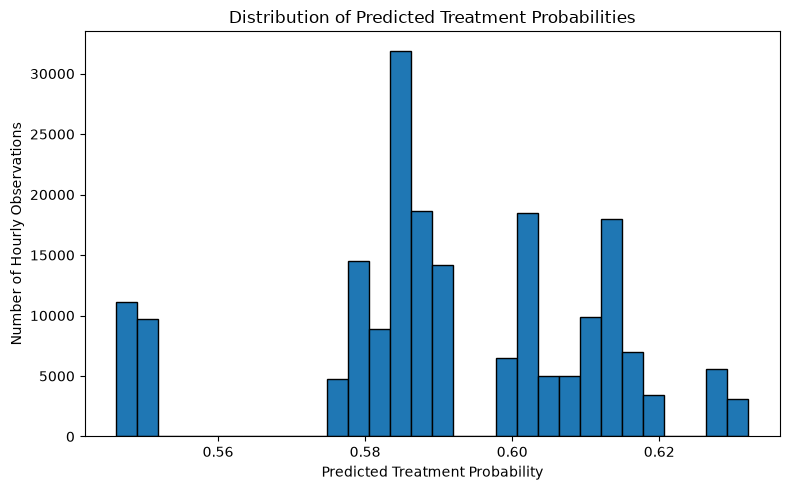

In [203]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    treatment_predictions,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Predicted Treatment Probability")
plt.ylabel("Number of Hourly Observations")
plt.title("Distribution of Predicted Treatment Probabilities")

plt.tight_layout()
plt.show()

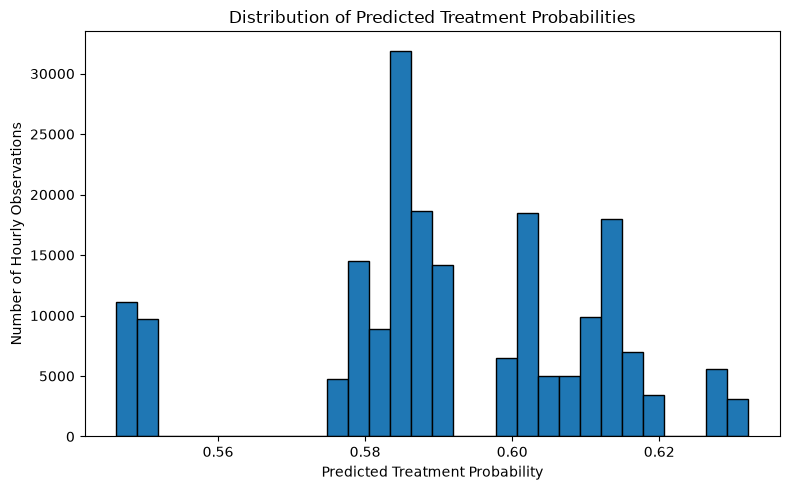

Histogram saved successfully.


In [204]:
plt.figure(figsize=(8, 5))

plt.hist(
    treatment_predictions,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Predicted Treatment Probability")
plt.ylabel("Number of Hourly Observations")
plt.title("Distribution of Predicted Treatment Probabilities")

plt.tight_layout()

plt.savefig(
    "../results/phase1_treatment_probability_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Histogram saved successfully.")

In [205]:
dml_data_model_a = pd.concat(
    [
        hourly_model_data[
            ["ID", "Demand_kWh", "Treatment_Assigned"]
        ].reset_index(drop=True),
        model_controls.reset_index(drop=True)
    ],
    axis=1
)

print("Model A dataset shape:", dml_data_model_a.shape)
print("Missing values:", dml_data_model_a.isna().sum().sum())
print("Unique households:", dml_data_model_a["ID"].nunique())

Model A dataset shape: (195888, 37)
Missing values: 0
Unique households: 742


In [206]:
dml_data_a = dml.DoubleMLData(
    dml_data_model_a,
    y_col="Demand_kWh",
    d_cols="Treatment_Assigned",
    x_cols=model_controls.columns.tolist(),
    cluster_cols="ID"
)

print("Outcome:", dml_data_a.y_col)
print("Treatment:", dml_data_a.d_cols)
print("Number of controls:", len(dml_data_a.x_cols))
print("Cluster columns:", dml_data_a.cluster_cols)
print("Is cluster data:", dml_data_a.is_cluster_data)

Outcome: Demand_kWh
Treatment: ['Treatment_Assigned']
Number of controls: 34
Cluster columns: ['ID']
Is cluster data: True


In [207]:
dml_plr_a = dml.DoubleMLPLR(
    dml_data_a,
    ml_l=ml_l,
    ml_m=ml_m,
    n_folds=5,
    n_rep=1
)

print("Model A created successfully.")
print("Number of folds:", dml_plr_a.n_folds)
print("Number of repetitions:", dml_plr_a.n_rep)
print("Cluster-aware:", dml_plr_a._is_cluster_data)

Model A created successfully.
Number of folds: 5
Number of repetitions: 1
Cluster-aware: True


In [208]:
dml_plr_a.draw_sample_splitting()

for fold, (train_idx, test_idx) in enumerate(
    dml_plr_a.smpls[0], start=1
):
    train_ids = set(dml_data_model_a.iloc[train_idx]["ID"])
    test_ids = set(dml_data_model_a.iloc[test_idx]["ID"])

    overlap = train_ids.intersection(test_ids)

    print(
        f"Fold {fold}: "
        f"Training households={len(train_ids)}, "
        f"Testing households={len(test_ids)}, "
        f"Overlap={len(overlap)}"
    )

Fold 1: Training households=593, Testing households=149, Overlap=0
Fold 2: Training households=593, Testing households=149, Overlap=0
Fold 3: Training households=594, Testing households=148, Overlap=0
Fold 4: Training households=594, Testing households=148, Overlap=0
Fold 5: Training households=594, Testing households=148, Overlap=0


In [209]:
dml_plr_a.fit()

print("Model A fitting completed successfully.")

print("\nModel A results:")
print(dml_plr_a.summary)

Model A fitting completed successfully.

Model A results:
                        coef   std err         t     P>|t|     2.5 %    97.5 %
Treatment_Assigned  0.079155  0.112536  0.703374  0.481823 -0.141411  0.299721


In [210]:
model_a_results = dml_plr_a.summary.copy()

model_a_results.to_csv(
    "../results/phase1_doubleml_model_a_results.csv"
)

print("Model A results saved successfully.")
print(model_a_results)

Model A results saved successfully.
                        coef   std err         t     P>|t|     2.5 %    97.5 %
Treatment_Assigned  0.079155  0.112536  0.703374  0.481823 -0.141411  0.299721


In [211]:
model_comparison = pd.concat(
    [
        model_a_results.assign(Model="Model A"),
        model_b_results.assign(Model="Model B")
    ]
)

model_comparison.index.name = "Treatment"

model_comparison.to_csv(
    "../results/phase1_doubleml_model_comparison.csv"
)

print("Model comparison saved successfully.")

print(
    model_comparison[
        ["Model", "coef", "std err", "P>|t|", "2.5 %", "97.5 %"]
    ]
)

Model comparison saved successfully.
                      Model      coef   std err     P>|t|     2.5 %    97.5 %
Treatment                                                                    
Treatment_Assigned  Model A  0.079155  0.112536  0.481823 -0.141411  0.299721
Treatment_Assigned  Model B  0.036781  0.111109  0.740618 -0.180989  0.254551


In [212]:
print("DoubleML inference-related methods:")

print([
    method for method in dir(dml_plr_b)
    if any(
        word in method.lower()
        for word in ["bootstrap", "confint", "se", "summary", "pval"]
    )
])

DoubleML inference-related methods:
['_DoubleML__all_se', '__setattr__', '_all_se', '_est_causal_pars_and_se', '_fit_sensitivity_elements', '_get_sensitivity_elements', '_initialize_sensitivity_elements', '_se', '_se_causal_pars', '_sensitivity_element_est', '_sensitivity_element_names', '_sensitivity_elements', '_sensitivity_implemented', '_sensitivity_params', '_set_score_elements', '_set_sensitivity_elements', '_solve_score_and_estimate_se', '_validate_optuna_setting_keys', '_validate_sensitivity_elements', 'all_se', 'bootstrap', 'confint', 'pval', 'se', 'sensitivity_analysis', 'sensitivity_benchmark', 'sensitivity_elements', 'sensitivity_params', 'sensitivity_plot', 'sensitivity_summary', 'set_ml_nuisance_params', 'set_sample_splitting', 'summary']


In [213]:
import inspect

print(inspect.signature(dml_plr_b.bootstrap))

print("\nBootstrap documentation:")
print(dml_plr_b.bootstrap.__doc__)

(method='normal', n_rep_boot=500)

Bootstrap documentation:

        Multiplier bootstrap for DoubleML models.

        Parameters
        ----------
        method : str
            A str (``'Bayes'``, ``'normal'`` or ``'wild'``) specifying the multiplier bootstrap method.
            Default is ``'normal'``

        n_rep_boot : int
            The number of bootstrap replications.

        Returns
        -------
        self : object
        


In [214]:
dml_plr_b.bootstrap(
    method="normal",
    n_rep_boot=500
)

print("Bootstrap completed.")

print("\nBootstrap standard errors:")
print(dml_plr_b.boot_t_stat.shape)

print("\nBootstrap t-statistics:")
print(dml_plr_b.boot_t_stat[:10])

NotImplementedError: bootstrap not yet implemented with clustering.

In [215]:
print("Model A standard error:")
print(dml_plr_a.se)

print("\nModel B standard error:")
print(dml_plr_b.se)

print("\nModel A confidence interval:")
print(dml_plr_a.confint())

print("\nModel B confidence interval:")
print(dml_plr_b.confint())

Model A standard error:
[0.1125357]

Model B standard error:
[0.11110925]

Model A confidence interval:
                       2.5 %    97.5 %
Treatment_Assigned -0.141411  0.299721

Model B confidence interval:
                       2.5 %    97.5 %
Treatment_Assigned -0.180989  0.254551


In [216]:
date_assignment_check = (
    hourly_model_data
    .groupby(["Date", "Treatment_Assigned"])["ID"]
    .nunique()
    .unstack(fill_value=0)
)

date_assignment_check.columns = [
    "Control_Households",
    "Treatment_Households"
]

print(date_assignment_check)

print("\nNumber of experiment dates:", len(date_assignment_check))

            Control_Households  Treatment_Households
Date                                                
2020-02-11                 303                   439
2020-02-12                 303                   439
2020-02-13                 303                   439
2020-02-14                 303                   439
2020-02-19                 303                   439
2020-02-27                 303                   439
2020-03-02                 303                   439
2020-03-03                 303                   439
2020-03-04                 303                   439
2020-03-05                 303                   439
2020-03-09                 303                   439

Number of experiment dates: 11


In [217]:
exposure_summary = (
    hourly_model_data
    .groupby("Treatment_Assigned")["Signal_Received"]
    .agg(["count", "sum", "mean"])
)

exposure_summary.index = [
    "Control" if x == 0 else "Treatment"
    for x in exposure_summary.index
]

exposure_summary["Exposure_Percentage"] = (
    exposure_summary["mean"] * 100
)

print(exposure_summary.round(3))

            count    sum   mean  Exposure_Percentage
Control     79992      0  0.000                 0.00
Treatment  115896  68448  0.591                59.06


In [218]:
exposure_by_date = (
    hourly_model_data
    .groupby("Date")
    .agg(
        Total_Observations=("ID", "size"),
        Signal_Observations=("Signal_Received", "sum")
    )
)

exposure_by_date["Exposure_Percentage"] = (
    exposure_by_date["Signal_Observations"]
    / exposure_by_date["Total_Observations"]
    * 100
)

print(exposure_by_date.round(2))

            Total_Observations  Signal_Observations  Exposure_Percentage
Date                                                                    
2020-02-11               17808                 5256                29.51
2020-02-12               17808                 5256                29.51
2020-02-13               17808                10536                59.16
2020-02-14               17808                 5256                29.51
2020-02-19               17808                 5280                29.65
2020-02-27               17808                 5280                29.65
2020-03-02               17808                 5256                29.51
2020-03-03               17808                10536                59.16
2020-03-04               17808                 5256                29.51
2020-03-05               17808                 5256                29.51
2020-03-09               17808                 5280                29.65


In [219]:
treatment_exposure_by_date = (
    hourly_model_data[
        hourly_model_data["Treatment_Assigned"] == 1
    ]
    .groupby("Date")
    .agg(
        Treatment_Observations=("ID", "size"),
        Signal_Observations=("Signal_Received", "sum")
    )
)

treatment_exposure_by_date["Exposure_Percentage"] = (
    treatment_exposure_by_date["Signal_Observations"]
    / treatment_exposure_by_date["Treatment_Observations"]
    * 100
)

print(treatment_exposure_by_date.round(2))

            Treatment_Observations  Signal_Observations  Exposure_Percentage
Date                                                                        
2020-02-11                   10536                 5256                49.89
2020-02-12                   10536                 5256                49.89
2020-02-13                   10536                10536               100.00
2020-02-14                   10536                 5256                49.89
2020-02-19                   10536                 5280                50.11
2020-02-27                   10536                 5280                50.11
2020-03-02                   10536                 5256                49.89
2020-03-03                   10536                10536               100.00
2020-03-04                   10536                 5256                49.89
2020-03-05                   10536                 5256                49.89
2020-03-09                   10536                 5280                50.11

In [220]:
subgroup_exposure = (
    hourly_model_data[
        hourly_model_data["Treatment_Assigned"] == 1
    ]
    .groupby("Group_Phase1")["Signal_Received"]
    .agg(["count", "sum", "mean"])
)

subgroup_exposure["Exposure_Percentage"] = (
    subgroup_exposure["mean"] * 100
)

print(subgroup_exposure.round(3))

KeyError: 'Group_Phase1'

In [221]:
print(hourly_model_data.columns.tolist())

['ID', 'Date', 'Hour', 'Demand_kWh', 'Treatment_Assigned', 'Signal_Received', 'Temperature']


In [222]:
print(participants.columns.tolist())

['ID', 'Participation_Experiment', 'Recruitment_organisation', 'Municipality', 'Region', 'Survey1_answered', 'Survey2_answered', 'Survey3_answered', 'Participation_Phase', 'Control_Price_Phase1', 'Control_Price_Phase2', 'Group_Phase1', 'Group_Phase2', 'Participation_status_Phase1', 'Participation_status_Phase2']


In [223]:
phase1_groups = participants[["ID", "Group_Phase1"]].copy()

hourly_model_data = hourly_model_data.merge(
    phase1_groups,
    on="ID",
    how="left",
    validate="many_to_one"
)

print(hourly_model_data["Group_Phase1"].value_counts(dropna=False))

Group_Phase1
Control    79992
H2         58080
H1         57816
Name: count, dtype: int64


In [224]:
subgroup_exposure = (
    hourly_model_data[
        hourly_model_data["Group_Phase1"].isin(["H1", "H2"])
    ]
    .groupby("Group_Phase1")["Signal_Received"]
    .agg(["count", "sum", "mean"])
)

subgroup_exposure["Exposure_Percentage"] = (
    subgroup_exposure["mean"] * 100
)

print(subgroup_exposure.round(3))

              count    sum   mean  Exposure_Percentage
Group_Phase1                                          
H1            57816  42048  0.727               72.727
H2            58080  26400  0.455               45.455


In [225]:
consumption_by_group = (
    hourly_model_data
    .groupby("Group_Phase1")["Demand_kWh"]
    .agg(["count", "mean", "std", "median"])
)

print(consumption_by_group.round(3))

              count   mean    std  median
Group_Phase1                             
Control       79992  2.499  1.770   2.265
H1            57816  2.579  1.899   2.301
H2            58080  2.581  1.954   2.242


In [226]:
hourly_group_consumption = (
    hourly_model_data
    .groupby(["Hour", "Group_Phase1"])["Demand_kWh"]
    .mean()
    .unstack()
)

print(hourly_group_consumption.round(3))

Group_Phase1  Control     H1     H2
Hour                               
1               2.258  2.419  2.394
2               2.134  2.305  2.256
3               2.107  2.245  2.198
4               2.109  2.230  2.201
5               2.164  2.266  2.221
6               2.213  2.353  2.323
7               2.557  2.669  2.548
8               2.821  2.981  2.917
9               2.712  2.772  2.885
10              2.601  2.580  2.739
11              2.477  2.480  2.551
12              2.358  2.354  2.440
13              2.268  2.292  2.357
14              2.238  2.256  2.308
15              2.213  2.305  2.331
16              2.352  2.408  2.434
17              2.613  2.622  2.585
18              2.824  2.808  2.759
19              2.919  2.938  3.000
20              2.913  2.956  3.001
21              2.940  2.987  3.029
22              2.897  3.091  2.989
23              2.778  2.936  2.852
24              2.504  2.644  2.625


FileNotFoundError: [Errno 2] No such file or directory: 'results/phase1_hourly_consumption_by_group.png'

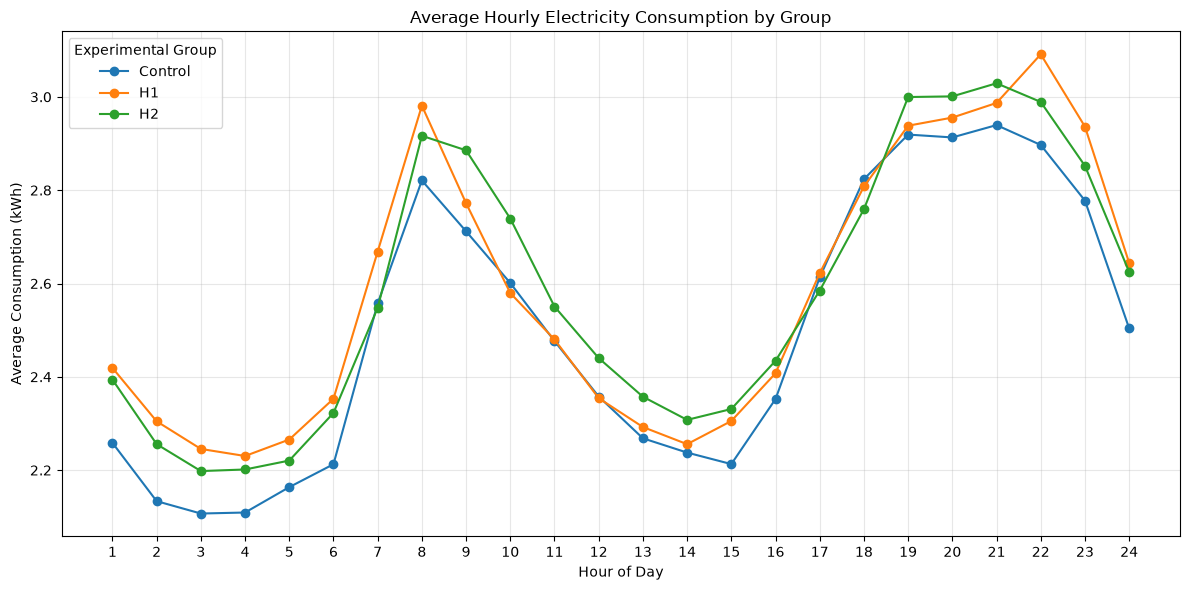

In [227]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for group in ["Control", "H1", "H2"]:
    plt.plot(
        hourly_group_consumption.index,
        hourly_group_consumption[group],
        marker="o",
        label=group
    )

plt.title("Average Hourly Electricity Consumption by Group")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (kWh)")
plt.xticks(range(1, 25))
plt.legend(title="Experimental Group")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/phase1_hourly_consumption_by_group.png",
    dpi=300
)

plt.show()

In [228]:
plt.savefig(
    "results/phase1_hourly_consumption_by_group.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'results/phase1_hourly_consumption_by_group.png'

<Figure size 640x480 with 0 Axes>

FileNotFoundError: [Errno 2] No such file or directory: 'results/phase1_hourly_consumption_by_group.png'

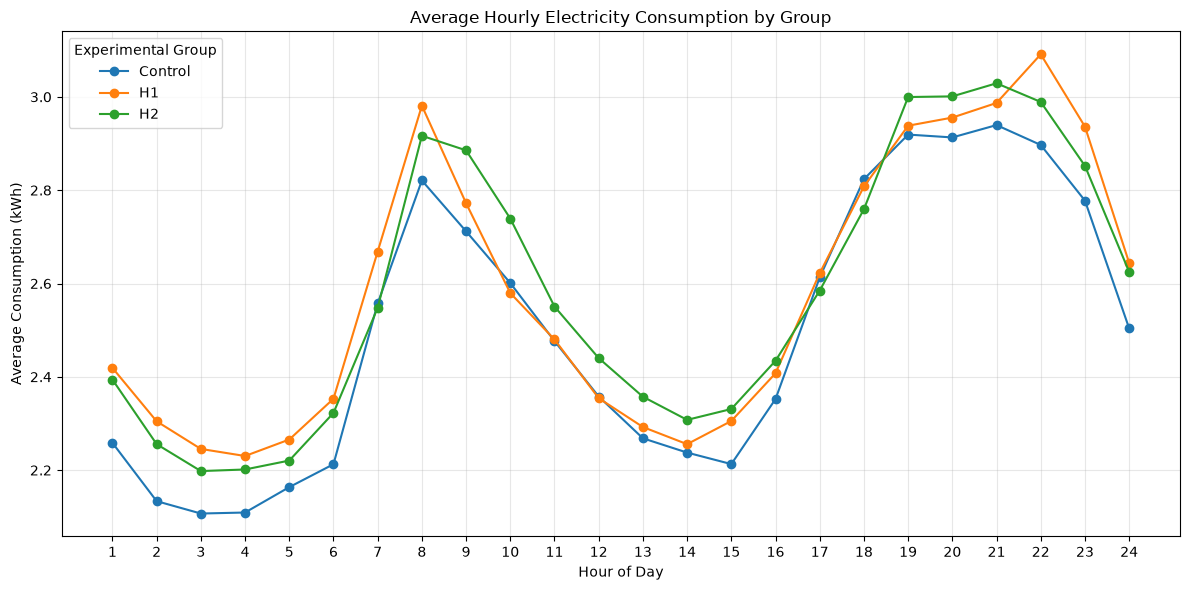

In [229]:
fig, ax = plt.subplots(figsize=(12, 6))

for group in ["Control", "H1", "H2"]:
    ax.plot(
        hourly_group_consumption.index,
        hourly_group_consumption[group],
        marker="o",
        label=group
    )

ax.set_title("Average Hourly Electricity Consumption by Group")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Consumption (kWh)")
ax.set_xticks(range(1, 25))
ax.legend(title="Experimental Group")
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    "results/phase1_hourly_consumption_by_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [230]:
from pathlib import Path

print("Current notebook working directory:")
print(Path.cwd())

print("\nDoes the results folder exist here?")
print(Path("results").exists())

Current notebook working directory:
c:\Users\KOTHEPETA ABHINAV\OneDrive\Desktop\economical\notebooks

Does the results folder exist here?
False
